In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import os
import tqdm
import matplotlib.pylab as plt
import re

from scipy.signal import find_peaks
from scipy.stats import linregress

from pathlib import Path

import tkinter as tk

from scipy.signal import savgol_filter
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg
from scipy.optimize import differential_evolution

In [ ]:
class CClamp:
    def __init__(self, df):
        self.df = df.copy() #Once data is loaded, al information is tracked in a singular df; all relevant methods update the df

    @classmethod
    def load_data_singleFile(cls, filepath, cclamp_only=True): # data-loader method, single-file
        df = pd.read_pickle(filepath)
        if cclamp_only: #default behavior should get rid of anything else, like voltage-clamp data
            df['fpath'] = filepath
            df = df[df.series_name.isin(['Rudi', 'Garrett'])].reset_index(drop=True) # method mkaes an assumption about protocol names, can be easily modified here (replace rudi and garrett)
        else:
            df['fpath'] = filepath
        return cls(df)

    @classmethod
    def load_data_batchFolder(cls, folder, cclamp_only=True): # data-loader method, batch load
        files = Path(folder).glob('*.pkl')
        dfs = []
        for f in files:
            tmp = pd.read_pickle(f)
            tmp['fpath'] = f
            dfs.append(tmp)

        if cclamp_only:
            conc = pd.concat(dfs).reset_index(drop=True)
            conc = conc[conc.series_name.isin(['Rudi', 'Garrett'])].reset_index(drop=True) # method mkaes an assumption about protocol names, can be easily modified here (replace rudi and garrett)
        else:
            conc = pd.concat(dfs).reset_index(drop=True)
        return cls(conc)

    def correct_holding_v_and_update_injections(self):
        
        self.df['V_hold_mV'] = np.array(self.df.Vhold)*1e12
        injections = []
        corr_injections = []
        for i in range(len(self.df)):
            arrs = self.df.iloc[i].stimWave.T
            hold = self.df.iloc[i].Vhold*1e12
            tmp = []
            tmp2 = []
            for arr in arrs:
                tmp.append(arr[len(arr)//2]*1000)
                tmp2.append(arr[len(arr)//2]*1000 - hold)
            injections.append(tmp)
            corr_injections.append(tmp2)
        self.df['current_injections'] = [x for x in injections]
        self.df['corrected_injections'] = [x for x in corr_injections]


        def get_date(stri): #quick search function
            return stri[:stri.find('struct')]

        # get the combo info, this makes it easier to identify unique cells or series (and for GLMMs at some point)
        combo = []
        for i in range(len(self.df)):
            date = get_date(self.df.iloc[i].fname)
            combo.append(date+'_'+str(self.df.iloc[i].experiment)+'_'+str(self.df.iloc[i].series_num))
        self.df['combo'] = combo

        return self

    def plot_trace(self, cell_id = None, sr=40000, distance = 250, height_factor=50, show_peaks = True):
        #cell_id is based on the combo variable!!

        if cell_id is None:
            print(self.df.combo.unique())
            return

        tmp = self.df[self.df.combo == cell_id].reset_index(drop=True)

        arrs = tmp.rawData.T
        currs = tmp.corrected_injections
        for idx, arr in enumerate(arrs):
            plt.plot(arr, label = round(currs[0][idx], 2))
        plt.legend(title='current injections', bbox_to_anchor=(1.2,1))

        plt.ylabel('Voltage')

        time_ticks, _ = plt.xticks()

        plt.xticks(
            time_ticks,
            [f"{x / sr:.2f}" for x in time_ticks]
        )
        plt.margins(x=0)
        plt.title('Current clamp run for '+cell_id)
        plt.show()

        if show_peaks:
            from scipy.signal import find_peaks
            arrs = tmp.rawData.iloc[0].T
            print(arrs)
            wind=10500
            mid = len(arr)//2

            height = np.mean(arr[mid-200:mid+200]) + np.std(arr[mid-200:mid+200])*height_factor
            plt.axhline(height)
            #arrs = arrs.values[0]
            peak_freq = []
            for idx, arr in enumerate(arrs):
                peaks, _ = find_peaks(arr, height=height, distance=distance)
                mid = len(arr) // 2
                lower = mid - 10500
                upper = mid + 10500
                peaks = peaks[(peaks >= lower) & (peaks <= upper)]
                plt.plot(peaks, arr[peaks], 'x', c='r')
                plt.plot(arr)
                peak_freq.append(len(peaks)/.5)

            plt.show()

            plt.plot(currs[0], peak_freq)
            plt.title('FI plot for '+cell_id)

        return

    def detect_peaks(self, wind=10500, threshold_sd=100, distance=250, plot_all=True):
        all_freqs = []
        all_peaks = []

        for i in range(len(self.df)):

            tmp = self.df.iloc[i]
            arrs = tmp.rawData.T

            peak_freqs = []
            peakies = []

            for arr in arrs:

                mid = len(arr) // 2

                height = (
                    np.mean(arr[mid-200:mid+200])
                    + np.std(arr[mid-200:mid+200]) * threshold_sd
                )

                peaks, _ = find_peaks(
                    arr[mid-wind:mid+wind],
                    height=height,
                    distance=distance
                )

                # Convert slice-relative indices back to original array indices
                peaks += mid - wind

                # Keep only positive peaks
                peaks = peaks[arr[peaks] > 0]

                peak_freqs.append(len(peaks) / 0.5)
                peakies.append(peaks)

            all_freqs.append(peak_freqs)
            all_peaks.append(peakies)

        self.df['all_freqs'] = all_freqs
        self.df['all_peaks'] = all_peaks

        if plot_all:
            for i in range(len(self.df)):
                tmp = self.df.iloc[i]

                arrs = tmp.rawData.T
                peaks = tmp.all_peaks

                for idx, arr in enumerate(arrs):
                    ps = peaks[idx]
                    plt.plot(arr, c='k', alpha=.3)
                    plt.plot(ps, arr[ps], 'x', c='r')
                    plt.title('plotting ' + tmp.combo)

        return self

    from scipy.stats import linregress
    import numpy as np
    import matplotlib.pyplot as plt


    def calculate_ssv_ir(self, plot=False, ssv_window=7500, baseline_end=35000):
        
        all_ssvs = []
        all_ssvs_corr = []
        IR_slope = []

        for row_idx in range(len(self.df)):

            tmp = self.df.iloc[row_idx]

            peak_list = tmp.all_peaks
            raw_data = tmp.rawData.T
            curr_injs = np.asarray(tmp.corrected_injections)

            # Find the first current injection with no detected peaks.
            # Only keep traces before that point.
            cutoff = len(peak_list)

            for trace_idx, peaks in enumerate(peak_list):
                if len(peaks) != 0:
                    cutoff = trace_idx
                    break

            peak_list = peak_list[:cutoff]
            raw_data = raw_data[:cutoff]
            curr_injs = curr_injs[:cutoff]

            if plot:
                for arr in raw_data:
                    plt.plot(arr)

                plt.title(tmp.combo)
                plt.show()

            ssvs = []
            ssvs_corr = []

            for arr in raw_data:

                mid = len(arr) // 2

                # SSV measurement window
                ssv_start = mid - ssv_window
                ssv_end = mid + ssv_window

                ssv = np.median(arr[ssv_start:ssv_end])
                baseline = np.median(arr[:baseline_end])

                ssvs.append(ssv)
                ssvs_corr.append(ssv - baseline)

            all_ssvs.append(ssvs)
            all_ssvs_corr.append(ssvs_corr)

            # Convert to arrays for regression
            curr_injs = np.asarray(curr_injs)
            ssvs_corr = np.asarray(ssvs_corr)

            model = linregress(curr_injs, ssvs_corr)

            if plot:
                plt.plot(curr_injs, ssvs_corr)
                plt.scatter(curr_injs, ssvs_corr)

                plt.plot(
                    curr_injs,
                    model.intercept + model.slope * curr_injs,
                    c='r',
                    label=f'IR slope = {model.slope * 1e6:.3f} MΩ'
                )

                plt.axhline(0, c='k', ls=':')
                plt.axvline(0, c='k', ls=':')

                plt.ylabel('Delta Voltage')
                plt.xlabel('Delta Current')
                plt.legend()
                plt.title(tmp.combo)
                plt.show()

            # V / I gives Ohms; convert to MΩ
            IR_slope.append(model.slope * 1e6)

        self.df['ssvs'] = all_ssvs
        self.df['ssvs_delta'] = all_ssvs_corr
        self.df['IR_slope'] = IR_slope

        return self


    from scipy.signal import savgol_filter
    import numpy as np
    import matplotlib.pyplot as plt


    def calculate_rheo_ap_metrics(self, plot=False, use_smoothed=True, wind=350, smooth_window=25, smooth_polyorder=3):

        waves = []
        smoothed_waves = []
        max_dvdt = []
        min_dvdt = []
        dvdt_ratio = []
        voltage_at_max_dvdt = []
        voltage_at_min_dvdt = []

        for row_idx in range(len(self.df)):

            tmp = self.df.iloc[row_idx]

            arrs = tmp.rawData.T
            peaks = tmp.all_peaks

            if plot:
                for idx, arr in enumerate(arrs):
                    ps = peaks[idx]

                    plt.plot(
                        arr,
                        c='k',
                        alpha=.3
                    )

                    plt.plot(
                        ps,
                        arr[ps],
                        'x',
                        c='r'
                    )

                plt.show()

            # Get the rheobase:
            # the first injection that contains an AP
            for trace_idx, peak in enumerate(peaks):
                if len(peak) != 0:
                    break

            rheo = arrs[trace_idx]

            # Check whether this series contains any APs
            try:
                peak = peak[0]

            except:
                print(
                    tmp.combo
                    + ' did not have any detected peaks, skipped and NaN-filled'
                )

                max_dvdt.append(np.nan)
                min_dvdt.append(np.nan)
                dvdt_ratio.append(np.nan)
                voltage_at_max_dvdt.append(np.nan)
                voltage_at_min_dvdt.append(np.nan)
                waves.append(np.nan)
                smoothed_waves.append(np.nan)

                continue

            if plot:
                plt.plot(
                    peak,
                    rheo[peak],
                    'x'
                )

                plt.plot(rheo)
                plt.show()

            # Extract AP waveform around the detected peak
            wave = rheo[
                peak - wind + 100:
                peak + wind
            ]

            # Savitzky-Golay smoothing
            smoothed = savgol_filter(
                wave,
                window_length=smooth_window,
                polyorder=smooth_polyorder
            )

            if plot:
                plt.plot(wave)
                plt.plot(smoothed)
                plt.show()

                plt.plot(
                    smoothed,
                    np.gradient(smoothed)
                )

            # Select raw or smoothed waveform for dv/dt calculations
            if use_smoothed:
                analysis_wave = smoothed
            else:
                analysis_wave = wave

            gradient = np.gradient(analysis_wave)

            max_dvdt_value = np.max(gradient)
            min_dvdt_value = np.min(gradient)

            max_idx = np.argmax(gradient)
            min_idx = np.argmin(gradient)

            max_dvdt.append(max_dvdt_value)
            min_dvdt.append(min_dvdt_value)

            dvdt_ratio.append(
                max_dvdt_value / abs(min_dvdt_value)
            )

            voltage_at_max_dvdt.append(
                analysis_wave[max_idx]
            )

            voltage_at_min_dvdt.append(
                analysis_wave[min_idx]
            )

            waves.append(wave)
            smoothed_waves.append(smoothed)

        # Add results to the dataframe
        self.df['rheo_AP_trace'] = waves
        self.df['smoothed_rheo_AP_trace'] = smoothed_waves
        self.df['max_dvdt'] = max_dvdt
        self.df['min_dvdt'] = min_dvdt
        self.df['dvdt_ratio'] = dvdt_ratio
        self.df['voltage_at_max_dvdt'] = voltage_at_max_dvdt
        self.df['voltage_at_min_dvdt'] = voltage_at_min_dvdt

        return self


    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.optimize import differential_evolution
    from scipy.signal import savgol_filter


    def calculate_ap_decay_tau(
        self,
        plot=False,
        wind=350,
        sampling_rate=40000,
        smooth_window=25,
        smooth_polyorder=3,
        tau_bounds=(0.05, 10),
        seed=1
    ):

        def exp_decay(t, A, tau, C):
            return A * np.exp(-t / tau) + C

        def decay_error(params, t, voltage):
            A, tau, C = params

            fitted = exp_decay(t, A, tau, C)

            return np.sum((voltage - fitted) ** 2)

        A_fits = []
        tau_fits = []
        C_fits = []

        for row_idx in range(len(self.df)):

            tmp = self.df.iloc[row_idx]

            arrs = tmp.rawData.T
            peaks = tmp.all_peaks

            # Get the rheobase:
            # the first injection that contains an AP
            for trace_idx, peak in enumerate(peaks):
                if len(peak) != 0:
                    break

            rheo = arrs[trace_idx]

            # Check for series with no detected APs
            try:
                peak = peak[0]

            except:
                print(
                    tmp.combo
                    + ' did not have any detected peaks, '
                    + 'skipped and NaN-filled'
                )

                A_fits.append(np.nan)
                tau_fits.append(np.nan)
                C_fits.append(np.nan)

                continue

            # Extract AP waveform
            wave = rheo[
                peak - wind + 100:
                peak + wind
            ]

            # Light Savitzky-Golay smoothing
            smoothed = savgol_filter(
                wave,
                window_length=smooth_window,
                polyorder=smooth_polyorder
            )

            # Find AP peak in extracted/smoothed waveform
            peak_idx = np.argmax(smoothed)

            # Take everything after the AP peak
            decay = smoothed[peak_idx:]

            # Time in ms
            dt = 1000 / sampling_rate
            t = np.arange(len(decay)) * dt

            # --------------------------------------------------
            # Bounds for A, tau, C
            # --------------------------------------------------

            peak_voltage = decay[0]
            end_voltage = decay[-1]

            voltage_range = peak_voltage - end_voltage

            bounds = [
                (
                    0.1 * voltage_range,
                    2 * voltage_range
                ),                                      # A

                tau_bounds,                             # tau (ms)

                (
                    end_voltage - voltage_range,
                    end_voltage + 0.25 * voltage_range
                )                                       # C
            ]

            # --------------------------------------------------
            # Differential evolution
            # --------------------------------------------------

            result = differential_evolution(
                decay_error,
                bounds=bounds,
                args=(t, decay),
                seed=seed,
                strategy='rand1exp',
                polish=True
            )

            A_fit, tau_fit, C_fit = result.x

            A_fits.append(A_fit)
            tau_fits.append(tau_fit)
            C_fits.append(C_fit)

            # --------------------------------------------------
            # Plot
            # --------------------------------------------------

            if plot:

                fit = exp_decay(
                    t,
                    A_fit,
                    tau_fit,
                    C_fit
                )

                plt.figure()

                plt.plot(
                    smoothed,
                    label='Smoothed AP',
                    c='b'
                )

                # Show the portion being fitted
                plt.plot(
                    peak_idx + np.arange(len(decay)),
                    decay,
                    c='r',
                    label='AP decay'
                )

                # Put fitted curve back into AP coordinates
                plt.plot(
                    peak_idx + np.arange(len(fit)),
                    fit,
                    c='k',
                    label=f'Exponential fit (τ = {tau_fit:.3f} ms)'
                )

                plt.xlabel('Samples')
                plt.ylabel('Voltage')
                plt.legend()
                plt.title(tmp.combo)
                plt.show()

        # Add results to dataframe
        self.df['A_fit'] = A_fits
        self.df['tau_fit'] = tau_fits
        self.df['C_fit'] = C_fits

        return self

    def _select_ap_points(self, smoothed, sampling_rate=40000):

            smoothed = np.asarray(smoothed)
            x = np.arange(len(smoothed))

            dt = 1000 / sampling_rate  # ms/sample

            root = tk.Tk()
            root.title("Select AP Threshold and AHP")

            fig = Figure(figsize=(10, 5))
            ax = fig.add_subplot(111)

            ax.plot(x * dt, smoothed)

            ax.set_xlabel("Time (ms)")
            ax.set_ylabel("Voltage (mV)")
            ax.set_title("Click THRESHOLD, then AHP")

            canvas = FigureCanvasTkAgg(
                fig,
                master=root
            )

            canvas.draw()
            canvas.get_tk_widget().pack(
                fill=tk.BOTH,
                expand=True
            )

            # --------------------------------------------------------
            # Store selected sample indices
            # --------------------------------------------------------

            threshold_idx = None
            ahp_idx = None

            threshold_marker = None
            ahp_marker = None

            # --------------------------------------------------------
            # Update markers
            # --------------------------------------------------------

            def update_markers():

                nonlocal threshold_marker, ahp_marker

                if threshold_marker is not None:
                    threshold_marker.remove()

                if ahp_marker is not None:
                    ahp_marker.remove()

                # Threshold
                if threshold_idx is not None:

                    threshold_marker, = ax.plot(
                        threshold_idx * dt,
                        smoothed[threshold_idx],
                        'o',
                        markersize=8,
                        label='Threshold'
                    )

                # AHP
                if ahp_idx is not None:

                    ahp_marker, = ax.plot(
                        ahp_idx * dt,
                        smoothed[ahp_idx],
                        'o',
                        markersize=8,
                        label='AHP'
                    )

                if threshold_idx is not None or ahp_idx is not None:
                    ax.legend()

                canvas.draw()

            # --------------------------------------------------------
            # Mouse click
            # --------------------------------------------------------

            def onclick(event):

                nonlocal threshold_idx, ahp_idx

                if event.inaxes != ax:
                    return

                if event.xdata is None:
                    return

                # Convert clicked time to nearest sample
                clicked_idx = int(
                    np.clip(
                        np.round(event.xdata / dt),
                        0,
                        len(smoothed) - 1
                    )
                )

                # First click = threshold
                if threshold_idx is None:

                    threshold_idx = clicked_idx

                    ax.set_title(
                        "Threshold selected — click AHP"
                    )

                # Second click = AHP
                elif ahp_idx is None:

                    ahp_idx = clicked_idx

                    ax.set_title(
                        "Review points — click to adjust, "
                        "then Commit"
                    )

                # Subsequent clicks adjust whichever
                # existing point is closer
                else:

                    distance_threshold = abs(
                        clicked_idx - threshold_idx
                    )

                    distance_ahp = abs(
                        clicked_idx - ahp_idx
                    )

                    if distance_threshold <= distance_ahp:
                        threshold_idx = clicked_idx
                    else:
                        ahp_idx = clicked_idx

                update_markers()

            # --------------------------------------------------------
            # Commit
            # --------------------------------------------------------

            def commit():

                if threshold_idx is None or ahp_idx is None:

                    ax.set_title(
                        "Please select both Threshold and AHP "
                        "before committing"
                    )

                    canvas.draw()

                    return

                root.quit()
                root.destroy()

            canvas.mpl_connect(
                'button_press_event',
                onclick
            )

            # --------------------------------------------------------
            # Commit button
            # --------------------------------------------------------

            button_frame = tk.Frame(root)
            button_frame.pack(pady=5)

            commit_button = tk.Button(
                button_frame,
                text="Commit",
                command=commit,
                width=15
            )

            commit_button.pack()

            root.mainloop()

            # --------------------------------------------------------
            # Return results
            # --------------------------------------------------------

            if threshold_idx is None or ahp_idx is None:

                return {
                    'AHP_time': np.nan,
                    'AHP_voltage': np.nan,
                    'Threshold_time': np.nan,
                    'Threshold_voltage': np.nan
                }

            return {
                'AHP_time': ahp_idx * dt,
                'AHP_voltage': smoothed[ahp_idx],
                'Threshold_time': threshold_idx * dt,
                'Threshold_voltage': smoothed[threshold_idx]
            }

        # ============================================================
        # Loop through dataframe and annotate APs
        # ============================================================

    def annotate_ap_points(
        self,
        wind=350,
        smooth_window=25,
        smooth_polyorder=3,
        sampling_rate=40000
    ):

        AHP_times = []
        AHP_voltages = []
        Threshold_times = []
        Threshold_voltages = []

        for row_idx in range(len(self.df)):

            row = self.df.iloc[row_idx]

            arrs = row.rawData.T
            peaks = row.all_peaks

            # ----------------------------------------------------
            # Find rheobase
            # ----------------------------------------------------

            rheo_idx = None
            rheo_peak = None

            for trace_idx, peak in enumerate(peaks):

                if len(peak) != 0:

                    rheo_idx = trace_idx
                    rheo_peak = peak
                    break

            # ----------------------------------------------------
            # No AP detected
            # ----------------------------------------------------

            if rheo_idx is None:

                print(
                    row.combo +
                    ' did not have any detected peaks, '
                    'skipped and NaN-filled'
                )

                AHP_times.append(np.nan)
                AHP_voltages.append(np.nan)
                Threshold_times.append(np.nan)
                Threshold_voltages.append(np.nan)

                continue

            rheo = arrs[rheo_idx]

            try:
                peak = rheo_peak[0]

            except Exception:

                print(
                    row.combo +
                    ' did not have any detected peaks, '
                    'skipped and NaN-filled'
                )

                AHP_times.append(np.nan)
                AHP_voltages.append(np.nan)
                Threshold_times.append(np.nan)
                Threshold_voltages.append(np.nan)

                continue

            # ----------------------------------------------------
            # Extract AP
            # ----------------------------------------------------

            wave = rheo[
                peak - wind + 100:
                peak + wind
            ]

            # ----------------------------------------------------
            # Smooth
            # ----------------------------------------------------

            smoothed = savgol_filter(
                wave,
                window_length=smooth_window,
                polyorder=smooth_polyorder
            )

            # ----------------------------------------------------
            # Open GUI
            # ----------------------------------------------------

            result = self._select_ap_points(
                smoothed,
                sampling_rate=sampling_rate
            )

            # ----------------------------------------------------
            # Store results
            # ----------------------------------------------------

            AHP_times.append(
                result['AHP_time']
            )

            AHP_voltages.append(
                result['AHP_voltage']
            )

            Threshold_times.append(
                result['Threshold_time']
            )

            Threshold_voltages.append(
                result['Threshold_voltage']
            )

        # ========================================================
        # Update self.df
        # ========================================================

        self.df['AHP_time'] = AHP_times
        self.df['AHP_voltage'] = AHP_voltages
        self.df['Threshold_time'] = Threshold_times
        self.df['Threshold_voltage'] = Threshold_voltages

        return self


    import numpy as np
    import matplotlib.pyplot as plt
    from scipy.signal import savgol_filter


    def calculate_ap_half_width(
        self,
        plot=False,
        wind=350,
        smooth_window=25,
        smooth_polyorder=3,
        sampling_rate=40000
    ):

        half_widths = []

        dt = 1000 / sampling_rate  # ms/sample

        for row_idx in range(len(self.df)):

            row = self.df.iloc[row_idx]

            arrs = row.rawData.T
            peaks = row.all_peaks

            # --------------------------------------------------
            # Find rheobase = first trace containing an AP
            # --------------------------------------------------

            rheo_idx = None
            rheo_peaks = None

            for trace_idx, peak in enumerate(peaks):

                if len(peak) != 0:
                    rheo_idx = trace_idx
                    rheo_peaks = peak
                    break

            # --------------------------------------------------
            # No AP
            # --------------------------------------------------

            if rheo_idx is None:

                print(
                    row.combo +
                    ' did not have any detected peaks, '
                    'skipped and NaN-filled'
                )

                half_widths.append(np.nan)
                continue

            rheo = arrs[rheo_idx]

            try:
                peak = rheo_peaks[0]

            except Exception:

                print(
                    row.combo +
                    ' did not have any detected peaks, '
                    'skipped and NaN-filled'
                )

                half_widths.append(np.nan)
                continue

            # --------------------------------------------------
            # Extract and smooth AP
            # --------------------------------------------------

            wave = rheo[
                peak - wind + 100:
                peak + wind
            ]

            smoothed = savgol_filter(
                wave,
                window_length=smooth_window,
                polyorder=smooth_polyorder
            )

            # --------------------------------------------------
            # Find AP peak
            # --------------------------------------------------

            peak_idx = np.argmax(smoothed)
            peak_voltage = smoothed[peak_idx]

            # --------------------------------------------------
            # Threshold voltage
            # --------------------------------------------------

            threshold_voltage = row.Threshold_voltage

            if np.isnan(threshold_voltage):

                half_widths.append(np.nan)
                continue

            # --------------------------------------------------
            # Calculate half-amplitude voltage
            # --------------------------------------------------

            half_voltage = (
                threshold_voltage
                + (peak_voltage - threshold_voltage) / 2
            )

            # --------------------------------------------------
            # Rising crossing
            # --------------------------------------------------

            rising = smoothed[:peak_idx + 1]

            below = np.where(rising < half_voltage)[0]

            if len(below) == 0:

                half_widths.append(np.nan)
                continue

            rising_idx = below[-1]

            # Make sure there is a point after it
            if rising_idx + 1 >= len(smoothed):

                half_widths.append(np.nan)
                continue

            # Linear interpolation
            x1 = rising_idx
            x2 = rising_idx + 1

            y1 = smoothed[x1]
            y2 = smoothed[x2]

            rising_crossing = x1 + (
                (half_voltage - y1) / (y2 - y1)
            )

            # --------------------------------------------------
            # Falling crossing
            # --------------------------------------------------

            falling = smoothed[peak_idx:]

            below = np.where(falling < half_voltage)[0]

            if len(below) == 0:

                half_widths.append(np.nan)
                continue

            falling_idx = peak_idx + below[0]

            if falling_idx - 1 < 0:

                half_widths.append(np.nan)
                continue

            # Linear interpolation
            x1 = falling_idx - 1
            x2 = falling_idx

            y1 = smoothed[x1]
            y2 = smoothed[x2]

            falling_crossing = x1 + (
                (half_voltage - y1) / (y2 - y1)
            )

            # --------------------------------------------------
            # Calculate half-width
            # --------------------------------------------------

            half_width = (
                falling_crossing - rising_crossing
            ) * dt

            half_widths.append(half_width)

            # --------------------------------------------------
            # Plot
            # --------------------------------------------------

            if plot:

                time = np.arange(len(smoothed)) * dt

                plt.figure(figsize=(8, 4))

                plt.plot(
                    time,
                    smoothed,
                    label='Smoothed AP'
                )

                plt.axhline(
                    half_voltage,
                    linestyle='--',
                    label=f'Half amplitude = {half_voltage:.2f} mV'
                )

                plt.axhline(
                    threshold_voltage,
                    linestyle=':',
                    label=f'Threshold = {threshold_voltage:.2f} mV'
                )

                plt.plot(
                    rising_crossing * dt,
                    half_voltage,
                    'o',
                    markersize=8
                )

                plt.plot(
                    falling_crossing * dt,
                    half_voltage,
                    'o',
                    markersize=8
                )

                plt.plot(
                    peak_idx * dt,
                    peak_voltage,
                    'o',
                    markersize=8,
                    label='AP peak'
                )

                plt.xlabel('Time (ms)')
                plt.ylabel('Voltage (mV)')
                plt.title(
                    f'{row.combo} — AP half-width = '
                    f'{half_width:.3f} ms'
                )

                plt.legend()
                plt.show()

        # ------------------------------------------------------
        # Update dataframe
        # ------------------------------------------------------

        self.df['AP_half_width'] = half_widths

        return self





    # SINGLE-TRACE PEAK TUNING
    # ============================================================

    def _tune_find_peaks(
        self,
        trace,
        sampling_rate=40000
    ):

        trace = np.asarray(trace)

        # ========================================================
        # INITIAL PARAMETERS
        # ========================================================

        height = np.mean(trace) + np.std(trace) * 5
        distance = 250
        prominence = None

        current_peaks = []

        # ========================================================
        # PEAK DETECTION WINDOW
        # ========================================================

        mid = len(trace) // 2
        wind = 10500

        start = mid - wind
        end = mid + wind

        detection_trace = trace[start:end]

        # ========================================================
        # TKINTER WINDOW
        # ========================================================

        root = tk.Tk()
        root.title("Tune find_peaks")

        aborted = False

        # ========================================================
        # FIGURE
        # ========================================================

        fig = Figure(figsize=(10, 5))
        ax = fig.add_subplot(111)

        canvas = FigureCanvasTkAgg(
            fig,
            master=root
        )

        canvas.draw()

        canvas.get_tk_widget().pack(
            side=tk.TOP,
            fill=tk.BOTH,
            expand=True
        )

        # ========================================================
        # CONTROLS
        # ========================================================

        control_frame = tk.Frame(root)
        control_frame.pack(
            fill=tk.X,
            pady=5
        )

        # --------------------------------------------------------
        # HEIGHT
        # --------------------------------------------------------

        tk.Label(
            control_frame,
            text="Height"
        ).grid(row=0, column=0)

        height_min = np.min(trace)
        height_max = np.max(trace) + 2 * np.ptp(trace)

        height_var = tk.DoubleVar(
            value=height
        )

        height_value_label = tk.Label(
            control_frame,
            text=f"{height_var.get():.3f}"
        )

        height_value_label.grid(
            row=0,
            column=2
        )

        height_scale = tk.Scale(
            control_frame,
            variable=height_var,
            from_=height_min,
            to=height_max,
            resolution=0.01,
            orient=tk.HORIZONTAL,
            length=250
        )

        height_scale.grid(
            row=0,
            column=1
        )

        # --------------------------------------------------------
        # DISTANCE
        # --------------------------------------------------------

        tk.Label(
            control_frame,
            text="Distance"
        ).grid(row=1, column=0)

        distance_var = tk.IntVar(
            value=250
        )

        distance_value_label = tk.Label(
            control_frame,
            text=f"{distance_var.get()}"
        )

        distance_value_label.grid(
            row=1,
            column=2
        )

        distance_scale = tk.Scale(
            control_frame,
            variable=distance_var,
            from_=1,
            to=2000,
            resolution=1,
            orient=tk.HORIZONTAL,
            length=250
        )

        distance_scale.grid(
            row=1,
            column=1
        )

        # --------------------------------------------------------
        # PROMINENCE
        # --------------------------------------------------------

        tk.Label(
            control_frame,
            text="Prominence"
        ).grid(row=2, column=0)

        prominence_var = tk.DoubleVar(
            value=0
        )

        prominence_value_label = tk.Label(
            control_frame,
            text=f"{prominence_var.get():.3f}"
        )

        prominence_value_label.grid(
            row=2,
            column=2
        )

        prominence_scale = tk.Scale(
            control_frame,
            variable=prominence_var,
            from_=0,
            to=10 * np.std(trace),
            resolution=0.01,
            orient=tk.HORIZONTAL,
            length=250
        )

        prominence_scale.grid(
            row=2,
            column=1
        )

        # ========================================================
        # UPDATE PLOT
        # ========================================================

        def update_plot():

            nonlocal current_peaks

            height_value = height_var.get()
            distance_value = distance_var.get()
            prominence_value = prominence_var.get()

            height_value_label.config(
                text=f"{height_value:.3f}"
            )

            distance_value_label.config(
                text=f"{distance_value}"
            )

            prominence_value_label.config(
                text=f"{prominence_value:.3f}"
            )

            if prominence_value == 0:
                prominence_value = None

            # ----------------------------------------------------
            # FIND PEAKS ONLY WITHIN CENTRAL WINDOW
            # ----------------------------------------------------

            peaks, properties = find_peaks(
                detection_trace,
                height=height_value,
                distance=distance_value,
                prominence=prominence_value
            )

            # Convert indices back to original trace
            current_peaks = peaks + start

            # ----------------------------------------------------
            # PLOT
            # ----------------------------------------------------

            ax.clear()

            time = np.arange(len(trace)) * (
                1000 / sampling_rate
            )

            ax.plot(
                time,
                trace,
                label="Trace"
            )

            # Detection boundaries
            ax.axvline(
                start * (1000 / sampling_rate),
                linestyle="--",
                alpha=0.5
            )

            ax.axvline(
                end * (1000 / sampling_rate),
                linestyle="--",
                alpha=0.5
            )

            if len(current_peaks) > 0:

                ax.plot(
                    current_peaks * (1000 / sampling_rate),
                    trace[current_peaks],
                    'x',
                    markersize=8,
                    label=f"Peaks ({len(current_peaks)})"
                )

            ax.set_xlabel(
                "Time (ms)"
            )

            ax.set_ylabel(
                "Voltage"
            )

            ax.set_title(
                f"Detected peaks: {len(current_peaks)}"
            )

            ax.legend()

            canvas.draw()

        # ========================================================
        # BUTTONS
        # ========================================================

        button_frame = tk.Frame(root)
        button_frame.pack(
            pady=5
        )

        # --------------------------------------------------------
        # UPDATE
        # --------------------------------------------------------

        update_button = tk.Button(
            button_frame,
            text="Update",
            command=update_plot,
            width=15
        )

        update_button.pack(
            side=tk.LEFT,
            padx=5
        )

        # --------------------------------------------------------
        # COMMIT
        # --------------------------------------------------------

        def commit():

            root.quit()
            root.destroy()

        commit_button = tk.Button(
            button_frame,
            text="Commit",
            command=commit,
            width=15
        )

        commit_button.pack(
            side=tk.LEFT,
            padx=5
        )

        # --------------------------------------------------------
        # ABORT
        # --------------------------------------------------------

        def abort():

            nonlocal aborted

            aborted = True

            root.quit()
            root.destroy()

        abort_button = tk.Button(
            button_frame,
            text="Abort",
            command=abort,
            width=15
        )

        abort_button.pack(
            side=tk.LEFT,
            padx=5
        )

        # ========================================================
        # INITIAL PLOT
        # ========================================================

        update_plot()

        root.mainloop()

        # ========================================================
        # HANDLE ABORT
        # ========================================================

        if aborted:
            raise KeyboardInterrupt(
                "Manual peak detection aborted by user."
            )

        return current_peaks

    # ============================================================
    # MANUAL PEAK DETECTION
    # ============================================================

    def manually_detect_peaks(
        self,
        sampling_rate=40000,
        plot=True
    ):

        all_peaks = []

        for i in range(len(self.df)):

            row = self.df.iloc[i]

            traces = row.rawData.T
            currs = row.corrected_injections
            combo = row.combo

            pikies = []

            for trace in traces:

                peaks = self._tune_find_peaks(
                    trace,
                    sampling_rate=sampling_rate
                )

                pikies.append(peaks)

            # ----------------------------------------------------
            # FI PLOT
            # ----------------------------------------------------

            if plot:

                freqs = [
                    len(x) / 0.5
                    for x in pikies
                ]

                plt.figure()

                plt.plot(
                    currs,
                    freqs
                )

                plt.title(
                    "FI plot for " + combo
                )

                plt.xlabel(
                    "Current"
                )

                plt.ylabel(
                    "Firing rate (Hz)"
                )

                plt.show()

            all_peaks.append(pikies)

        # ========================================================
        # STORE RESULTS
        # ========================================================

        self.df['peak_positions'] = all_peaks

        return self




# Operating the class

In [7]:
#single file load exmaple (the class also suports loading multiple files vioa a btach version)
data = CClamp.load_data_singleFile(r"M:\mpoa\new\6-5-26struct_pickled_pkl")
data.df.columns

Index(['experiment', 'exp_name', 'series_num', 'rseries', 'Cmvals', 'Nsweeps',
       'Vhold', 'Rseries_uncomp', 'Rseries_frac', 'series_name', 'time_unit',
       'rec_units', 'rec_type', 'rec_mode', 'temperature', 'external_sol',
       'internal_sol', 'SR', 'rawData', 'stimWave', 'fname', 'fpath'],
      dtype='object')

In [139]:
#check the df
data.df.head() 

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rec_type,rec_mode,temperature,external_sol,internal_sol,SR,rawData,stimWave,fname,fpath
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.07019667390660614, -0.06757366651863697, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.06747998768335235, -0.06872903882048094, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.06950969578118574, -0.06994686367918052, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl


In [140]:
# run function and check output (new columns should be inserted now)
# new cols: V-Hold_mV, current_injections, corercted_injections, and combo
data.correct_holding_v_and_update_injections()
data.df.iloc[:2]

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,internal_sol,SR,rawData,stimWave,fname,fpath,V_hold_mV,current_injections,corrected_injections,combo
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl,-272.621820,"[-350.0, -339.99999999999994, -329.99999999999...","[-77.37818041685318, -67.37818041685313, -57.3...",6-5-26_1_1
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl,-18.304873,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.69512663330609, -51.69512663330609, -41.6...",6-5-26_2_1


In [1]:
data.df.combo #check the unique cells in the data to feed in the following function

NameError: name 'data' is not defined

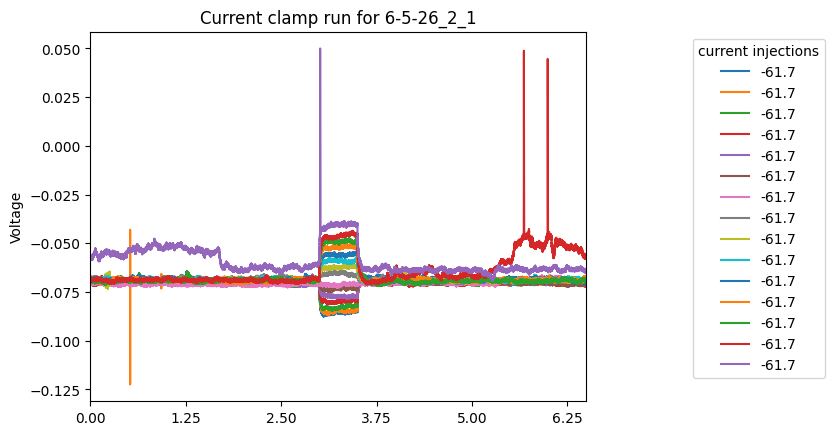

[[-0.07044648 -0.07035281 -0.0702279  ... -0.06922866 -0.06972828
  -0.06982196]
 [-0.06947847 -0.06954092 -0.06972828 ... -0.07057139 -0.07047771
  -0.07025913]
 [-0.07072752 -0.07078997 -0.07075875 ... -0.0709461  -0.07113346
  -0.07116469]
 ...
 [-0.06894762 -0.06919743 -0.06913498 ... -0.0696346  -0.0696346
  -0.06929111]
 [-0.06944724 -0.06994686 -0.06975951 ... -0.05711286 -0.0568006
  -0.05673815]
 [-0.05723777 -0.05726899 -0.05676937 ... -0.06441981 -0.06460717
  -0.0647633 ]]


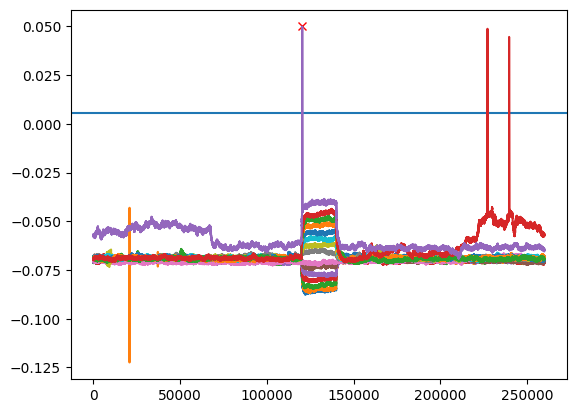

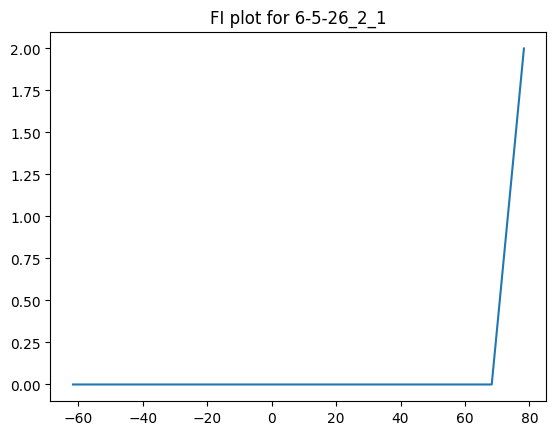

In [142]:
#data.plot_trace(cell_id=)

data.plot_trace(cell_id = data.df.combo.iloc[1], sr=40000, distance = 250, height_factor=5, show_peaks = True)

In [143]:
data.detect_peaks(wind=10500, threshold_sd=100, distance=250, plot_all=False)
data.df.iloc[:2]

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rawData,stimWave,fname,fpath,V_hold_mV,current_injections,corrected_injections,combo,all_freqs,all_peaks
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl,-272.621820,"[-350.0, -339.99999999999994, -329.99999999999...","[-77.37818041685318, -67.37818041685313, -57.3...",6-5-26_1_1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [..."
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl,-18.304873,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.69512663330609, -51.69512663330609, -41.6...",6-5-26_2_1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [..."


In [144]:
data.calculate_ssv_ir(plot=False, ssv_window=7500, baseline_end=35000)

In [398]:
data.df.fname.unique()

array(['1-13-26struct.mat', '1-21-26struct.mat', '1-29-26struct.mat',
       '6-5-26struct.mat', '8-5-26struct.mat', '9-10-26struct.mat',
       '9-14-26struct.mat', '9-7-26struct.mat'], dtype=object)

In [146]:
data.calculate_rheo_ap_metrics(plot=False, use_smoothed=True, wind=350, smooth_window=25, smooth_polyorder=3)
data.df.iloc[:2]

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,ssvs,ssvs_delta,IR_slope,rheo_AP_trace,smoothed_rheo_AP_trace,max_dvdt,min_dvdt,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,"[-0.0771601339960961, -0.08143813414076014, -0...","[-0.00874335795989753, -0.008805810516753831, ...",127.380912,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[-0.08565368172856774, -0.08490425104629096, -...","[-0.01626889106109501, -0.015425781543533593, ...",316.078567,"[-0.048744220626428886, -0.04911893596756736, ...","[-0.048947314206195934, -0.048962793899775724,...",0.004039,-0.001181,3.419482,0.017308,0.030456


In [147]:
data.calculate_ap_decay_tau(plot=False,wind=350,sampling_rate=40000,smooth_window=25,smooth_polyorder=3,tau_bounds=(0.05, 10),seed=1)
data.df.iloc[:2]

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rheo_AP_trace,smoothed_rheo_AP_trace,max_dvdt,min_dvdt,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt,A_fit,tau_fit,C_fit
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[-0.048744220626428886, -0.04911893596756736, ...","[-0.048947314206195934, -0.048962793899775724,...",0.004039,-0.001181,3.419482,0.017308,0.030456,0.112502,1.45031,-0.047343


In [148]:
data.annotate_ap_points(wind=350,smooth_window=25,smooth_polyorder=3,sampling_rate=40000)

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


In [149]:
data.df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt,A_fit,tau_fit,C_fit,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,3.419482,0.017308,0.030456,0.112502,1.450310,-0.047343,9.650,-0.041186,5.15,-0.044006
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,3.587631,0.017611,0.028742,0.116703,1.839174,-0.052523,10.175,-0.044019,4.90,-0.043900
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,4.008606,-0.008990,0.013641,0.114002,1.599403,-0.066371,9.625,-0.058120,5.35,-0.051491
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,5.342577,-0.000751,0.019369,0.107764,2.367330,-0.058545,10.550,-0.044884,5.35,-0.046973
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,3.950241,-0.004485,0.020195,0.106052,2.212695,-0.059329,10.400,-0.047531,5.25,-0.044779


# Example of running class, when the input pickle structure contains multiple animals from the get-go
### this is an alternative to batch loading (currently untested, 9-23-26 BFC)

In [154]:
data = CClamp.load_data_singleFile(r"M:\Ratch\all_concat_asOf9-23-26.pkl")
data.correct_holding_v_and_update_injections()
data.detect_peaks(wind=10500, threshold_sd=100, distance=250, plot_all=False)
data.calculate_ssv_ir(plot=False, ssv_window=7500, baseline_end=35000)
data.calculate_rheo_ap_metrics(plot=False, use_smoothed=True, wind=350, smooth_window=25, smooth_polyorder=3)
data.calculate_ap_decay_tau(plot=False,wind=350,sampling_rate=40000,smooth_window=25,smooth_polyorder=3,tau_bounds=(0.05, 10),seed=1)
data.annotate_ap_points(wind=350,smooth_window=25,smooth_polyorder=3,sampling_rate=40000)

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3395894038.py:237: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  model = linregress(curr_injs, ssvs_corr)


1-13-26_1_1 did not have any detected peaks, skipped and NaN-filled
1-13-26_1_2 did not have any detected peaks, skipped and NaN-filled
1-13-26_1_3 did not have any detected peaks, skipped and NaN-filled
1-13-26_1_4 did not have any detected peaks, skipped and NaN-filled
1-13-26_2_1 did not have any detected peaks, skipped and NaN-filled
1-13-26_2_2 did not have any detected peaks, skipped and NaN-filled
1-13-26_3_1 did not have any detected peaks, skipped and NaN-filled
1-13-26_3_2 did not have any detected peaks, skipped and NaN-filled
1-21-26_1_4 did not have any detected peaks, skipped and NaN-filled
1-21-26_2_1 did not have any detected peaks, skipped and NaN-filled
1-21-26_3_1 did not have any detected peaks, skipped and NaN-filled
1-21-26_4_1 did not have any detected peaks, skipped and NaN-filled
1-21-26_4_6 did not have any detected peaks, skipped and NaN-filled
1-21-26_4_7 did not have any detected peaks, skipped and NaN-filled
1-21-26_4_8 did not have any detected peaks, ski

In [239]:
df = data.df

In [254]:
grouping_info = pd.read_csv(r"M:\Ratch\fluoroLabel_nd_Strain.csv")
grouping_info.iloc[:5]

,unique_cell_id,label,strain,decision
0,1-13-26_1,NON-vTA projecting,SD,include
1,1-13-26_2,NON-vTA projecting,SD,include
2,1-13-26_3,NON-vTA projecting,SD,include
3,1-13-26_4,VTA-projecting,SD,include
4,1-13-26_5,VTA-projecting,SD,include


In [286]:
# load in the grouping info into main df

labels = []
strain = []
decision = []
for i in range(len(df)):
    tmp = grouping_info[grouping_info.unique_cell_id==df.iloc[i].unique_cell_id].reset_index(drop=True)
    if tmp.empty:
        labels.append(np.nan)
        strain.append(np.nan)
        decision.append(np.nan)
    else:
        labels.append(tmp.label.values[0])
        strain.append(tmp.strain.values[0])
        decision.append(tmp.decision.values[0])
df['VTA_label'] = labels
df['strain'] = strain


In [ ]:
# input just the data as standalone column. Date behaves like the animal ID, specifically when nesting cells in GLMMs

dates = []

for i in range(len(df)):
    dates.append(quick_dateGetter(df.iloc[i].unique_cell_id))
df['date'] = dates


In [402]:
#quick function for assigning cell phenotype, phasic vs tonic/transient..
#   our current protocols injkected short (500ms) currents, which makes it hard to differentiate tonic vs transient when considering accomodation matrics
def determine_Phenotype(arr):

    max_AP_count = np.max([len(x) for x in arr])
    if max_AP_count == 0:
        return 'noAP'
    elif max_AP_count == 1:
        return 'phasic'
    elif max_AP_count > 1:
        return 'tonic/transient'

#example usage
arr = df.iloc[58].all_peaks
determine_Phenotype(arr)

'phasic'

In [403]:
# loop and get phenotype info into df
pheno = []
for i in range(len(df)):
    arr = df.iloc[i].all_peaks
    pheno.append(determine_Phenotype(arr))
df['pheno'] = pheno
df.iloc[:2]

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage,unique_cell_id,VTA_label,strain,date,pheno,maximum_frequency
0,1,E,1,8.990942e+07,0.0,15,-2.511577e-10,8.990942e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0
1,1,E,2,1.565842e+08,0.0,25,-3.047405e-10,1.565842e+08,0.0,Garrett,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0


In [404]:
# quick loop to derive maximum firing rate
freqs = []
for i in range(len(df)):
    arr = df.iloc[i].all_peaks
    freqs.append(sum([len(x) for x in arr]))
df['maximum_frequency'] = freqs

In [405]:
dvs = [ 'IR_slope','max_dvdt', 'min_dvdt',
       'dvdt_ratio', 'voltage_at_max_dvdt', 'voltage_at_min_dvdt',
       'tau_fit', 'AHP_time', 'AHP_voltage', 'Threshold_time',
       'Threshold_voltage',  'maximum_frequency']

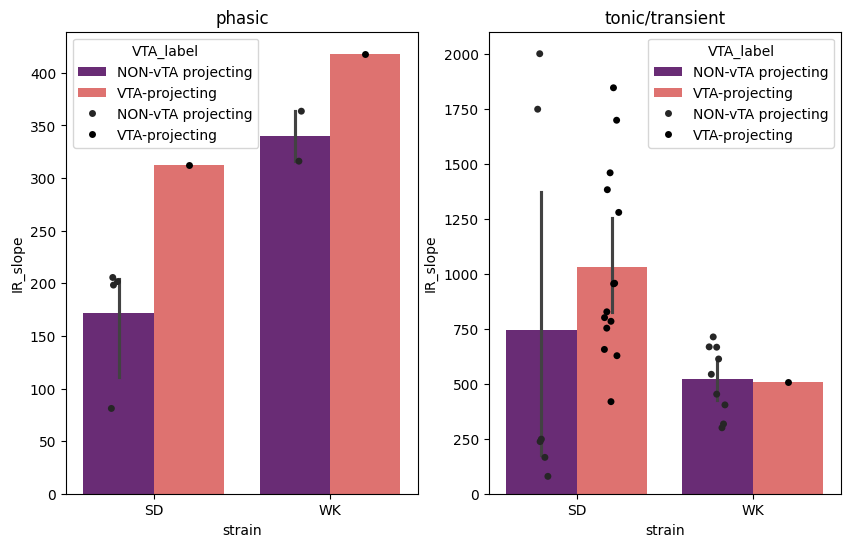

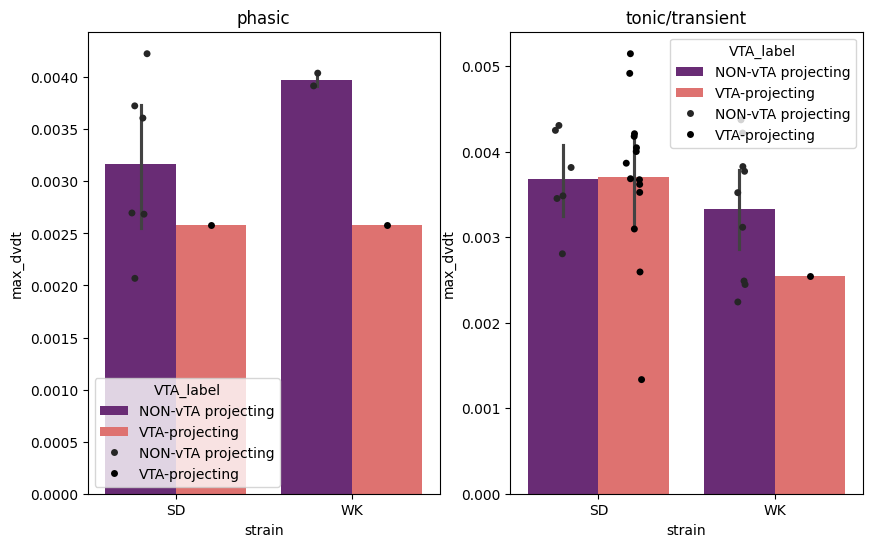

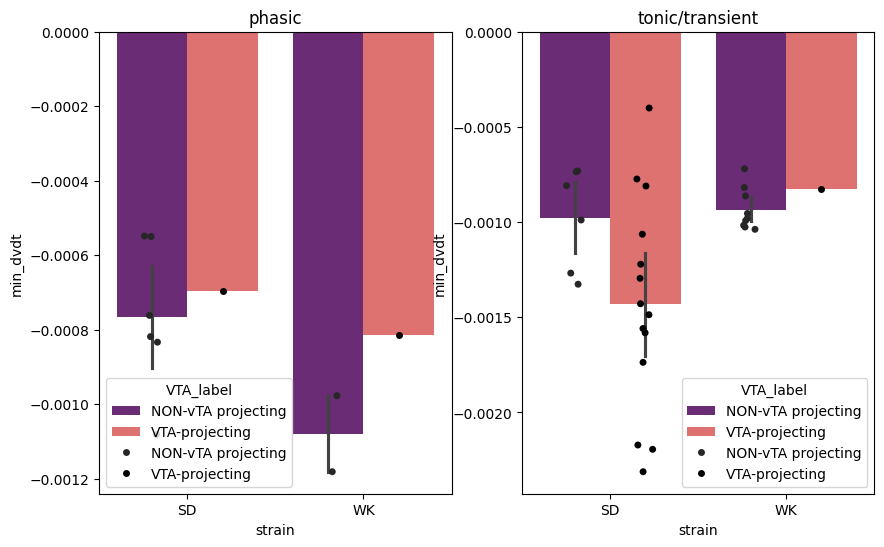

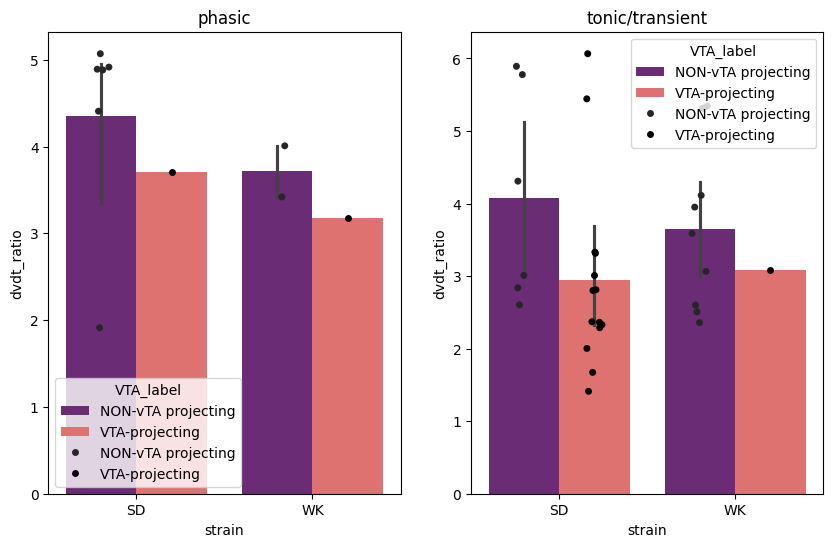

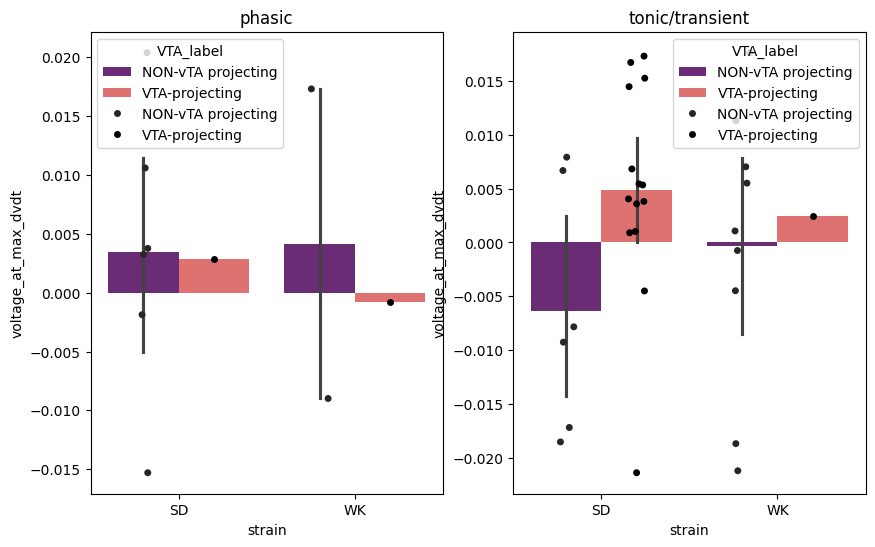

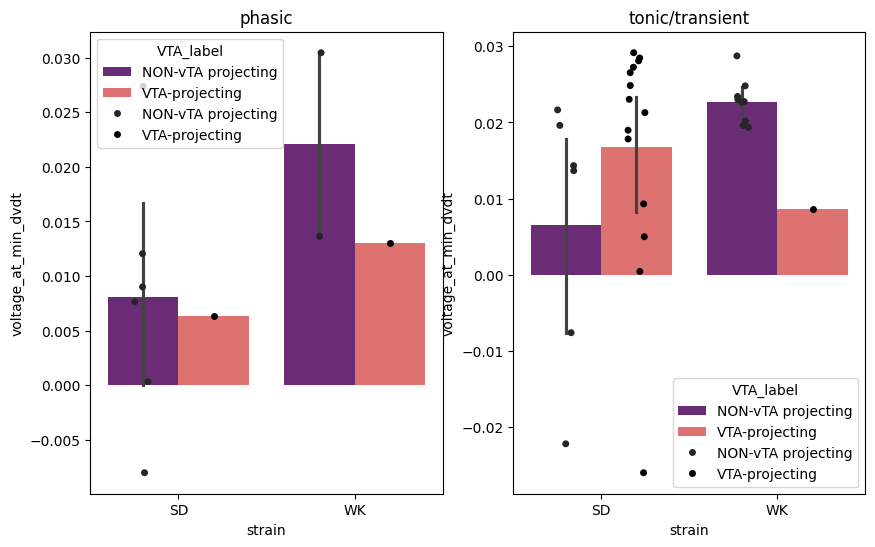

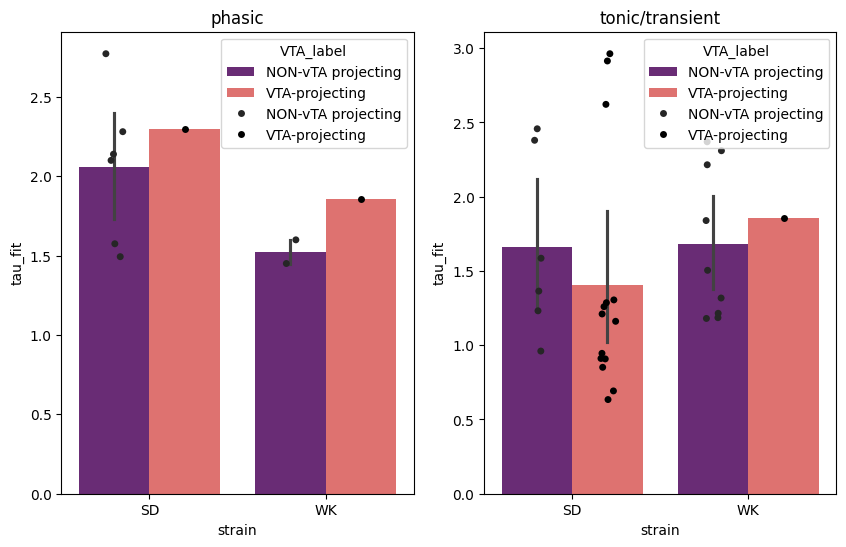

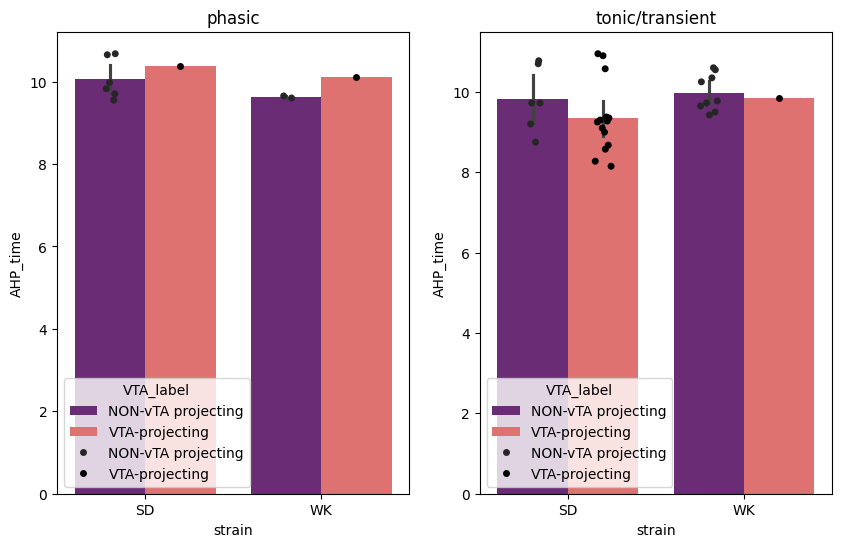

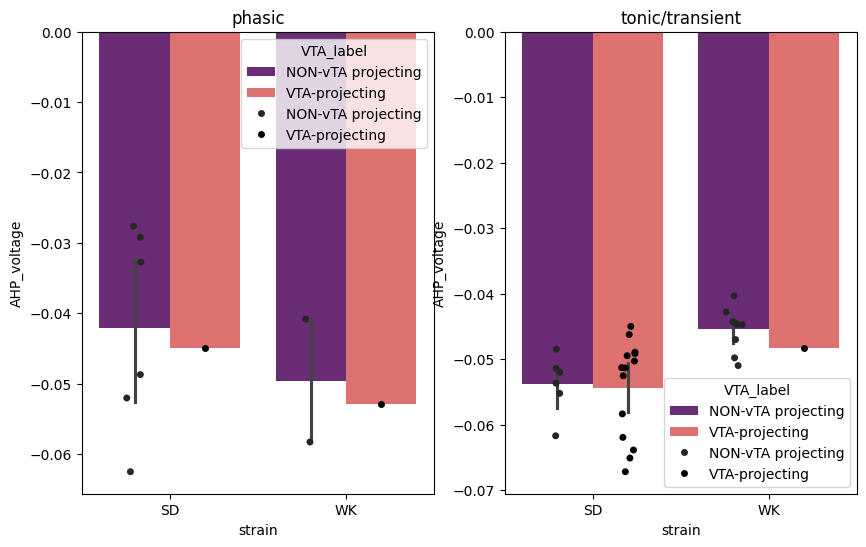

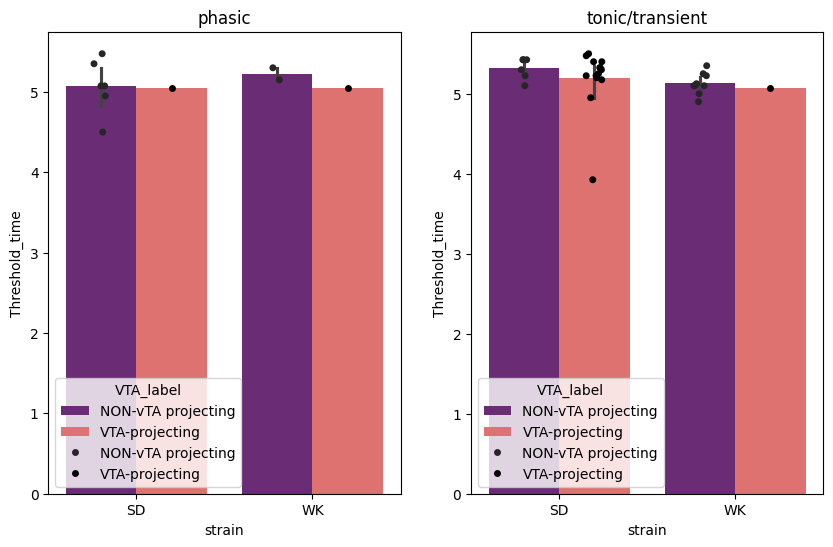

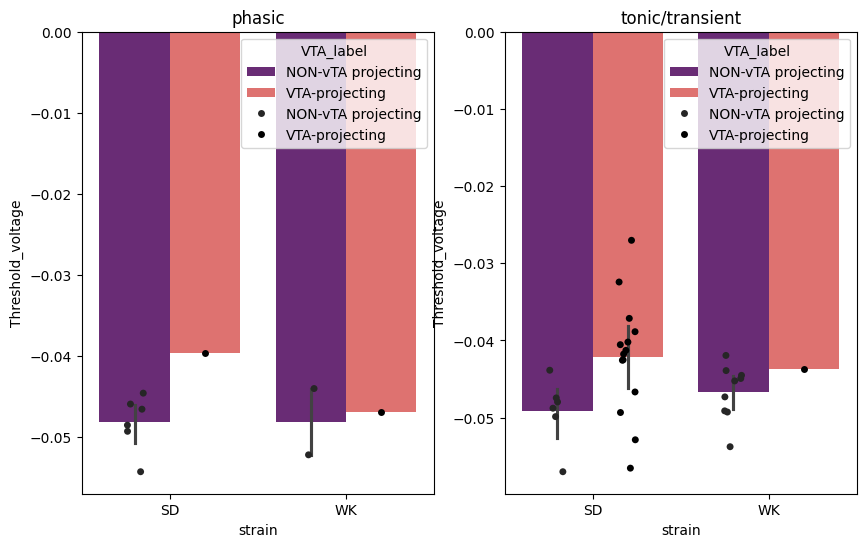

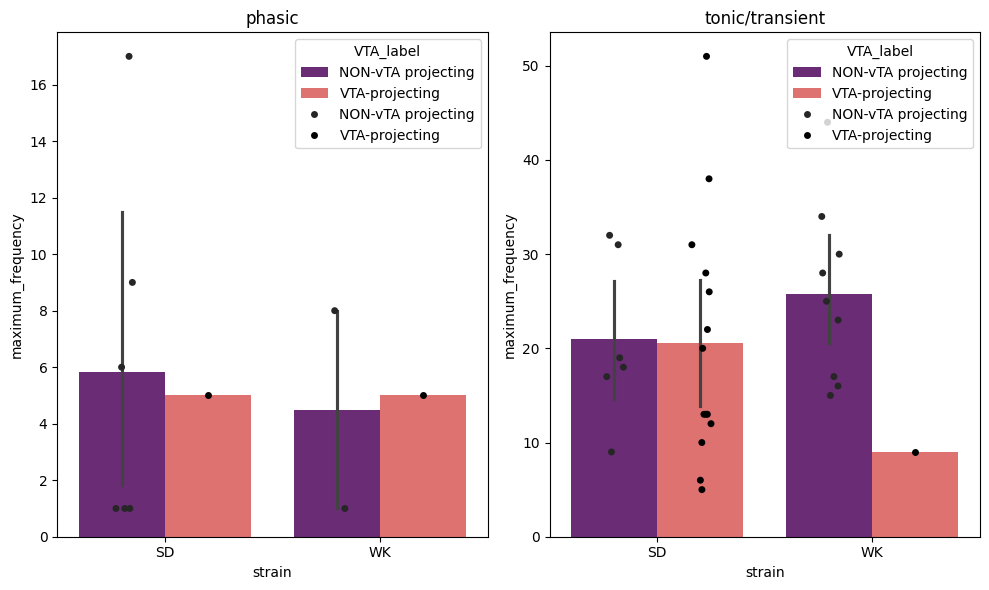

In [406]:
# this is plotting everything, and very likely some cells are represented more than once.. next plot loop takes care of this!
for dv in dvs:
    fig, axs = plt.subplots(1, 2, figsize=(10,6))
    sns.barplot(x='strain', y=dv, hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'], data=df[df.pheno=='phasic'], ax=axs[0], palette='magma')
    sns.barplot(x='strain', y=dv, hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'],data=df[df.pheno=='tonic/transient'], ax=axs[1], palette='magma')
    sns.stripplot(x='strain', y=dv, hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'], data=df[df.pheno=='phasic'], ax=axs[0],dodge=True, palette='dark:k')
    sns.stripplot(x='strain', y=dv, hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'],data=df[df.pheno=='tonic/transient'], ax=axs[1], dodge=True, palette='dark:k')

    axs[0].set_title('phasic')
    axs[1].set_title('tonic/transient')

plt.tight_layout()

In [306]:
df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage,unique_cell_id,VTA_label,strain,date,pheno,maximum_frequency
0,1,E,1,8.990942e+07,0.0,15,-2.511577e-10,8.990942e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0
1,1,E,2,1.565842e+08,0.0,25,-3.047405e-10,1.565842e+08,0.0,Garrett,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0
2,1,E,3,1.902872e+08,0.0,25,-6.236665e-10,1.902872e+08,0.0,Garrett,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0
3,1,E,4,1.761104e+08,0.0,25,-6.718291e-10,1.761104e+08,0.0,Garrett,...,NaN,NaN,NaN,NaN,1-13-26_1,NON-vTA projecting,SD,1-13-26,noAP,0
4,2,E,1,1.985791e+08,0.0,25,-8.051047e-10,1.985791e+08,0.0,Garrett,...,NaN,NaN,NaN,NaN,1-13-26_2,NON-vTA projecting,SD,1-13-26,noAP,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,4,E,1,1.360347e+07,0.0,15,-1.381383e-11,1.360347e+07,0.0,Rudi,...,10.575,-0.049463,5.200,-0.052865,9-7-26_4,VTA-projecting,SD,9-7-26,tonic/transient,12
81,4,E,3,1.194809e+07,0.0,25,-1.245103e-11,1.194809e+07,0.0,Garrett,...,10.900,-0.051276,5.225,-0.049331,9-7-26_4,VTA-projecting,SD,9-7-26,tonic/transient,26
82,5,E,1,3.400268e+07,0.0,25,-3.707124e-10,3.400268e+07,0.0,Garrett,...,9.700,-0.027621,5.075,-0.044574,9-7-26_5,NON-vTA projecting,SD,9-7-26,tonic/transient,9
83,5,E,3,9.032956e+07,0.0,25,-3.279081e-10,9.032956e+07,0.0,Garrett,...,9.975,-0.029202,5.075,-0.045919,9-7-26_5,NON-vTA projecting,SD,9-7-26,tonic/transient,6


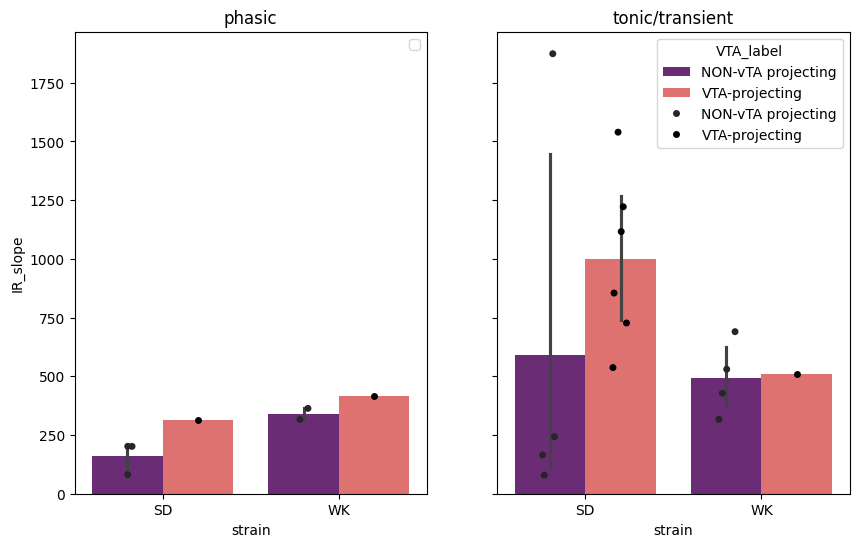

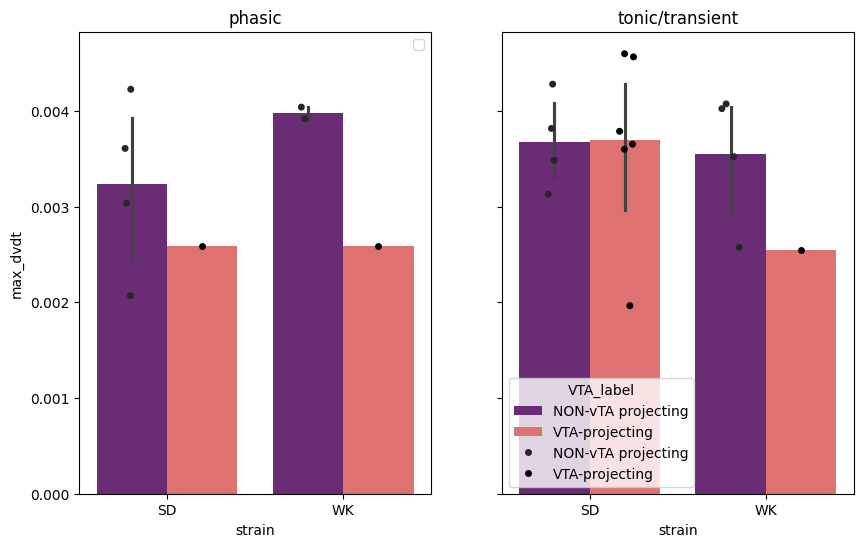

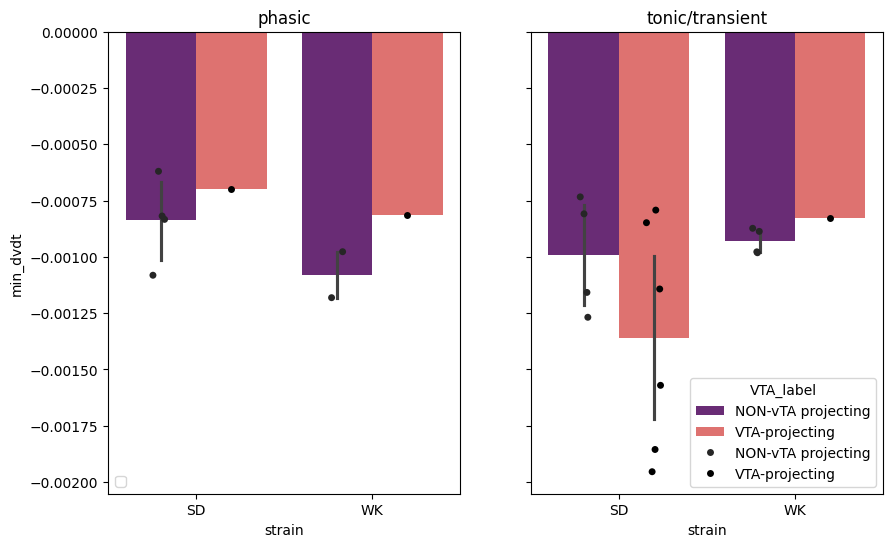

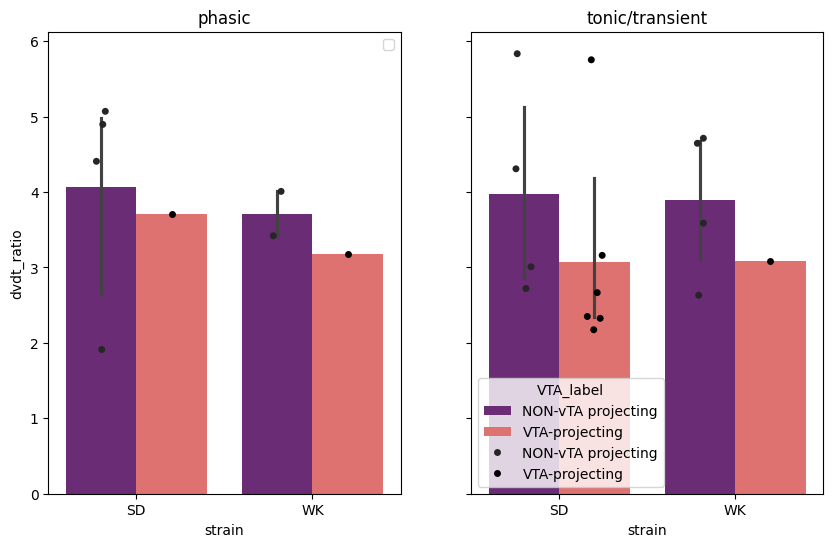

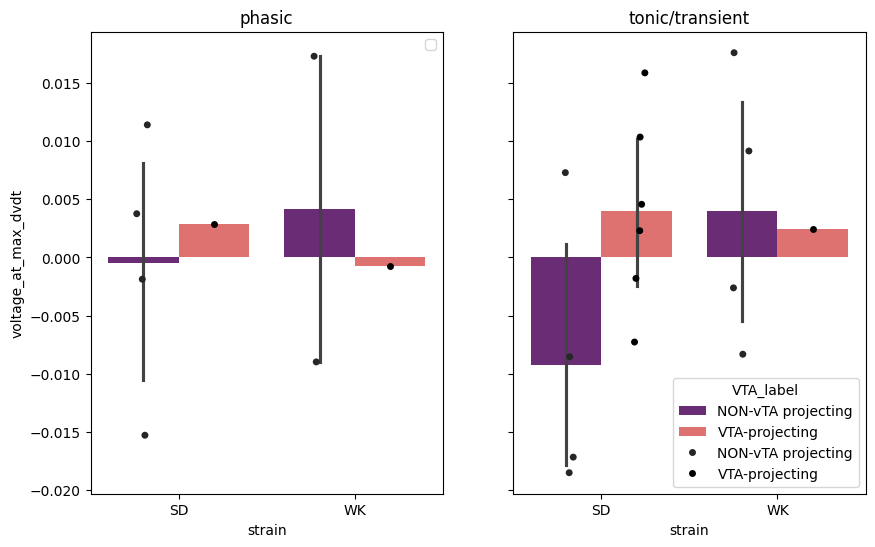

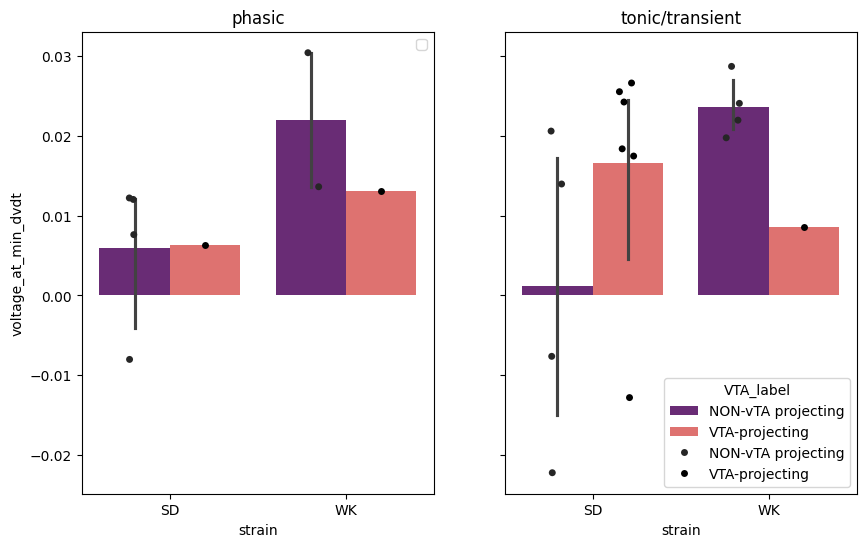

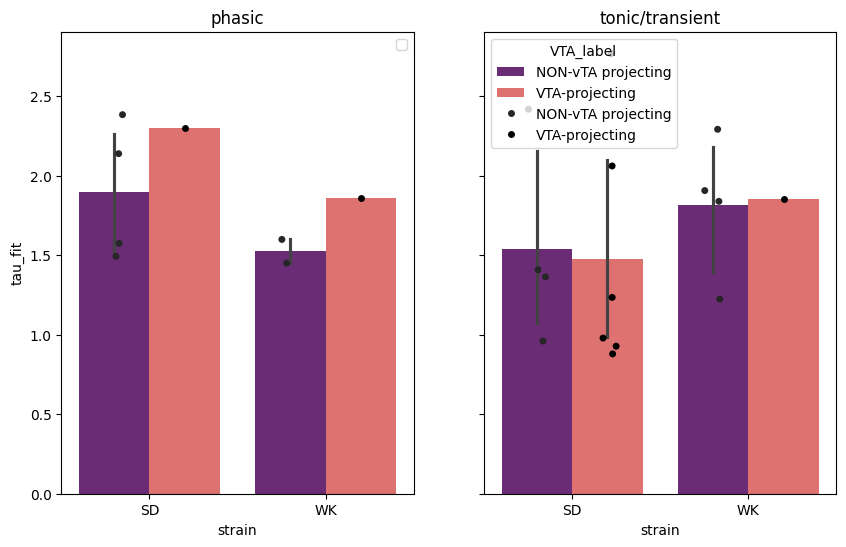

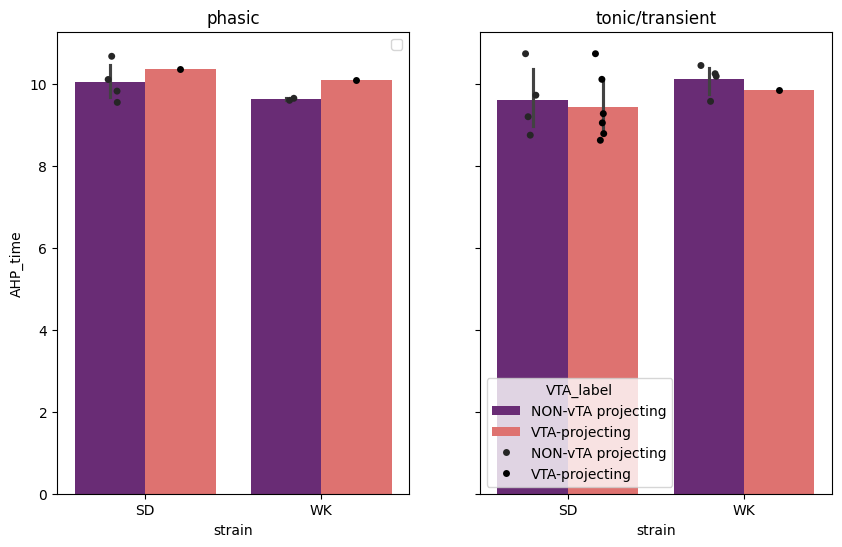

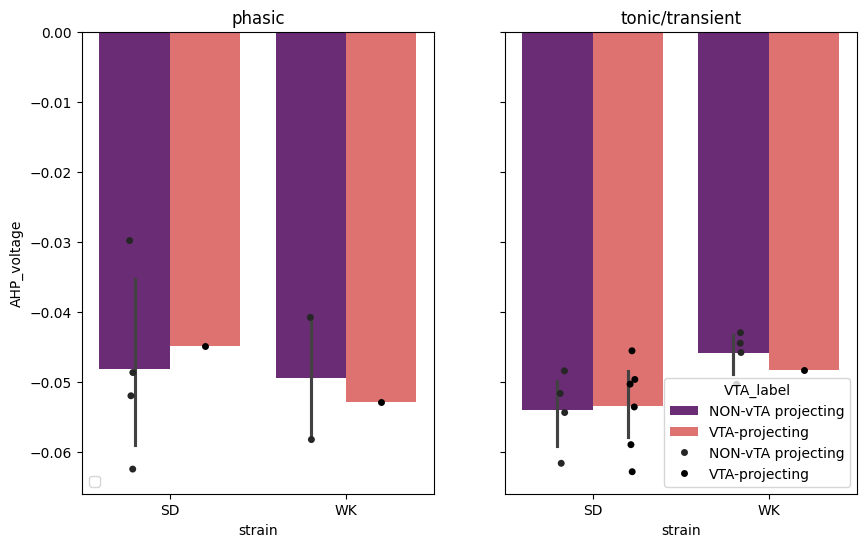

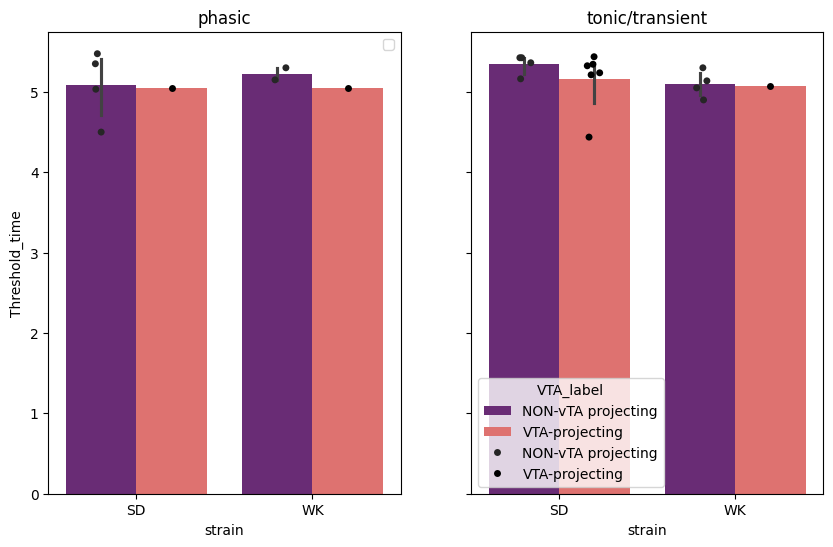

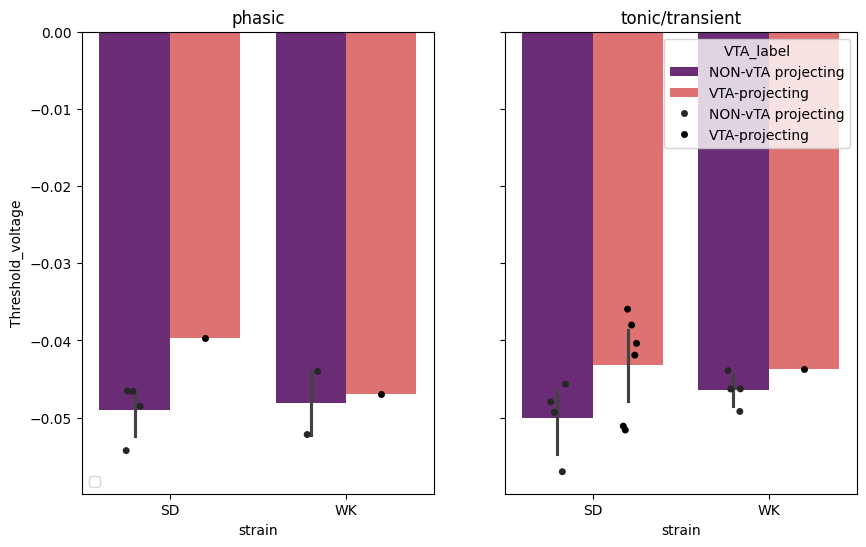

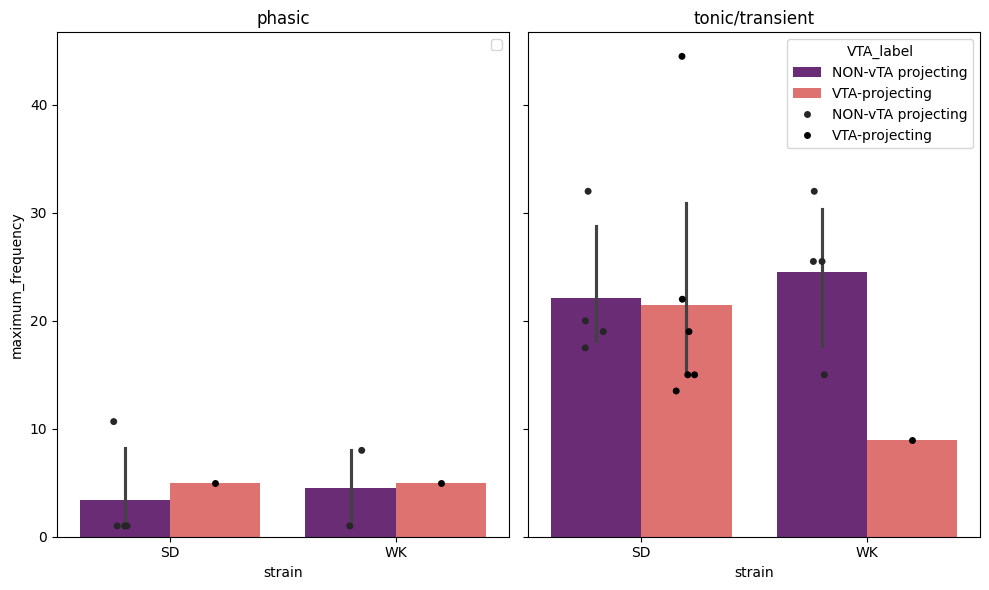

In [410]:
# this plots DOWN_SAMPLED data, meaning if a cell is represented by 2 values, they are averaged. those averages are what is plotted (avoids pseudoreplication)

import statsmodels.formula.api as smf


for dv in dvs:
    plot_df = df[df.VTA_label.isin(['NON-vTA projecting', 'VTA-projecting'])].groupby(['strain', 'VTA_label', 'pheno', 'unique_cell_id', 'date'])[dv].describe().reset_index()   
    fig, axs = plt.subplots(1, 2, figsize=(10,6), sharey=True)
    sns.barplot(x='strain', y='mean', hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'], data=plot_df[plot_df.pheno=='phasic'], ax=axs[0], palette='magma')
    sns.barplot(x='strain', y='mean', hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'],data=plot_df[plot_df.pheno=='tonic/transient'], ax=axs[1], palette='magma')
    sns.stripplot(x='strain', y='mean', hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'], data=plot_df[plot_df.pheno=='phasic'], ax=axs[0],dodge=True, palette='dark:k')
    sns.stripplot(x='strain', y='mean', hue='VTA_label', order=['SD', 'WK'], hue_order=['NON-vTA projecting', 'VTA-projecting'],data=plot_df[plot_df.pheno=='tonic/transient'], ax=axs[1], dodge=True, palette='dark:k')
    axs[0].legend([])
    axs[0].set_ylabel(dv)
    axs[0].set_title('phasic')
    axs[1].set_title('tonic/transient')

    #plot_df = plot_df.dropna(subset=['mean']).reset_index(drop=True)  #clean up any NaN values that will throw off the GLMM
    #formula = 'mean~ strain*VTA_label'
    #model = smf.mixedlm(formula, data=plot_df, groups=plot_df["date"])

    #result = model.fit(reml=False,method="lbfgs")

plt.tight_layout()

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\1261843485.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VTA_label', y='mean', order=['NON-vTA projecting', 'VTA-projecting'], data=plot_df[plot_df.pheno=='phasic'], ax=axs[0], palette='magma')
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\1261843485.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VTA_label', y='mean', order=['NON-vTA projecting', 'VTA-projecting'],data=plot_df[plot_df.pheno=='tonic/transient'], ax=axs[1], palette='magma')
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\1261843485.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the

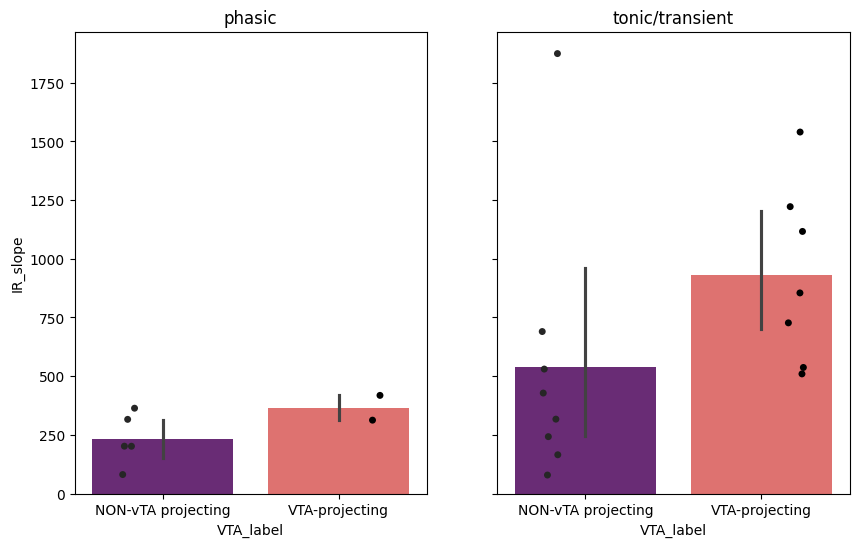

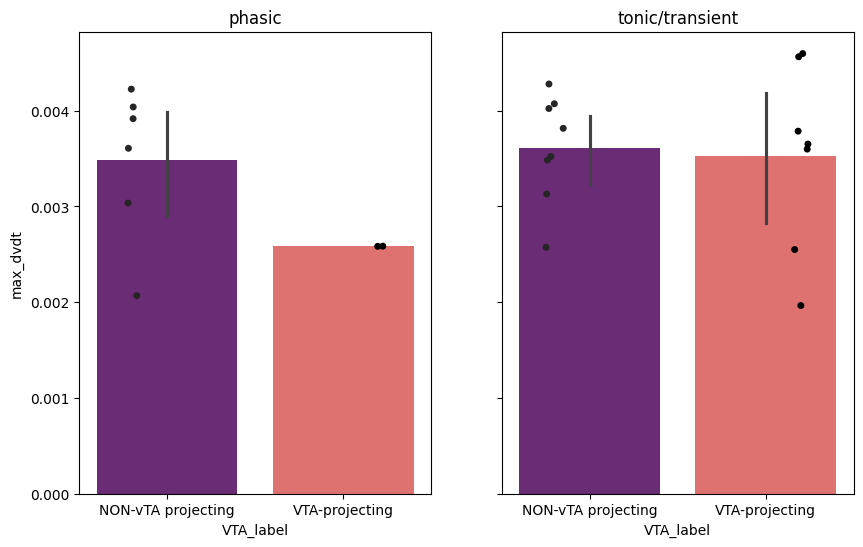

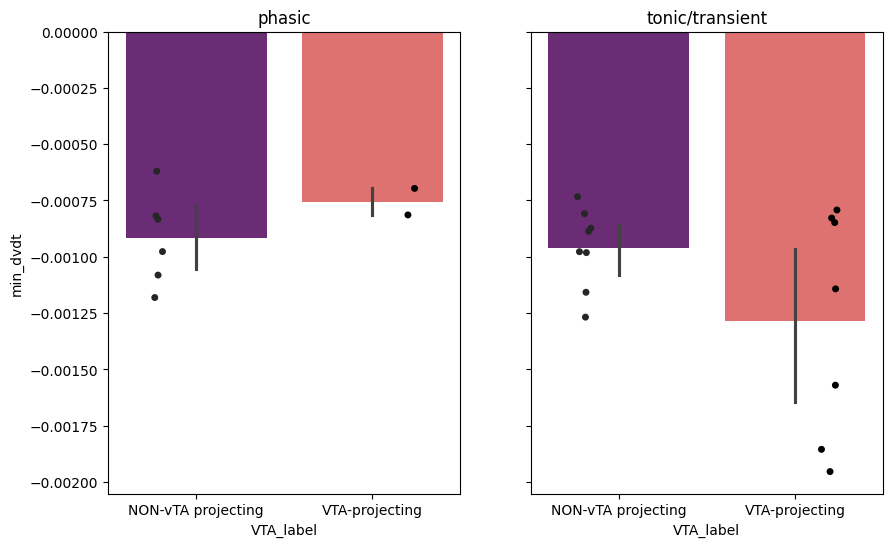

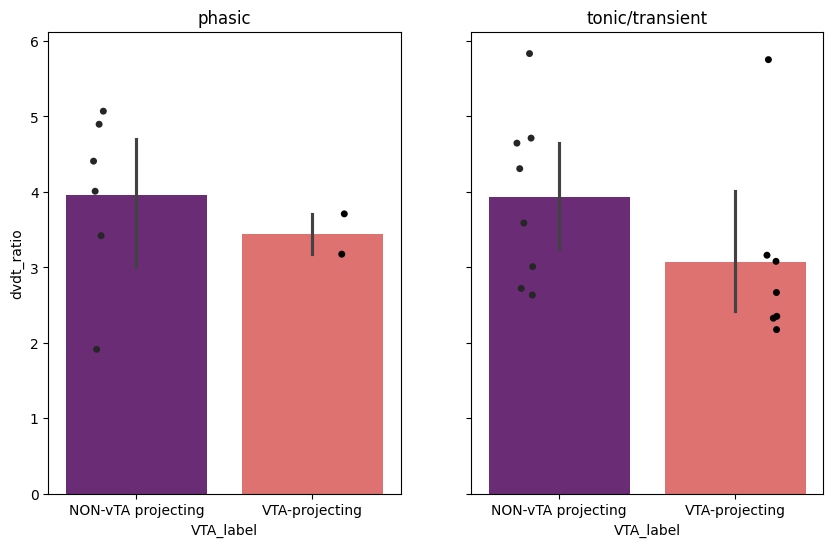

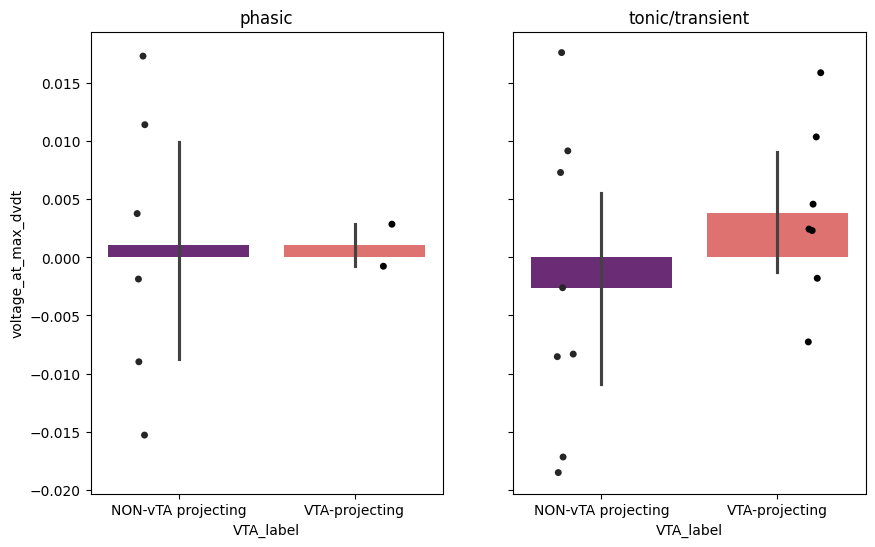

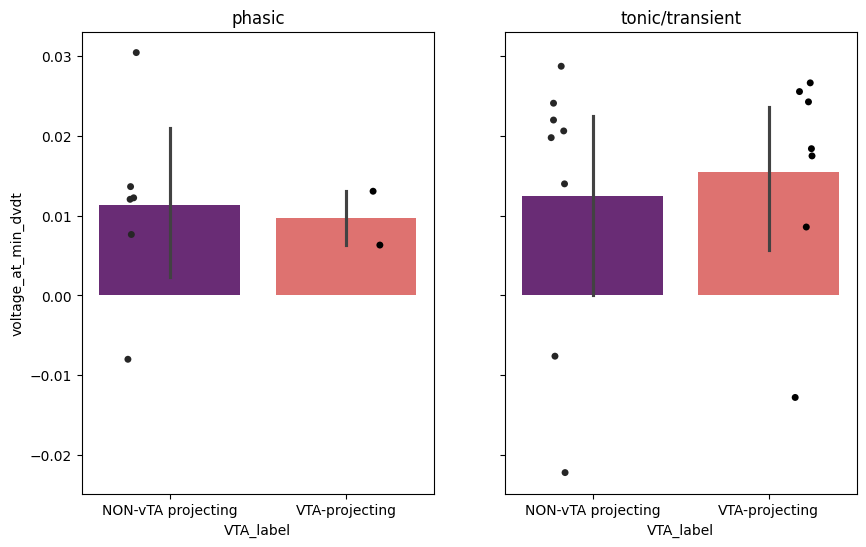

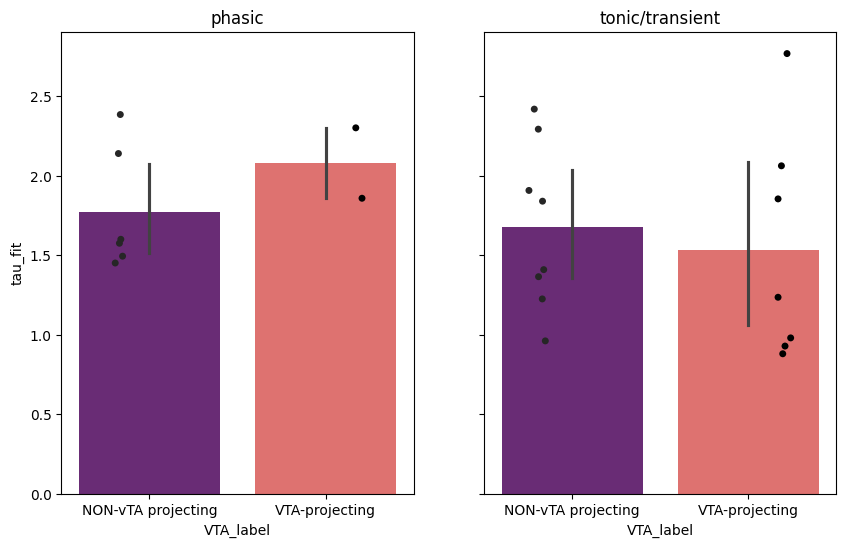

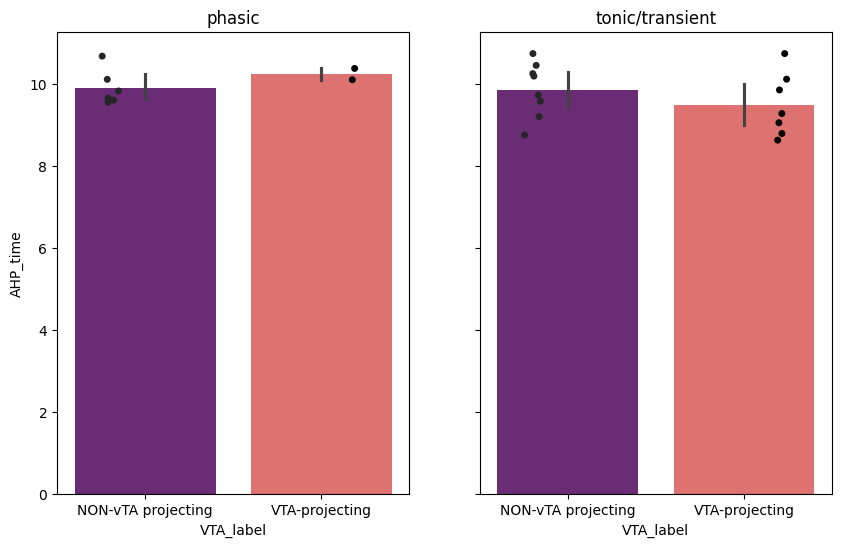

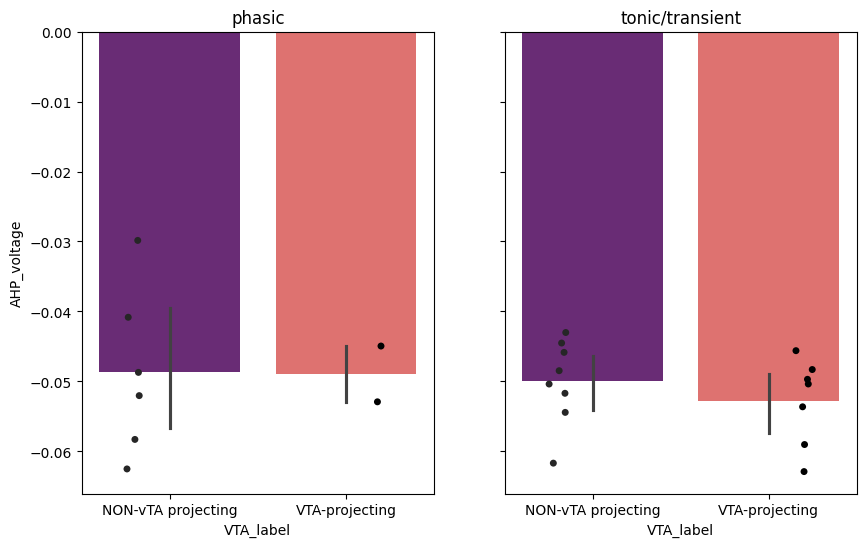

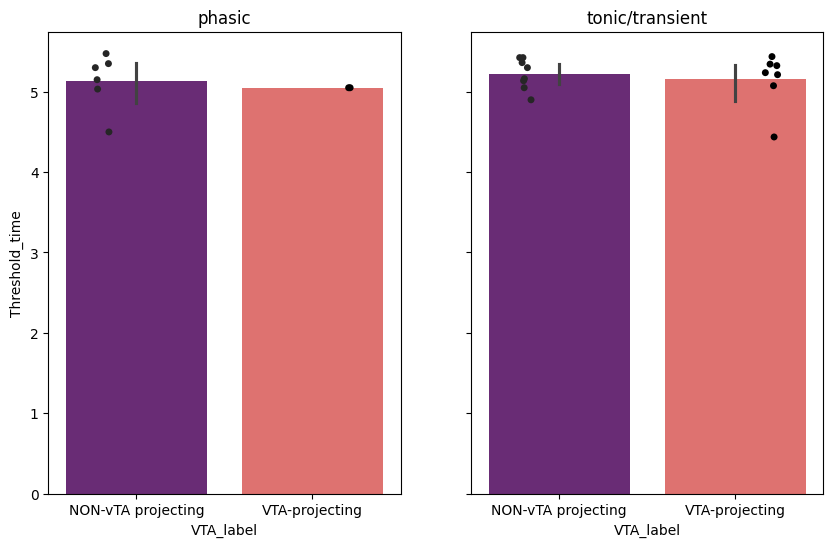

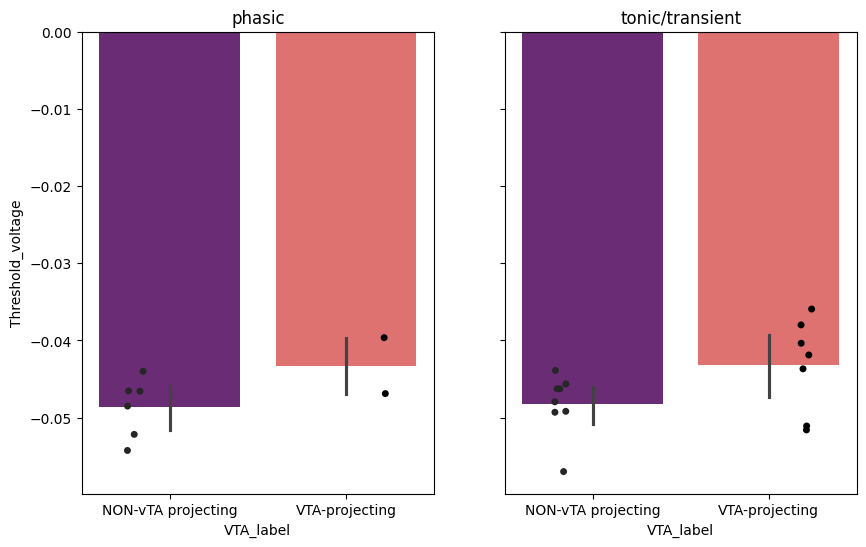

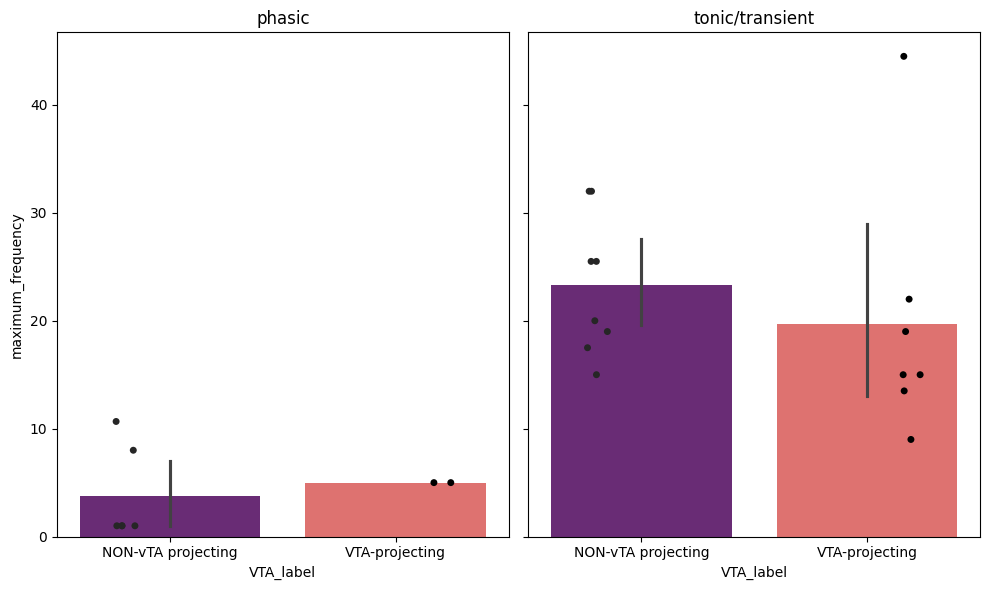

In [409]:
# this plots DOWN_SAMPLED data, meaning if a cell is represented by 2 values, they are averaged. those averages are what is plotted (avoids pseudoreplication)

import statsmodels.formula.api as smf


for dv in dvs:
    plot_df = df[df.VTA_label.isin(['NON-vTA projecting', 'VTA-projecting'])].groupby(['strain', 'VTA_label', 'pheno', 'unique_cell_id', 'date'])[dv].describe().reset_index()   
    fig, axs = plt.subplots(1, 2, figsize=(10,6), sharey=True)
    sns.barplot(x='VTA_label', y='mean', order=['NON-vTA projecting', 'VTA-projecting'], data=plot_df[plot_df.pheno=='phasic'], ax=axs[0], palette='magma')
    sns.barplot(x='VTA_label', y='mean', order=['NON-vTA projecting', 'VTA-projecting'],data=plot_df[plot_df.pheno=='tonic/transient'], ax=axs[1], palette='magma')
    sns.stripplot(x='VTA_label', y='mean',  order=['NON-vTA projecting', 'VTA-projecting'], data=plot_df[plot_df.pheno=='phasic'], ax=axs[0],dodge=.2, palette='dark:k')
    sns.stripplot(x='VTA_label', y='mean',  order=['NON-vTA projecting', 'VTA-projecting'],data=plot_df[plot_df.pheno=='tonic/transient'], ax=axs[1], dodge=.2, palette='dark:k')
    axs[0].set_ylabel(dv)
    axs[0].set_title('phasic')
    axs[1].set_title('tonic/transient')

    #plot_df = plot_df.dropna(subset=['mean']).reset_index(drop=True)  #clean up any NaN values that will throw off the GLMM
    #formula = 'mean~ strain*VTA_label'
    #model = smf.mixedlm(formula, data=plot_df, groups=plot_df["date"])

    #result = model.fit(reml=False,method="lbfgs")

plt.tight_layout()

In [387]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import sem, t


def generate_phasePlots(df, strain=None, pheno=None, VTA_label=None):
        # options for VTA_label: ['NON-vTA projecting', 'VTA-projecting'] 
        # options for pheno: ['phasic', 'tonic/transient'] 
        # options for strain: ['SD', 'WK']
    # ---------------------------------------------------------
    # Select data
    # ---------------------------------------------------------
    if strain is None:
        subset = df[
            (df.pheno == pheno) &
            (df.VTA_label == VTA_label)
        ]
        label = pheno + '_' +VTA_label
    elif pheno is None:
        subset = df[
            (df.strain == strain) &
            (df.VTA_label == VTA_label)
        ]
        label = strain + '_' +VTA_label

    elif VTA_label is None:
        subset = df[
            (df.strain == strain) &
            (df.pheno == pheno)
        ]
        label = strain +'_'+pheno

    else:
        raise ValueError("One of strain, pheno, or VTA_label must be None.")

    # ---------------------------------------------------------
    # Stack traces
    # ---------------------------------------------------------
    try:
        arr = np.stack(subset.smoothed_rheo_AP_trace.dropna().to_numpy())
    except:
        print('Either input-name was wrong, or there may be no data to stack. Check you dataframe')
        return

    # ---------------------------------------------------------
    # Calculate phase trajectory for EACH trace
    # ---------------------------------------------------------
    phase_arr = np.gradient(arr, axis=1)

    # ---------------------------------------------------------
    # Mean phase trajectory
    # ---------------------------------------------------------
    mean_voltage = np.nanmean(arr, axis=0)
    mean_phase = np.nanmean(phase_arr, axis=0)

    # ---------------------------------------------------------
    # 95% CI of the mean phase trajectory
    # ---------------------------------------------------------
    n = np.sum(~np.isnan(phase_arr), axis=0)

    se = np.nanstd(phase_arr, axis=0, ddof=1) / np.sqrt(n)

    tcrit = t.ppf(0.975, n - 1)

    lower = mean_phase - tcrit * se
    upper = mean_phase + tcrit * se

    # ---------------------------------------------------------
    # Plot
    # ---------------------------------------------------------
    plt.plot(mean_voltage, mean_phase)

    plt.fill_between(
        mean_voltage,
        lower,
        upper,
        alpha=0.2, label=label
    )
    plt.legend()
    plt.ylabel('dV/dt', fontsize=20)
    plt.xlabel('Voltage (V)', fontsize=20)
    return 

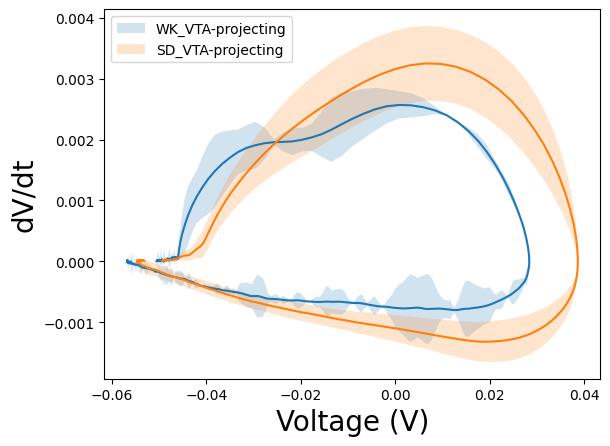

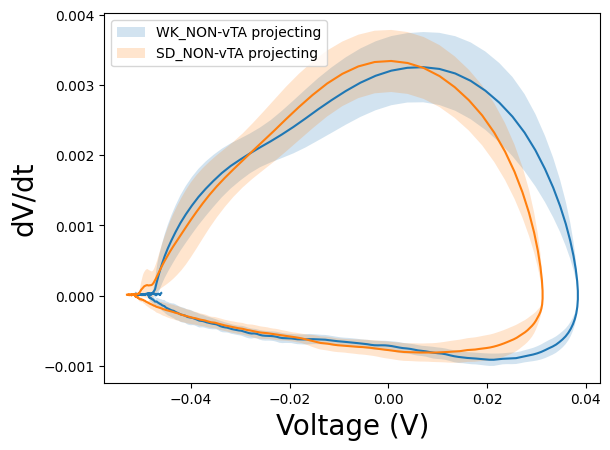

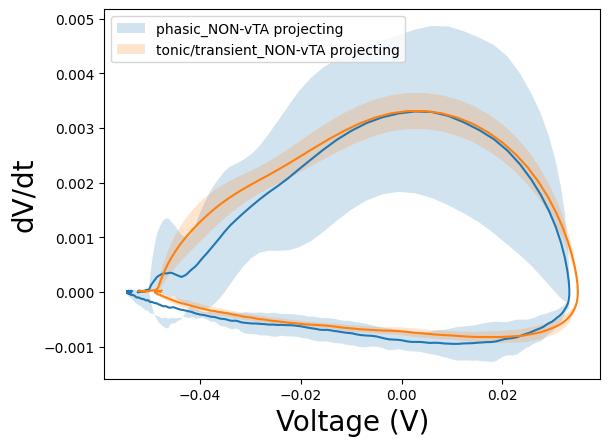

Either input-name was wrong, or there may be no data to stack. Check you dataframe


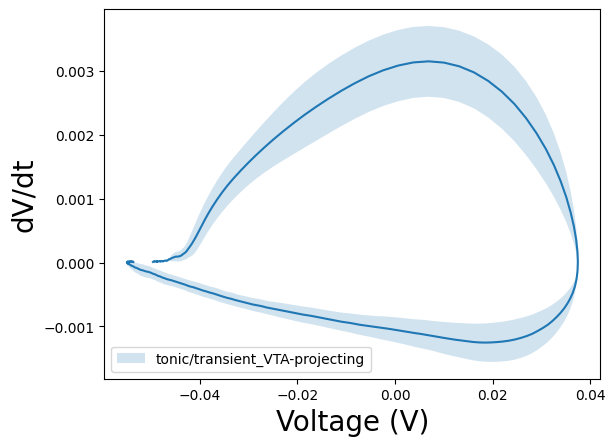

In [388]:
generate_phasePlots(df, strain='WK', pheno=None, VTA_label='VTA-projecting')
generate_phasePlots(df, strain='SD', pheno=None, VTA_label='VTA-projecting')

plt.show()

generate_phasePlots(df, strain='WK', pheno=None, VTA_label='NON-vTA projecting')
generate_phasePlots(df, strain='SD', pheno=None, VTA_label='NON-vTA projecting')

plt.show()

generate_phasePlots(df, strain=None, pheno='phasic', VTA_label='NON-vTA projecting')
generate_phasePlots(df, strain=None, pheno='tonic/transient', VTA_label='NON-vTA projecting')

plt.show()

generate_phasePlots(df, strain=None, pheno='phasic', VTA_label='VTA-projecting')
generate_phasePlots(df, strain=None, pheno='tonic/transient', VTA_label='VTA-projecting')



In [394]:


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation


def animate_phase_trajectory(ap, sampling_rate=40000, interval=10):
    """
    Animate an action potential and its phase trajectory.

    Parameters
    ----------
    ap : array-like
        1D action potential voltage trace.
    sampling_rate : float
        Sampling rate in Hz.
    interval : float
        Animation interval in milliseconds.
    """

    ap = np.asarray(ap)

    # Time in ms
    t = np.arange(len(ap)) / sampling_rate * 1000

    # dV/dt in V/s if voltage is in V
    dvdt = np.gradient(ap, 1 / sampling_rate)

    # If AP is in mV, this gives mV/s instead.
    # Convert to mV/ms if desired:
    dvdt = np.gradient(ap, 1 / sampling_rate) / 1000

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(12, 5)
    )

    # ---------------------------------------------------------
    # Left: AP
    # ---------------------------------------------------------

    ax1.plot(t, ap)

    ap_dot, = ax1.plot(
        [t[0]],
        [ap[0]],
        'o',
        markersize=8
    )

    ax1.set_xlabel("Time (ms)")
    ax1.set_ylabel("Voltage (mV)")
    ax1.set_title("Action potential")

    ax1.set_xlim(t.min(), t.max())

    # Give a little padding to y limits
    yrange = ap.max() - ap.min()
    ax1.set_ylim(
        ap.min() - 0.1 * yrange,
        ap.max() + 0.1 * yrange
    )

    # ---------------------------------------------------------
    # Right: Phase trajectory
    # ---------------------------------------------------------

    ax2.plot(
        ap,
        dvdt
    )

    phase_dot, = ax2.plot(
        [ap[0]],
        [dvdt[0]],
        'o',
        markersize=8
    )

    ax2.set_xlabel("Voltage (mV)")
    ax2.set_ylabel("dV/dt (mV/ms)")
    ax2.set_title("Phase trajectory")

    xrange = ap.max() - ap.min()
    yrange = dvdt.max() - dvdt.min()

    ax2.set_xlim(
        ap.min() - 0.1 * xrange,
        ap.max() + 0.1 * xrange
    )

    ax2.set_ylim(
        dvdt.min() - 0.1 * yrange,
        dvdt.max() + 0.1 * yrange
    )

    # ---------------------------------------------------------
    # Animation
    # ---------------------------------------------------------

    def update(i):

        # AP dot
        ap_dot.set_data(
            [t[i]],
            [ap[i]]
        )

        # Phase-space dot
        phase_dot.set_data(
            [ap[i]],
            [dvdt[i]]
        )

        return ap_dot, phase_dot

    anim = FuncAnimation(
        fig,
        update,
        frames=len(ap),
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.tight_layout()

    return anim

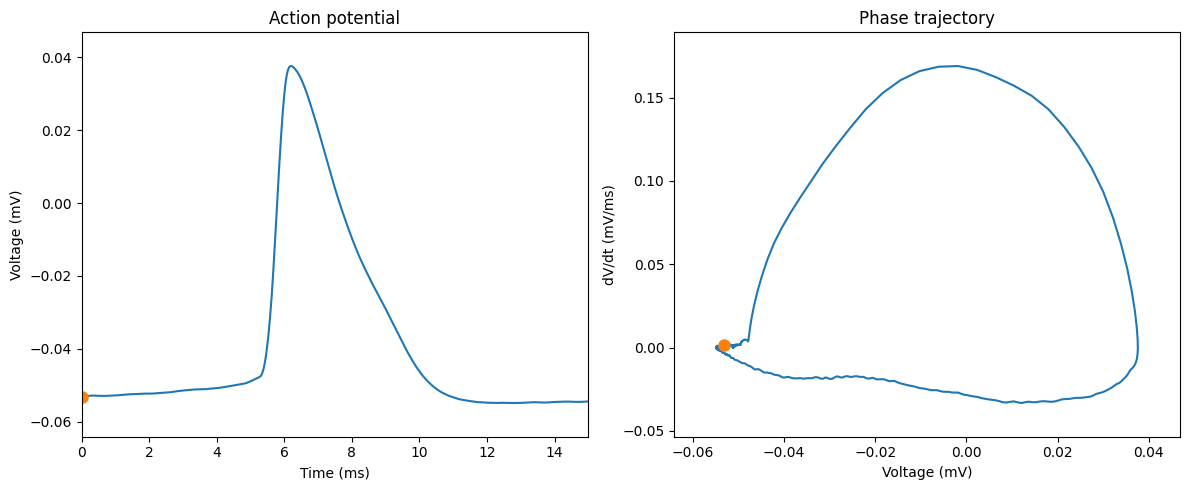

In [395]:
ap = df.iloc[58].smoothed_rheo_AP_trace

anim = animate_phase_trajectory(
    ap,
    sampling_rate=40000,
    interval=2
)

plt.show()

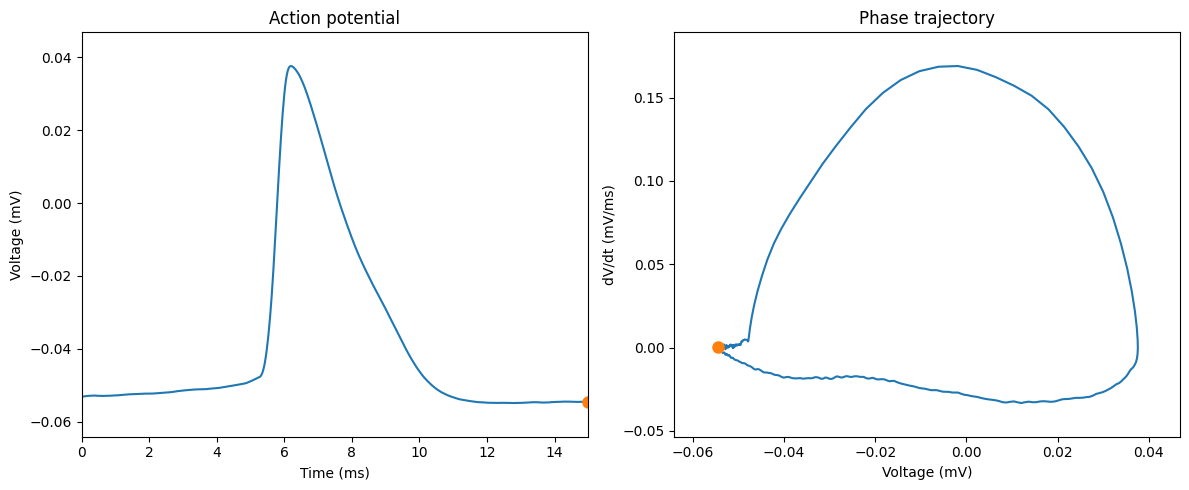

In [397]:
anim = animate_phase_trajectory(
    ap,
    sampling_rate=40000,
    interval=2
)

anim.save(
    r"Z:\AP_phase_trajectory.mp4",
    writer="ffmpeg",
    fps=30,
    dpi=200
)

In [401]:
df.all_peaks

0     [[], [], [], [], [], [], [], [], [], [], [], [...
1     [[], [], [], [], [], [], [], [], [], [], [], [...
2     [[], [], [], [], [], [], [], [], [], [], [], [...
3     [[], [], [], [], [], [], [], [], [], [], [], [...
4     [[], [], [], [], [], [], [], [], [], [], [], [...
                            ...                        
80    [[], [], [], [], [], [], [], [122662], [121106...
81    [[], [], [], [], [], [], [], [], [], [], [], [...
82    [[], [], [], [], [], [], [], [], [], [], [], [...
83    [[], [], [], [], [], [], [], [], [], [], [], [...
84    [[60356], [60357], [60425], [60421], [60474], ...
Name: all_peaks, Length: 85, dtype: object

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

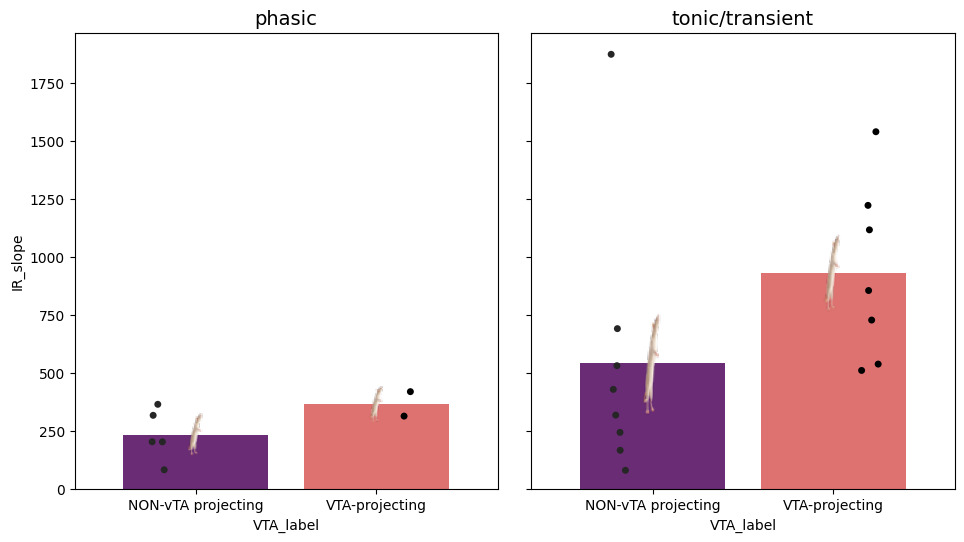

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

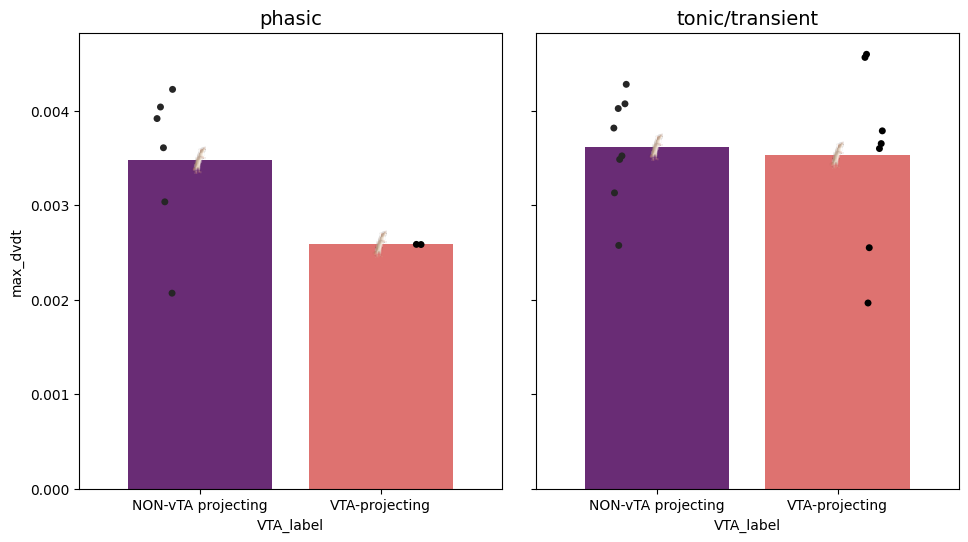

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

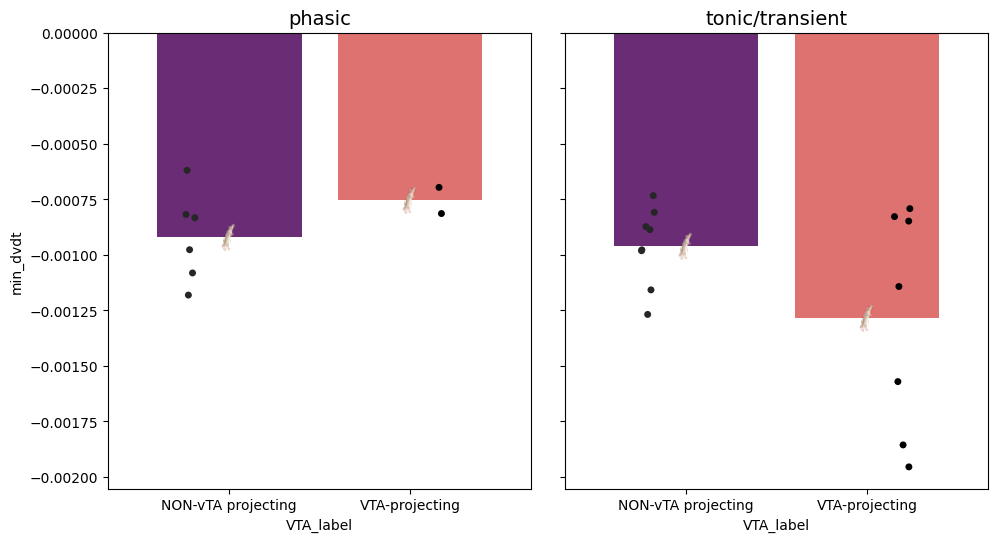

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

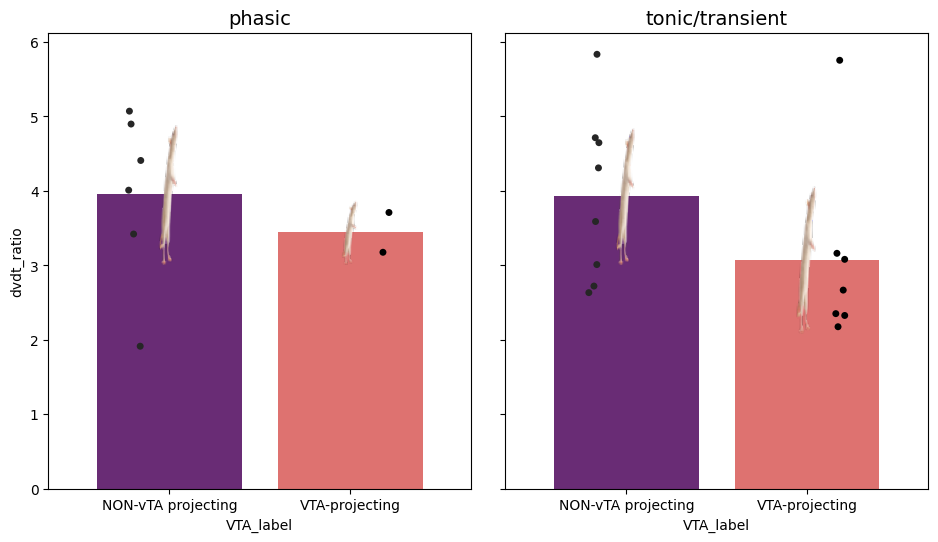

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

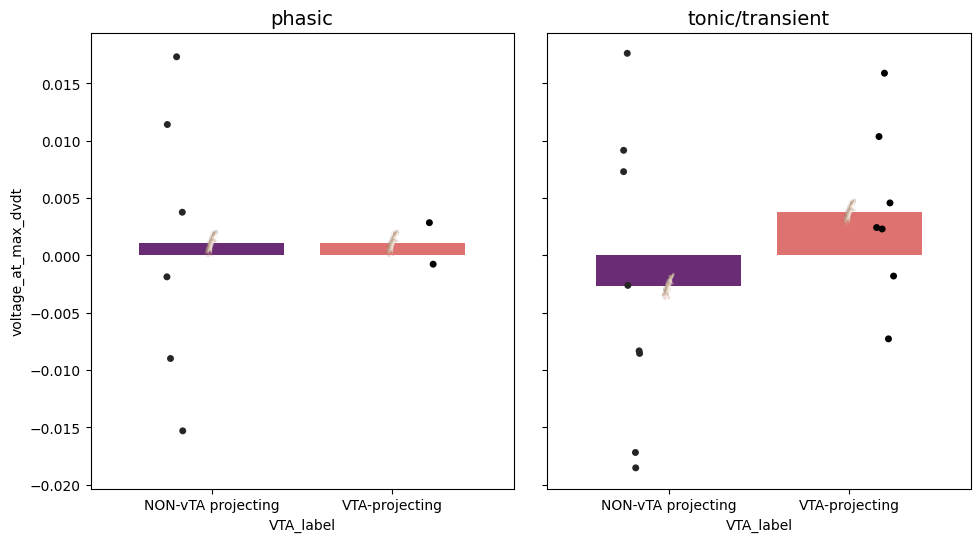

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

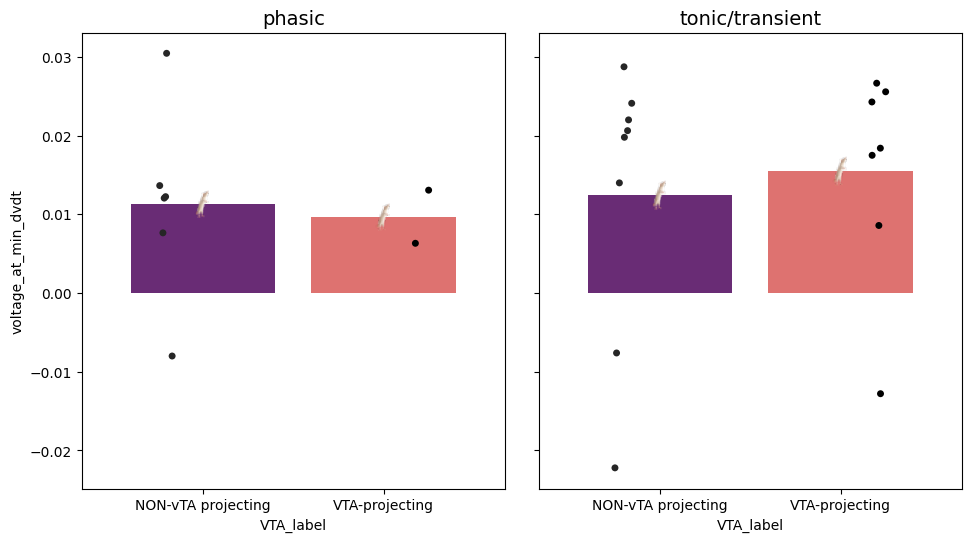

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

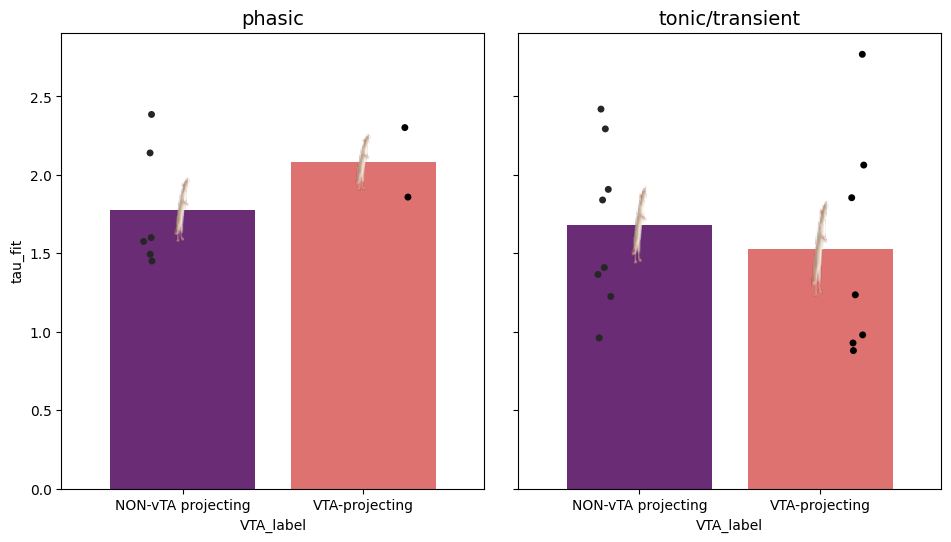

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

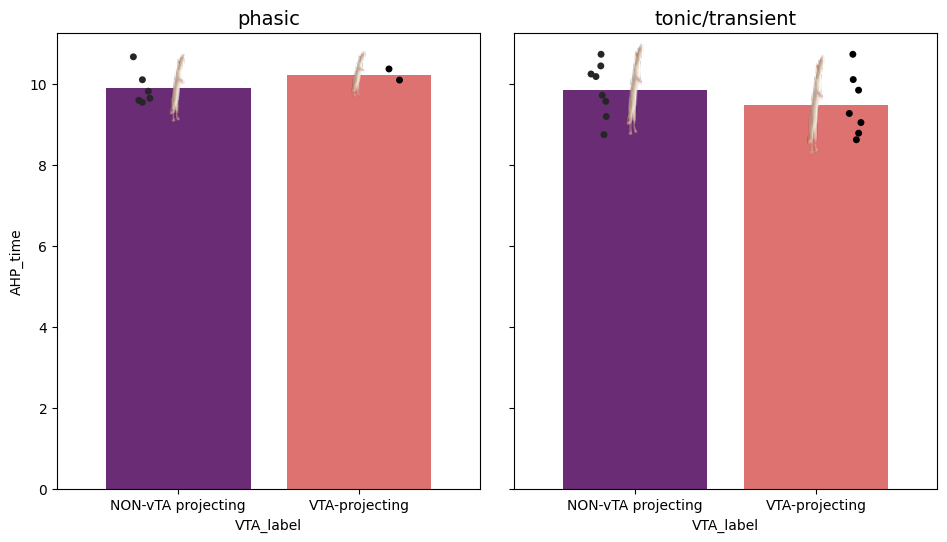

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

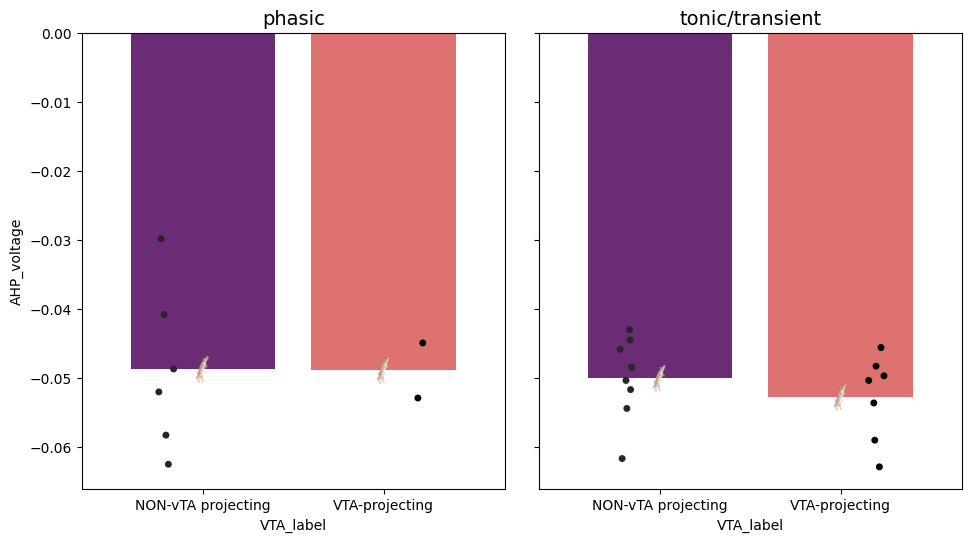

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

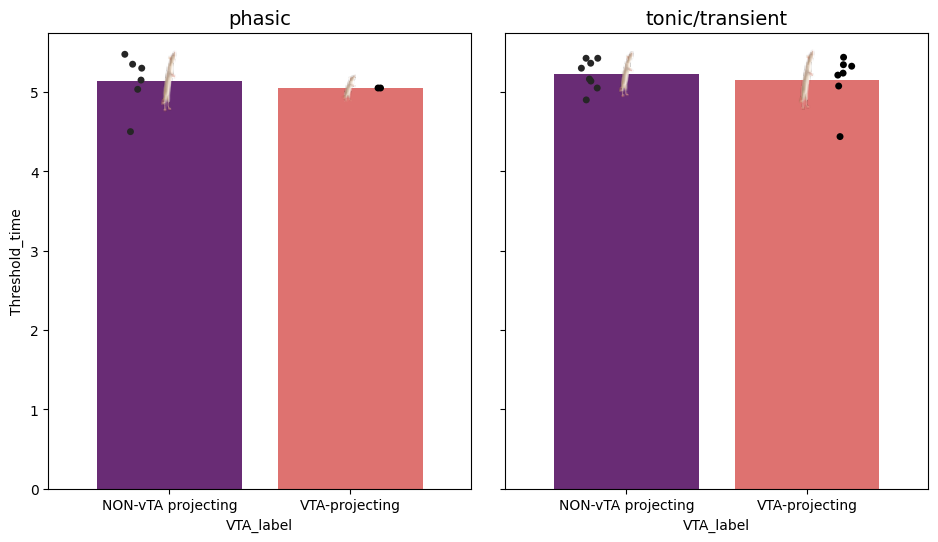

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to

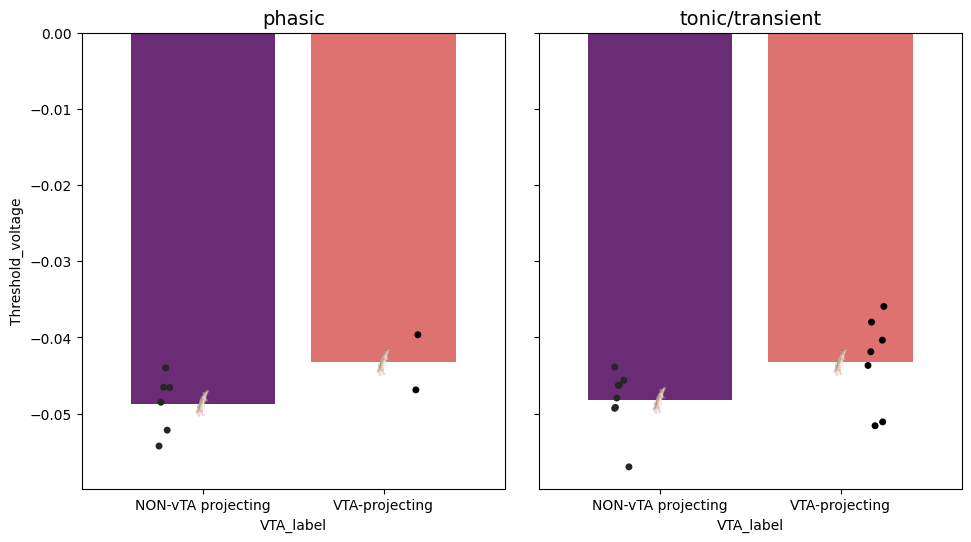

C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\2190358642.py:74: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:87: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\basi_\AppData\Local\Temp\ipykernel_62580\3078029788.py:170: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.


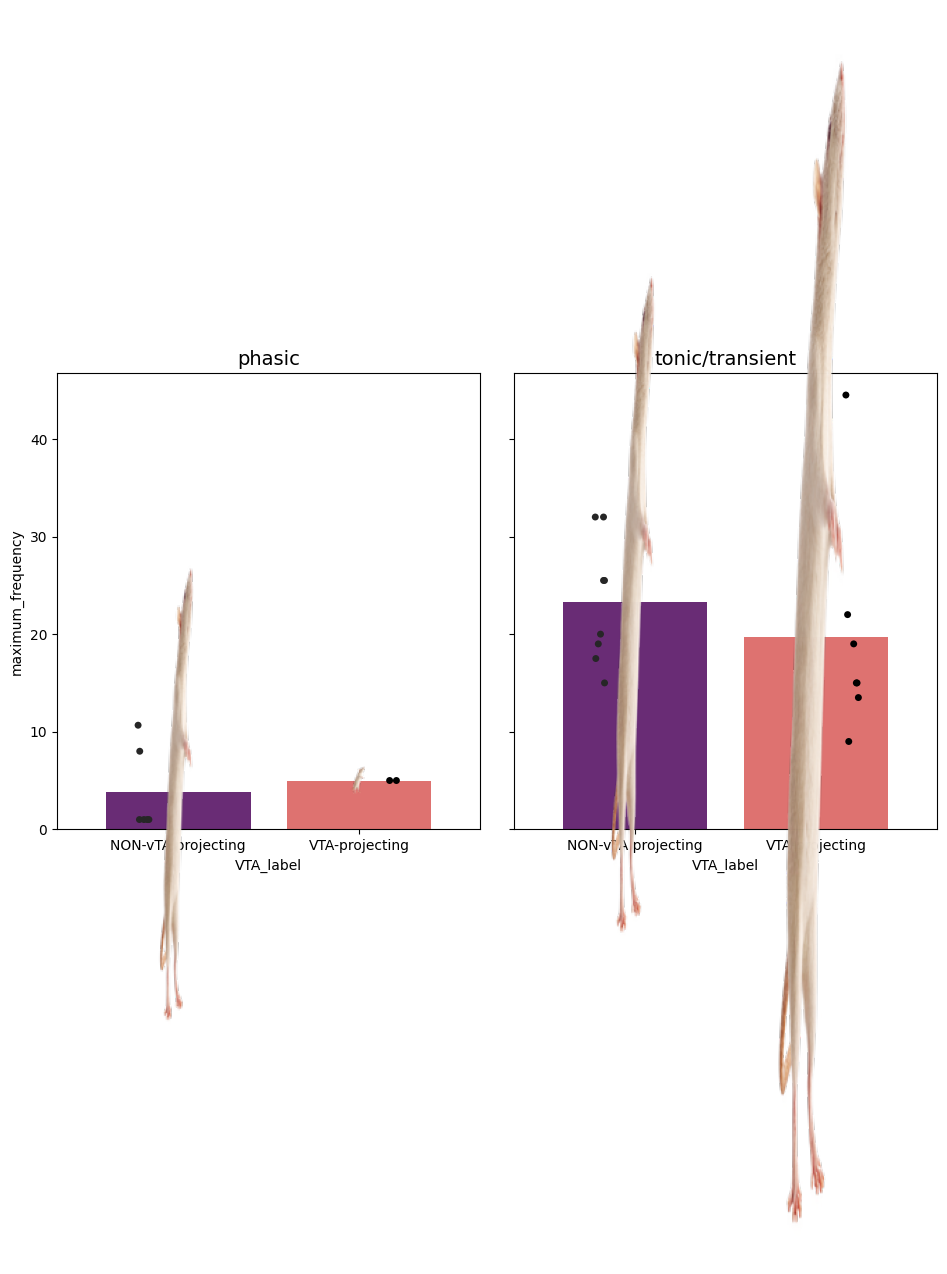

In [426]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

pic_path = r"Z:\invisi_rat.png"

for dv in dvs:

    # ---------------------------------------------------------
    # Down-sample: one value per cell
    # ---------------------------------------------------------
    if dv == "IR_slope":
        bird_scale = .1
    else:
        bird_scale = 75


    plot_df = (
        df[
            df.VTA_label.isin(
                ['NON-vTA projecting', 'VTA-projecting']
            )
        ]
        .groupby([
            'strain',
            'VTA_label',
            'pheno',
            'unique_cell_id',
            'date'
        ])[dv]
        .describe()
        .reset_index()
    )

    # ---------------------------------------------------------
    # Split data
    # ---------------------------------------------------------

    phasic = (
        plot_df[plot_df.pheno == 'phasic']
        .dropna(subset=['mean'])
    )

    tonic = (
        plot_df[plot_df.pheno == 'tonic/transient']
        .dropna(subset=['mean'])
    )

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------

    fig, axs = plt.subplots(
        1, 2,
        figsize=(10, 6),
        sharey=True
    )

    # ---------------------------------------------------------
    # Phasic
    # ---------------------------------------------------------

    zf_barplot(
        phasic,
        x='VTA_label',
        y='mean',
        ax=axs[0],
        title='phasic',
        image_path=pic_path,
        palette='magma',
        show_stats=False, scale_factor=bird_scale
    )

    sns.stripplot(
        x='VTA_label',
        y='mean',
        order=[
            'NON-vTA projecting',
            'VTA-projecting'
        ],
        data=phasic,
        ax=axs[0],
        dodge=.2,
        palette='dark:k'
    )

    # ---------------------------------------------------------
    # Tonic / transient
    # ---------------------------------------------------------

    zf_barplot(
        tonic,
        x='VTA_label',
        y='mean',
        ax=axs[1],
        title='tonic/transient',
        image_path=pic_path,
        palette='magma',
        show_stats=False,scale_factor=bird_scale
    )

    sns.stripplot(
        x='VTA_label',
        y='mean',
        order=[
            'NON-vTA projecting',
            'VTA-projecting'
        ],
        data=tonic,
        ax=axs[1],
        dodge=.2,
        palette='dark:k'
    )

    # ---------------------------------------------------------
    # Formatting
    # ---------------------------------------------------------

    axs[0].set_ylabel(dv)
    axs[1].set_ylabel("")

    # Keep titles compact
    axs[0].set_title("phasic", fontsize=14)
    axs[1].set_title("tonic/transient", fontsize=14)

    # Remove excess margins around categorical axes
    for ax in axs:
        ax.margins(x=0.15)

    # DON'T use plt.tight_layout() here
    fig.subplots_adjust(
        left=0.10,
        right=0.98,
        bottom=0.12,
        top=0.88,
        wspace=0.08
    )

    plt.show()

In [414]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from PIL import Image


def zf_barplot(
    df,
    x,
    y,
    image_path=r"Z:\zf_full_transp.png",
    ax=None,
    figsize=(10, 10),
    base_height=20,
    scale_factor=50,
    fixed_width=20,
    palette="lightblue",
    title=None,
    ylim=None,
    show_stats=True
):
    """
    Bar plot with mean ± SE bars and zebra finch images scaled
    according to the SD of each x-category.

    Parameters
    ----------
    df : pandas.DataFrame
        DataFrame containing the data.

    x : str
        Column name containing the categorical x variable.

    y : str
        Column name containing the dependent variable.

    image_path : str
        Path to the image used for each category.

    figsize : tuple
        Figure size.

    base_height : float
        Minimum image height in pixels.

    scale_factor : float
        Controls how strongly image height scales with SD.

    fixed_width : float
        Base image width in pixels.

    bar_color : str
        Color of the bars.

    title : str or None
        Plot title.

    ylim : tuple or None
        Y-axis limits, e.g. (0, 16).

    show_stats : bool
        Whether to display mean ± SD above each image.
    """

    # ------------------------------------------------------------
    # Calculate statistics
    # ------------------------------------------------------------

    stats = (
        df.groupby(x)[y]
        .agg(["mean", "std"])
        .reset_index()
    )

    # ------------------------------------------------------------
    # Create plot
    # ------------------------------------------------------------

    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure

    sns.barplot(
        data=df,
        x=x,
        y=y,
        errorbar=("se", 0),
        ax=ax,
        palette=palette
    )

    # ------------------------------------------------------------
    # Load image
    # ------------------------------------------------------------

    img = Image.open(image_path)

    # ------------------------------------------------------------
    # Add images
    # ------------------------------------------------------------

    for x0, mean, std in zip(
        range(len(stats)),
        stats["mean"],
        stats["std"]
    ):

        # Image height scales with SD
        new_height = int(base_height + std * scale_factor)

        # Image width also scales slightly with SD
        new_width = int(
            fixed_width + std * scale_factor / 10
        )

        resized_img = img.resize(
            (new_width, new_height)
        )

        im = OffsetImage(
            np.array(resized_img),
            zoom=1
        )

        ab = AnnotationBbox(
            im,
            (x0, mean),
            frameon=False,
            box_alignment=(0.5, 0.5),
            zorder=10
        )

        ax.add_artist(ab)

    # ------------------------------------------------------------
    # Mean ± SD labels
    # ------------------------------------------------------------

    if show_stats:

        for x0, row in enumerate(stats.itertuples()):

            mean = row.mean
            sd = row.std

            ax.text(
                x0,
                mean + sd + 0.1,
                f"{mean:.2f} ± {sd:.2f}",
                ha="center",
                va="bottom",
                fontsize=10,
                fontweight="bold"
            )

    # ------------------------------------------------------------
    # Formatting
    # ------------------------------------------------------------

    if title is not None:
        ax.set_title(title, fontsize=27)

    if ylim is not None:
        ax.set_ylim(ylim)

    plt.tight_layout()

    return fig, ax

In [ ]:
# animation below

In [6]:
df = data.df
df.iloc[:2]

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rec_type,rec_mode,temperature,external_sol,internal_sol,SR,rawData,stimWave,fname,fpath
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,V-mon,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl


In [9]:
df = data.df

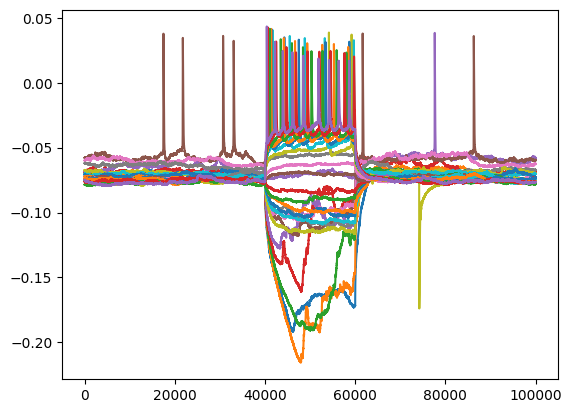

In [10]:
arrs = df.iloc[4].rawData.T
currs = df.iloc[4].stimWave.T


for i in range(len(arrs)):
    plt.plot(arrs[i])

In [42]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation


def animate_voltage_current(
    arrs,
    currs,
    sampling_rate=40000,
    interval=250,
    background_alpha=0.2
):

    wind = 15000
    mid = len(arrs[0])//2
    arrs = arrs[:,mid-wind:mid+wind]
    currs = currs[:,mid-wind:mid+wind]
    arrs = np.asarray(arrs)
    currs = np.asarray(currs)

    n_traces = len(arrs)

    # Time in ms
    t = np.arange(arrs.shape[1]) / sampling_rate * 1000

    # ---------------------------------------------------------
    # Predefined color palette
    # ---------------------------------------------------------

    colors = [
        "#0072B2",  # blue
        "#D55E00",  # orange
        "#009E73",  # green
        "#CC79A7",  # purple/pink
        "#E69F00",  # yellow-orange
        "#56B4E9",  # light blue
        "#F0E442",  # yellow
        "#000000",  # black
    ]

    # Repeat palette if there are more traces than colors
    trace_colors = [
        colors[i % len(colors)]
        for i in range(n_traces)
    ]

    # ---------------------------------------------------------
    # Figure
    # ---------------------------------------------------------

    fig, (ax1, ax2) = plt.subplots(
        2, 1,
        figsize=(10, 10),
        sharex=True
    )

    # ---------------------------------------------------------
    # Axes
    # ---------------------------------------------------------

    ax1.set_ylabel("Voltage (mV)")
    ax1.set_title("Voltage")
    ax1.set_xlim(t.min(), t.max())

    vmin = np.nanmin(arrs)
    vmax = np.nanmax(arrs)
    vrange = vmax - vmin

    ax1.set_ylim(
        vmin - 0.1 * vrange,
        vmax + 0.1 * vrange
    )

    ax2.set_xlabel("Time (ms)")
    ax2.set_ylabel("Current")
    ax2.set_xlim(t.min(), t.max())

    imin = np.nanmin(currs)
    imax = np.nanmax(currs)
    irange = imax - imin

    ax2.set_ylim(
        imin - 0.1 * irange,
        imax + 0.1 * irange
    )

    # ---------------------------------------------------------
    # Keep track of completed traces
    # ---------------------------------------------------------

    voltage_background = []
    current_background = []

    # Current active trace
    voltage_line, = ax1.plot(
        t,
        arrs[0],
        lw=1.5,
        color=trace_colors[0]
    )

    current_line, = ax2.plot(
        t,
        currs[0],
        lw=1.5,
        color=trace_colors[0]
    )

    title = fig.suptitle("Trace 1")

    # ---------------------------------------------------------
    # Animation
    # ---------------------------------------------------------

    def update(i):

        # Once we move to a new trace, save the previous one
        if i > 0:

            old_voltage, = ax1.plot(
                t,
                arrs[i - 1],
                lw=1,
                alpha=background_alpha,
                color=trace_colors[i - 1]
            )

            old_current, = ax2.plot(
                t,
                currs[i - 1],
                lw=1,
                alpha=background_alpha,
                color=trace_colors[i - 1]
            )

            voltage_background.append(old_voltage)
            current_background.append(old_current)

        # Current trace
        voltage_line.set_ydata(arrs[i])
        voltage_line.set_color(trace_colors[i])

        current_line.set_ydata(currs[i])
        current_line.set_color(trace_colors[i])

        # -----------------------------------------------------
        # Estimate injected current from middle of trace
        # -----------------------------------------------------

        mid_start = len(currs[i]) // 2 - len(currs[i]) // 10
        mid_end = len(currs[i]) // 2 + len(currs[i]) // 10

        injected_current = np.nanmedian(
            currs[i][mid_start:mid_end]
        )

        title.set_text(
            f"Trace {i + 1} / {n_traces}"
            f"     Injected current: {injected_current*1000:.0f}"
        )

        return (
            voltage_line,
            current_line,
            title,
            *voltage_background,
            *current_background
        )

    anim = FuncAnimation(
        fig,
        update,
        frames=np.arange(n_traces),
        interval=500,
        blit=False,
        repeat=False
    )

    plt.tight_layout()

    return anim

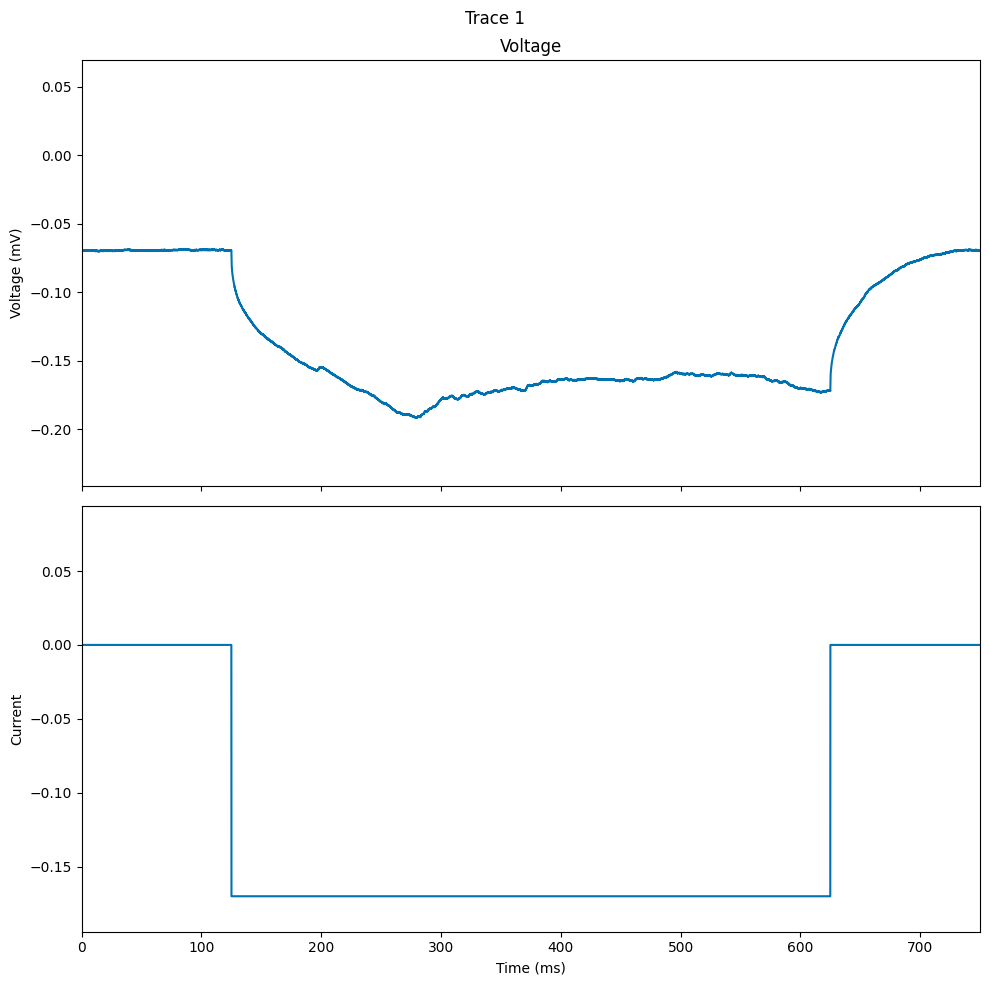

In [43]:
anim = animate_voltage_current(
    arrs,
    currs,
    sampling_rate=40000,
    interval=500,
    background_alpha=0.2
)

plt.show()

In [44]:
from matplotlib.animation import FFMpegWriter

writer = FFMpegWriter(fps=4)

anim.save(
    r"Z:\voltage_current.mp4",
    writer=writer
)

# Test Code Below!

In [184]:
datat = CClamp.load_data_singleFile(r"M:\mpoa\new\6-5-26struct_pickled_pkl")

datat.correct_holding_v_and_update_injections()
datat.detect_peaks(wind=10500, threshold_sd=100, distance=250, plot_all=False)
datat.calculate_ssv_ir(plot=False, ssv_window=7500, baseline_end=35000)
datat.calculate_rheo_ap_metrics(plot=False, use_smoothed=True, wind=350, smooth_window=25, smooth_polyorder=3)
datat.calculate_ap_decay_tau(plot=False,wind=350,sampling_rate=40000,smooth_window=25,smooth_polyorder=3,tau_bounds=(0.05, 10),seed=1)
datat.annotate_ap_points(wind=350,smooth_window=25,smooth_polyorder=3,sampling_rate=40000)

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled
6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled
6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


In [185]:
datat.df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt,A_fit,tau_fit,C_fit,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,3.419482,0.017308,0.030456,0.112502,1.450310,-0.047343,9.675,-0.041381,5.125,-0.044307
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,3.587631,0.017611,0.028742,0.116703,1.839174,-0.052523,10.375,-0.045143,4.900,-0.043900
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,4.008606,-0.008990,0.013641,0.114002,1.599403,-0.066371,9.575,-0.057752,5.300,-0.052182
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,5.342577,-0.000751,0.019369,0.107764,2.367330,-0.058545,10.275,-0.042887,5.300,-0.047524
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,3.950241,-0.004485,0.020195,0.106052,2.212695,-0.059329,10.250,-0.046437,5.275,-0.044170


In [180]:
df.fname.unique()

array(['1-13-26struct.mat', '1-21-26struct.mat', '1-29-26struct.mat',
       '6-5-26struct.mat', '8-5-26struct.mat', '9-10-26struct.mat',
       '9-14-26struct.mat', '9-7-26struct.mat'], dtype=object)

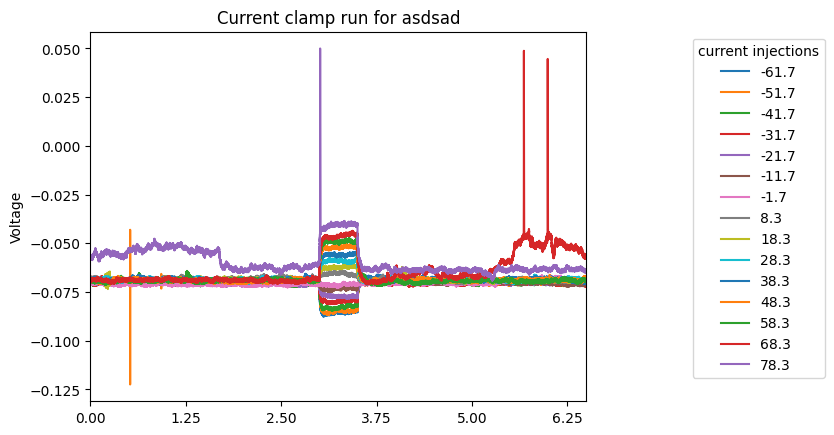

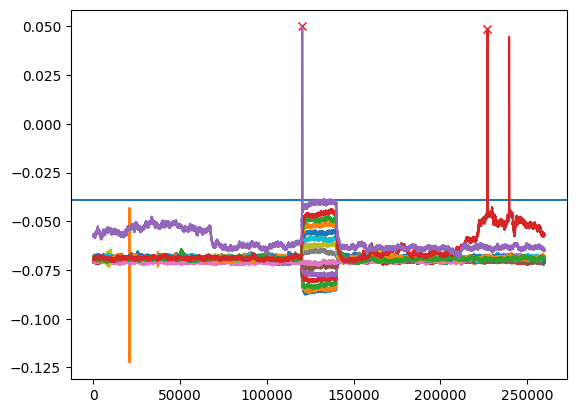

Text(0.5, 1.0, 'FI plot for asdsad')

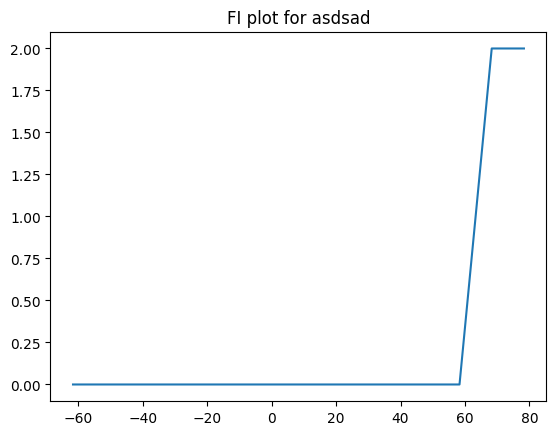

In [ ]:
arrs = data.df.iloc[1].rawData.T
currs = data.df.iloc[1].corrected_injections
for idx, arr in enumerate(arrs):
    plt.plot(arr, label = round(currs[0][idx], 2))
plt.legend(title='current injections', bbox_to_anchor=(1.2,1))

plt.ylabel('Voltage')

time_ticks, _ = plt.xticks()

plt.xticks(
    time_ticks,
    [f"{x / sr:.2f}" for x in time_ticks]
)
plt.margins(x=0)
plt.title('Current clamp run for '+cell_id)
plt.show()

if show_peaks:
    from scipy.signal import find_peaks

    wind=10500
    mid = len(arr)//2

    height = np.mean(arr[mid-200:mid+200]) + np.std(arr[mid-200:mid+200])*height_factor
    plt.axhline(height)
    #arrs = arrs.values[0]
    peak_freq = []
    for idx, arr in enumerate(arrs):
        peaks, _ = find_peaks(arr, height=height, distance=distance)
        plt.plot(peaks, arr[peaks], 'x', c='r')
        plt.plot(arr)
        peak_freq.append(len(peaks)/.5)

    plt.show()
    plt.plot(currs, peak_freq)
    plt.title('FI plot for '+cell_id)

In [12]:


arrs = arrs.values[0]
for arr in arrs:
    plt.plot(arr)

AttributeError: 'numpy.ndarray' object has no attribute 'values'

In [69]:
print(type(tmp.rawData))
print(np.asarray(tmp.rawData).shape)
print(type(arrs))
print(np.asarray(arrs).shape)

for idx, arr in enumerate(arrs):
    print(idx, np.asarray(arr).shape)

<class 'pandas.core.series.Series'>
(1,)
<class 'pandas.core.series.Series'>
(1,)
0 (260000, 15)


In [44]:
round(currs[0][0],2)

np.float64(-77.38)

In [47]:
tmp

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,internal_sol,SR,rawData,stimWave,fname,fpath,V_hold_mV,current_injections,corrected_injections,combo
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,M:\mpoa\new\6-5-26struct_pickled_pkl,-18.304873,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.69512663330609, -51.69512663330609, -41.6...",6-5-26_2_1


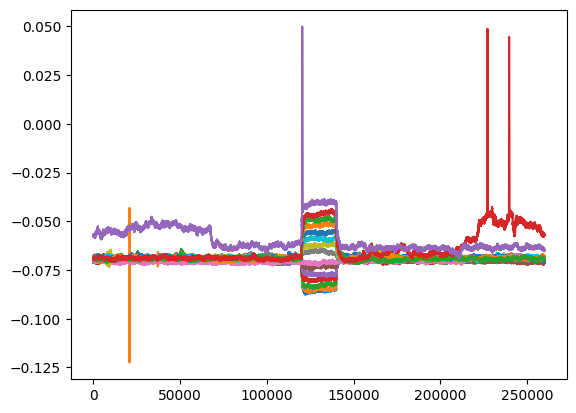

In [48]:
tmp = data.df[data.df.combo == '6-5-26_2_1'].reset_index(drop=True)

arrs = tmp.rawData.T
currs = tmp.corrected_injections
for idx, arr in enumerate(arrs):
    plt.plot(arr, label = round(currs[0][idx], 2))

In [2]:
df = pd.read_pickle(r"M:\mpoa\new\6-5-26struct_pickled_pkl")
df = df[df.series_name.isin(['Rudi', 'Garrett'])].reset_index(drop=True)

In [3]:
wind=10500

all_freqs = []
all_peaks = []
for i in range(len(df)):
    tmp = df.iloc[i]
    arrs = tmp.rawData.T

    peak_freqs = []
    peakies = []
    for idx, arr in enumerate(arrs):

        mid = len(arr)//2
        height = np.mean(arr[mid-200:mid+200]) + np.std(arr[mid-200:mid+200])*100
        peak_num = []

        peaks, _ = find_peaks(arr[mid-wind:mid+wind], height=height, distance=250)
        peak_freqs.append(len(peaks)/.5)
        peaks+= mid-wind
        peaks = peaks[arr[peaks] > 0] #check that is is a positive AP, otherwise likely not something real.. 
        peakies.append(peaks)
    all_freqs.append(peak_freqs)
    all_peaks.append(peakies)

df['all_freqs'] = [x for x in all_freqs]
df['all_peaks'] = [x for x in all_peaks]
df.iloc[:2]

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rec_mode,temperature,external_sol,internal_sol,SR,rawData,stimWave,fname,all_freqs,all_peaks
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [..."
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,C-clamp,20.0,NaN,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [..."


In [ ]:
import numpy as np
import tkinter as tk
from scipy.signal import find_peaks

from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg


def tune_find_peaks(trace, sampling_rate=40000):

    trace = np.asarray(trace)

    # ============================================================
    # INITIAL PARAMETERS
    # ============================================================

    height = np.mean(trace) + np.std(trace) * 5
    distance = 250
    prominence = None

    current_peaks = []

    # ============================================================
    # PEAK DETECTION WINDOW
    # ============================================================

    mid = len(trace) // 2
    wind = 10500

    start = mid - wind
    end = mid + wind

    detection_trace = trace[start:end]

    # ============================================================
    # TKINTER WINDOW
    # ============================================================

    root = tk.Tk()
    root.title("Tune find_peaks")

    # Flag for aborting
    aborted = False

    # ============================================================
    # FIGURE
    # ============================================================

    fig = Figure(figsize=(10, 5))
    ax = fig.add_subplot(111)

    canvas = FigureCanvasTkAgg(
        fig,
        master=root
    )

    canvas.draw()

    canvas.get_tk_widget().pack(
        side=tk.TOP,
        fill=tk.BOTH,
        expand=True
    )

    # ============================================================
    # CONTROLS
    # ============================================================

    control_frame = tk.Frame(root)
    control_frame.pack(
        fill=tk.X,
        pady=5
    )

    # ------------------------------------------------------------
    # HEIGHT
    # ------------------------------------------------------------

    tk.Label(
        control_frame,
        text="Height"
    ).grid(row=0, column=0)

    height_min = np.min(trace)
    height_max = np.max(trace) + 2 * np.ptp(trace)

    height_var = tk.DoubleVar(value=height)

    height_value_label = tk.Label(
        control_frame,
        text=f"{height_var.get():.3f}"
    )
    height_value_label.grid(row=0, column=2)

    height_scale = tk.Scale(
        control_frame,
        variable=height_var,
        from_=height_min,
        to=height_max,
        resolution=0.01,
        orient=tk.HORIZONTAL,
        length=250
    )
    height_scale.grid(row=0, column=1)

    # ------------------------------------------------------------
    # DISTANCE
    # ------------------------------------------------------------

    tk.Label(
        control_frame,
        text="Distance"
    ).grid(row=1, column=0)

    distance_var = tk.IntVar(value=distance)

    distance_value_label = tk.Label(
        control_frame,
        text=f"{distance_var.get()}"
    )
    distance_value_label.grid(row=1, column=2)

    distance_scale = tk.Scale(
        control_frame,
        variable=distance_var,
        from_=1,
        to=2000,
        resolution=1,
        orient=tk.HORIZONTAL,
        length=250
    )
    distance_scale.grid(row=1, column=1)

    # ------------------------------------------------------------
    # PROMINENCE
    # ------------------------------------------------------------

    tk.Label(
        control_frame,
        text="Prominence"
    ).grid(row=2, column=0)

    prominence_var = tk.DoubleVar(value=0)

    prominence_value_label = tk.Label(
        control_frame,
        text=f"{prominence_var.get():.3f}"
    )
    prominence_value_label.grid(row=2, column=2)

    prominence_scale = tk.Scale(
        control_frame,
        variable=prominence_var,
        from_=0,
        to=10 * np.std(trace),
        resolution=0.01,
        orient=tk.HORIZONTAL,
        length=250
    )
    prominence_scale.grid(row=2, column=1)

    # ============================================================
    # UPDATE PLOT
    # ============================================================

    def update_plot():

        nonlocal current_peaks

        height_value = height_var.get()
        distance_value = distance_var.get()
        prominence_value = prominence_var.get()

        height_value_label.config(
            text=f"{height_value:.3f}"
        )

        distance_value_label.config(
            text=f"{distance_value}"
        )

        prominence_value_label.config(
            text=f"{prominence_value:.3f}"
        )

        if prominence_value == 0:
            prominence_value = None

        peaks, properties = find_peaks(
            detection_trace,
            height=height_value,
            distance=distance_value,
            prominence=prominence_value
        )

        # Convert detection-window indices back
        # to indices in the original trace.
        current_peaks = peaks + start

        ax.clear()

        time = np.arange(len(trace)) * (
            1000 / sampling_rate
        )

        ax.plot(
            time,
            trace,
            label="Trace"
        )

        # Detection boundaries
        ax.axvline(
            start * (1000 / sampling_rate),
            linestyle="--",
            alpha=0.5
        )

        ax.axvline(
            end * (1000 / sampling_rate),
            linestyle="--",
            alpha=0.5
        )

        if len(current_peaks) > 0:

            ax.plot(
                current_peaks * (1000 / sampling_rate),
                trace[current_peaks],
                'x',
                markersize=8,
                label=f"Peaks ({len(current_peaks)})"
            )

        ax.set_xlabel("Time (ms)")
        ax.set_ylabel("Voltage")

        ax.set_title(
            f"Detected peaks: {len(current_peaks)}"
        )

        ax.legend()

        canvas.draw()

    # ============================================================
    # BUTTONS
    # ============================================================

    button_frame = tk.Frame(root)
    button_frame.pack(pady=5)

    update_button = tk.Button(
        button_frame,
        text="Update",
        command=update_plot,
        width=15
    )

    update_button.pack(
        side=tk.LEFT,
        padx=5
    )

    # ------------------------------------------------------------
    # COMMIT
    # ------------------------------------------------------------

    def commit():

        root.quit()
        root.destroy()

    commit_button = tk.Button(
        button_frame,
        text="Commit",
        command=commit,
        width=15
    )

    commit_button.pack(
        side=tk.LEFT,
        padx=5
    )

    # ------------------------------------------------------------
    # ABORT
    # ------------------------------------------------------------

    def abort():

        nonlocal aborted

        aborted = True

        root.quit()
        root.destroy()

    abort_button = tk.Button(
        button_frame,
        text="Abort",
        command=abort,
        width=15
    )

    abort_button.pack(
        side=tk.LEFT,
        padx=5
    )

    # ============================================================
    # INITIAL PLOT
    # ============================================================

    update_plot()

    root.mainloop()

    # ============================================================
    # HANDLE ABORT
    # ============================================================

    if aborted:
        raise KeyboardInterrupt("Peak tuning aborted by user.")

    return current_peaks


plot=True

all_peaks = []
for i in range(len(df)):

    traces = df.iloc[i].rawData.T
    currs = df.iloc[i].corrected_injections
    combo = df.iloc[i].combo
    pikies = []
    for trace in traces:

        peaks = tune_find_peaks(trace)

        pikies.append(peaks)

    if plot:
        #make the FI plot if desired
        freqs = [len(x)/.5 for x in pikies]
        plt.plot(currs, freqs)
        plt.title('FI plot for '+combo)

    all_peaks.append(pikies)
df['peak_positions'] = [x for x in all_peaks]

In [ ]:
plot=True

all_peaks = []
for i in range(len(df)):

    traces = df.iloc[i].rawData.T
    currs = df.iloc[i].corrected_injections
    combo = df.iloc[i].combo
    pikies = []
    for trace in traces:

        peaks = tune_find_peaks(trace)

        pikies.append(peaks)

    if plot:
        #make the FI plot if desired
        freqs = [len(x)/.5 for x in pikies]
        plt.plot(currs, freqs)
        plt.title('FI plot for '+combo)

    all_peaks.append(pikies)
df['peak_positions'] = [x for x in all_peaks]

KeyboardInterrupt: Peak tuning aborted by user.

In [ ]:
traces = df.iloc[1].rawData.T
currs = df.iloc[1].corrected_injections
combo = df.iloc[1].combo
pikies = []
for trace in traces:

    peaks = tune_find_peaks(trace)

    pikies.append(peaks)

if plot:
    #make the FI plot if desired
    freqs = [len(x)/.5 for x in pikies]
    plt.plot(currs, freqs)
    plt.title('FI plot for '+combo)

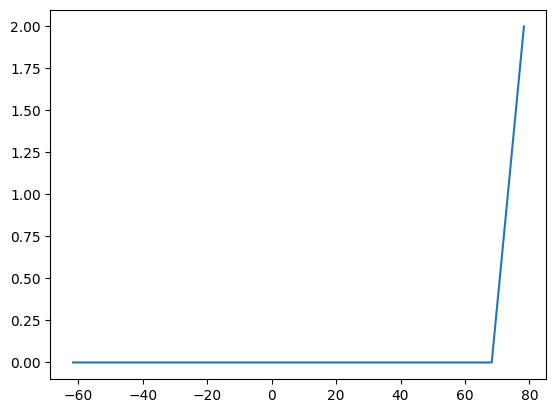

[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

In [50]:
10500*2/40000

0.525

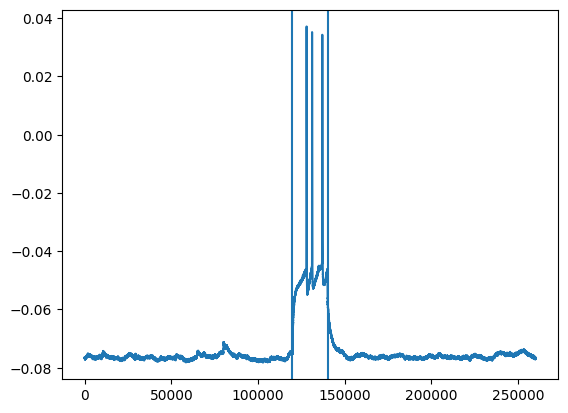

In [49]:
plt.plot(rheo)
plt.axvline(len(rheo)//2-10500)
plt.axvline(len(rheo)//2+10500)

In [39]:
import numpy as np


def calculate_ap_half_width(smoothed, threshold_voltage, sampling_rate=40000):

    smoothed = np.asarray(smoothed)

    dt = 1000 / sampling_rate  # ms/sample

    # Find AP peak
    peak_idx = np.argmax(smoothed)
    peak_voltage = smoothed[peak_idx]

    # Half-amplitude voltage
    half_voltage = (
        threshold_voltage
        + (peak_voltage - threshold_voltage) / 2
    )

    # --------------------------------------------------
    # Rising phase
    # --------------------------------------------------

    rising = smoothed[:peak_idx + 1]

    # Last point below half voltage before peak
    below = np.where(rising < half_voltage)[0]

    if len(below) == 0:
        return np.nan

    rising_idx = below[-1]

    # --------------------------------------------------
    # Falling phase
    # --------------------------------------------------

    falling = smoothed[peak_idx:]

    # First point below half voltage after peak
    below = np.where(falling < half_voltage)[0]

    if len(below) == 0:
        return np.nan

    falling_idx = peak_idx + below[0]

    # --------------------------------------------------
    # Interpolate crossing times
    # --------------------------------------------------

    # Rising crossing
    x1 = rising_idx
    x2 = rising_idx + 1

    y1 = smoothed[x1]
    y2 = smoothed[x2]

    rising_crossing = x1 + (
        (half_voltage - y1) / (y2 - y1)
    )

    # Falling crossing
    x1 = falling_idx - 1
    x2 = falling_idx

    y1 = smoothed[x1]
    y2 = smoothed[x2]

    falling_crossing = x1 + (
        (half_voltage - y1) / (y2 - y1)
    )

    # Convert samples to ms
    half_width = (
        falling_crossing - rising_crossing
    ) * dt

    return half_width

In [42]:
threshold_voltage=np.median(smoothed[:150])

half_width = calculate_ap_half_width(
    smoothed,
    threshold_voltage
)

print(half_width)

2.1187075617534292


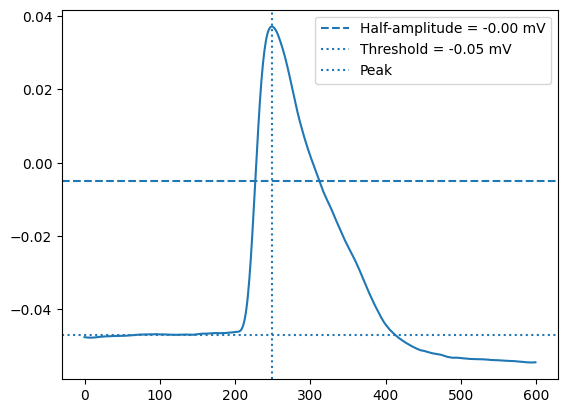

In [43]:
import matplotlib.pyplot as plt

peak_idx = np.argmax(smoothed)
peak_voltage = smoothed[peak_idx]

half_voltage = (
    threshold_voltage
    + (peak_voltage - threshold_voltage) / 2
)

plt.plot(smoothed)

plt.axhline(
    half_voltage,
    linestyle='--',
    label=f'Half-amplitude = {half_voltage:.2f} mV'
)

plt.axhline(
    threshold_voltage,
    linestyle=':',
    label=f'Threshold = {threshold_voltage:.2f} mV'
)

plt.axvline(
    peak_idx,
    linestyle=':',
    label='Peak'
)

plt.legend()
plt.show()

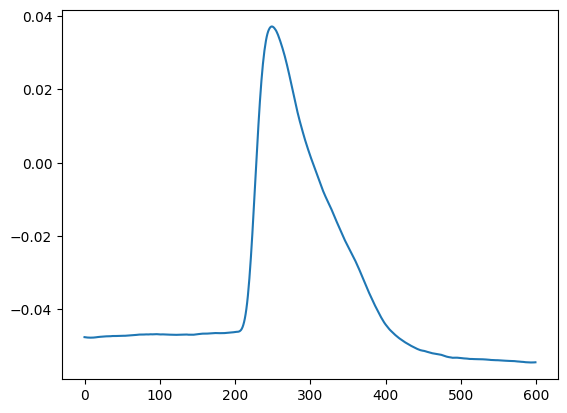

In [38]:
plt.plot(smoothed)

In [5]:
peaks

array([121274, 123412, 125104, 126985, 129120, 130830, 132895, 135479,
       137653, 139554])

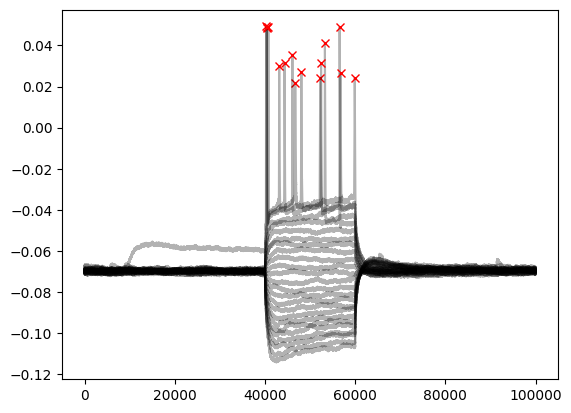

In [4]:
tmp = df.iloc[2]

arrs = tmp.rawData.T
peaks = tmp.all_peaks

for idx, arr in enumerate(arrs):
    ps = peaks[idx]
    plt.plot(arr, c='k', alpha=.3)
    plt.plot(ps, arr[ps], 'x', c='r')

In [9]:
plot=False
use_smoothed=True


waves = []
smoothed_waves = []
max_dvdt = []
min_dvdt = []
dvdt_ratio = []
voltage_at_max_dvdt = []
voltage_at_min_dvdt = []

for i in range(len(df)):


    tmp = df.iloc[i]

    arrs = tmp.rawData.T
    peaks = tmp.all_peaks
    if plot:
        for idx, arr in enumerate(arrs):
            ps = peaks[idx]
            plt.plot(arr, c='k', alpha=.3) #view all traces of this series and overlay detected peaks
            plt.plot(ps, arr[ps], 'x', c='r')
        plt.show()



    # get the rheobase, the first injection that contains an AP (this time we keep the first trace with a detected action potential)
    for idx, peak in enumerate(peaks):
        if len(peak) != 0:
            break
    rheo = arrs[idx]

    try: #check, it could be that the series has NO action potentials, need to take care of this
        peak=peak[0]
    except:
        print(tmp.combo+' did not have any detected peaks, skipped and NaN-filled')
        max_dvdt.append(np.nan)
        min_dvdt.append(np.nan)
        dvdt_ratio.append(np.nan)
        voltage_at_max_dvdt.append(np.nan)
        voltage_at_min_dvdt.append(np.nan)
        waves.append(np.nan)
        smoothed_waves.append(np.nan)
        continue

    wind=350
    if plot:
        plt.plot(peak, rheo[peak], 'x') #view trace and peak
        plt.plot(rheo)
        plt.show()

    from scipy.signal import savgol_filter



    wave = rheo[peak-wind+100:peak+wind]
    smoothed = savgol_filter(wave, window_length=25, polyorder=3)
    if plot:
        plt.plot(wave) #raw plot
        plt.plot(smoothed) #smooth plot
        plt.show()
        plt.plot(smoothed, np.gradient(smoothed))  #phase-plane trajectory

    if use_smoothed:
        max_dvdt.append(np.max(np.gradient(smoothed)))
        min_dvdt.append(np.min(np.gradient(smoothed)))
        dvdt_ratio.append(np.max(np.gradient(smoothed))/abs(np.min(np.gradient(smoothed))))

        voltage_at_max_dvdt.append(smoothed[np.argmax(np.gradient(smoothed))])
        voltage_at_min_dvdt.append(smoothed[np.argmin(np.gradient(smoothed))])
    else:
        max_dvdt.append(np.max(np.gradient(wave)))
        min_dvdt.append(np.min(np.gradient(wave)))
        dvdt_ratio.append(np.max(np.gradient(wave))/abs(np.min(np.gradient(wave))))

        voltage_at_max_dvdt.append(wave[np.argmax(np.gradient(wave))])
        voltage_at_min_dvdt.append(wave[np.argmin(np.gradient(wave))])
    waves.append(wave)
    smoothed_waves.append(smoothed)

df['rheo_AP_trace'] = waves
df['smoothed_rheo_AP_trace'] = smoothed_waves
df['max_dvdt'] = max_dvdt
df['min_dvdt'] = min_dvdt
df['dvdt_ratio'] = dvdt_ratio
df['voltage_at_max_dvdt'] = voltage_at_max_dvdt
df['voltage_at_min_dvdt'] = voltage_at_min_dvdt



6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


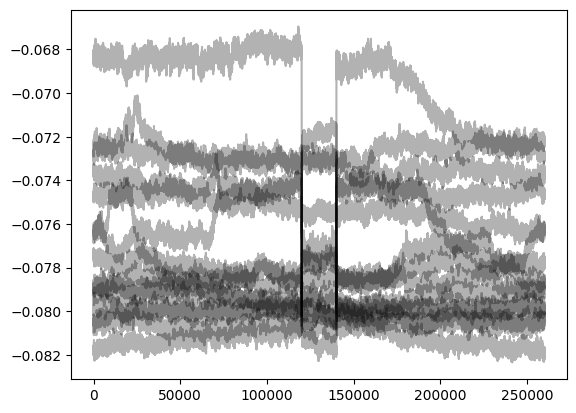

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


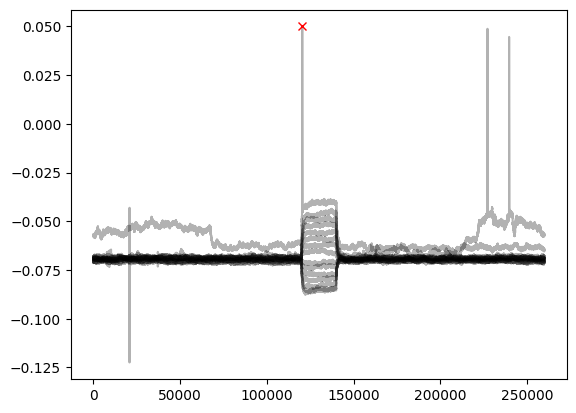

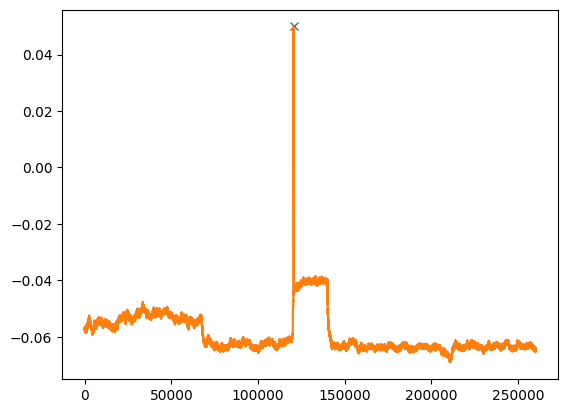

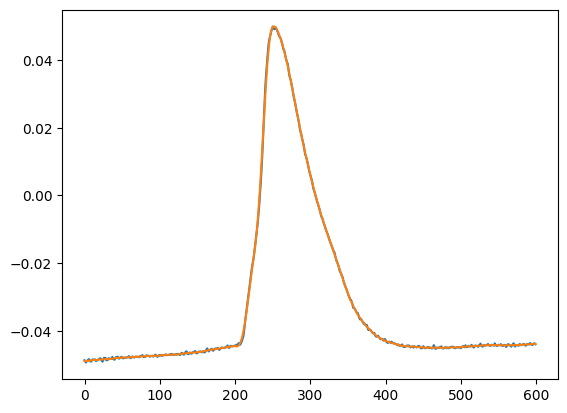

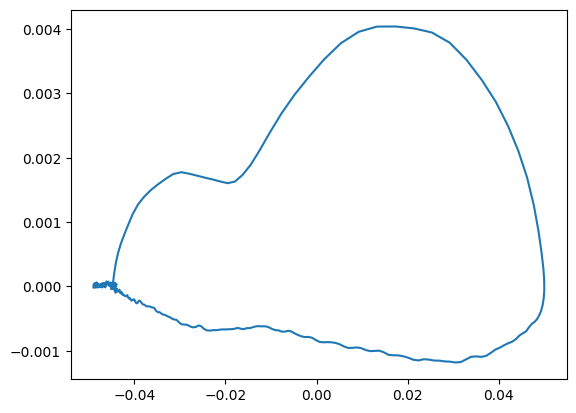

In [74]:
plot=True
use_smoothed=True


waves = []
smoothed_waves = []
max_dvdt = []
min_dvdt = []
dvdt_ratio = []
voltage_at_max_dvdt = []
voltage_at_min_dvdt = []

for i in range(len(df))[:2]:


    tmp = df.iloc[i]

    arrs = tmp.rawData.T
    peaks = tmp.all_peaks
    if plot:
        for idx, arr in enumerate(arrs):
            ps = peaks[idx]
            plt.plot(arr, c='k', alpha=.3) #view all traces of this series and overlay detected peaks
            plt.plot(ps, arr[ps], 'x', c='r')
        plt.show()



    # get the rheobase, the first injection that contains an AP (this time we keep the first trace with a detected action potential)
    for idx, peak in enumerate(peaks):
        if len(peak) != 0:
            break
    rheo = arrs[idx]

    try: #check, it could be that the series has NO action potentials, need to take care of this
        peak=peak[0]
    except:
        print(tmp.combo+' did not have any detected peaks, skipped and NaN-filled')
        max_dvdt.append(np.nan)
        min_dvdt.append(np.nan)
        dvdt_ratio.append(np.nan)
        voltage_at_max_dvdt.append(np.nan)
        voltage_at_min_dvdt.append(np.nan)
        waves.append(np.nan)
        smoothed_waves.append(np.nan)
        continue

    wind=350
    if plot:
        plt.plot(peak, rheo[peak], 'x') #view trace and peak
        plt.plot(rheo)
        plt.show()

    from scipy.signal import savgol_filter



    wave = rheo[peak-wind+100:peak+wind]
    smoothed = savgol_filter(wave, window_length=25, polyorder=3)
    if plot:
        plt.plot(wave) #raw plot
        plt.plot(smoothed) #smooth plot
        plt.show()
        plt.plot(smoothed, np.gradient(smoothed))  #phase-plane trajectory

    if use_smoothed:
        max_dvdt.append(np.max(np.gradient(smoothed)))
        min_dvdt.append(np.min(np.gradient(smoothed)))
        dvdt_ratio.append(np.max(np.gradient(smoothed))/abs(np.min(np.gradient(smoothed))))

        voltage_at_max_dvdt.append(smoothed[np.argmax(np.gradient(smoothed))])
        voltage_at_min_dvdt.append(smoothed[np.argmin(np.gradient(smoothed))])
    else:
        max_dvdt.append(np.max(np.gradient(wave)))
        min_dvdt.append(np.min(np.gradient(wave)))
        dvdt_ratio.append(np.max(np.gradient(wave))/abs(np.min(np.gradient(wave))))

        voltage_at_max_dvdt.append(wave[np.argmax(np.gradient(wave))])
        voltage_at_min_dvdt.append(wave[np.argmin(np.gradient(wave))])
    waves.append(wave)
    smoothed_waves.append(smoothed)





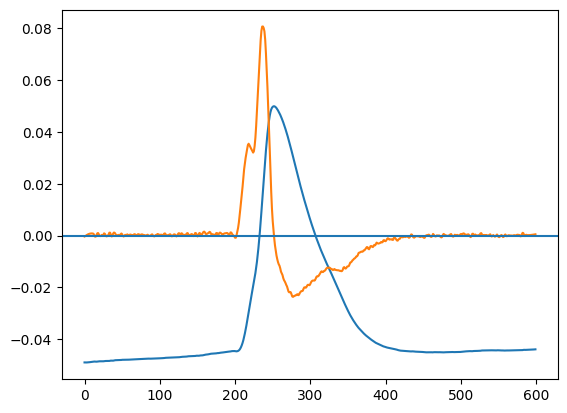

In [ ]:
plt.plot(smoothed)
plt.plot(np.gradient(smoothed)*20)
#plt.axvline(np.argmin(np.gradient(smoothed)))
plt.axhline(0)



#plt.plot(np.gradient(np.gradient(smoothed))*50)

In [10]:
df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,ssvs,ssvs_delta,IR_slope,rheo_AP_trace,smoothed_rheo_AP_trace,max_dvdt,min_dvdt,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,"[-0.0771601339960961, -0.08143813414076014, -0...","[-0.00874335795989753, -0.008805810516753831, ...",121.672679,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[-0.08565368172856774, -0.08490425104629096, -...","[-0.01626889106109501, -0.015425781543533593, ...",316.078567,"[-0.048744220626428886, -0.04911893596756736, ...","[-0.048947314206195934, -0.048962793899775724,...",0.004039,-0.001181,3.419482,0.017308,0.030456
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,"[-0.10851131753801432, -0.10641915688332458, -...","[-0.03909530059211319, -0.03731540272170572, -...",317.007770,"[-0.045434235113039005, -0.045652819062036123,...","[-0.04553703095405951, -0.04549344760989438, -...",0.003521,-0.000982,3.587631,0.017611,0.028742
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,"[-0.11559968274121708, -0.11413204765509147, -...","[-0.04627734463060046, -0.04590262928946194, -...",363.587153,"[-0.0627960459191211, -0.0627648196406933, -0....","[-0.06297459617782622, -0.06293002533596725, -...",0.003917,-0.000977,4.008606,-0.008990,0.013641
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,"[-0.16443758220293075, -0.18064402070716962, -...","[-0.0951776966491704, -0.11016631029470973, -0...",667.477008,"[-0.04933751991656506, -0.049556103865562404, ...","[-0.04944325156154044, -0.049455795451165435, ...",0.004374,-0.000819,5.342577,-0.000751,0.019369
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,"[-0.1092607482202913, -0.10704368245188861, -0...","[-0.03959492104696444, -0.03587899391400787, -...",712.697224,"[-0.04755762204615695, -0.047620074603013575, ...","[-0.04754776842051976, -0.04758094300520888, -...",0.003772,-0.000955,3.950241,-0.004485,0.020195


In [ ]:
import numpy as np
import tkinter as tk
from matplotlib.figure import Figure
from matplotlib.backends.backend_tkagg import FigureCanvasTkAgg


def select_ap_points(smoothed, sampling_rate=40000):

    smoothed = np.asarray(smoothed)
    x = np.arange(len(smoothed))

    dt = 1000 / sampling_rate  # ms/sample

    root = tk.Tk()
    root.title("Select AP Threshold and AHP")

    fig = Figure(figsize=(10, 5))
    ax = fig.add_subplot(111)

    ax.plot(x * dt, smoothed)

    ax.set_xlabel("Time (ms)")
    ax.set_ylabel("Voltage (mV)")
    ax.set_title(
        "Click THRESHOLD, then AHP"
    )

    canvas = FigureCanvasTkAgg(fig, master=root)
    canvas.draw()
    canvas.get_tk_widget().pack(fill=tk.BOTH, expand=True)

    # Store selected sample indices
    threshold_idx = None
    ahp_idx = None

    threshold_marker = None
    ahp_marker = None

    def update_markers():

        nonlocal threshold_marker, ahp_marker

        # Remove existing markers
        if threshold_marker is not None:
            threshold_marker.remove()

        if ahp_marker is not None:
            ahp_marker.remove()

        # Threshold marker
        if threshold_idx is not None:
            threshold_marker, = ax.plot(
                threshold_idx * dt,
                smoothed[threshold_idx],
                'o',
                markersize=8,
                label='Threshold'
            )

        # AHP marker
        if ahp_idx is not None:
            ahp_marker, = ax.plot(
                ahp_idx * dt,
                smoothed[ahp_idx],
                'o',
                markersize=8,
                label='AHP'
            )

        # Update legend
        if threshold_idx is not None or ahp_idx is not None:
            ax.legend()

        canvas.draw()

    def onclick(event):

        nonlocal threshold_idx, ahp_idx

        if event.inaxes != ax:
            return

        if event.xdata is None:
            return

        # Convert clicked time back to sample index
        clicked_idx = int(
            np.clip(
                np.round(event.xdata / dt),
                0,
                len(smoothed) - 1
            )
        )

        # --------------------------------------------------
        # First click = threshold
        # --------------------------------------------------

        if threshold_idx is None:

            threshold_idx = clicked_idx

            ax.set_title(
                "Threshold selected — click AHP"
            )

        # --------------------------------------------------
        # Second click = AHP
        # --------------------------------------------------

        elif ahp_idx is None:

            ahp_idx = clicked_idx

            ax.set_title(
                "Review points — click to adjust, then Commit"
            )

        # --------------------------------------------------
        # Subsequent clicks:
        # assign click to whichever existing point is closer
        # --------------------------------------------------

        else:

            distance_threshold = abs(
                clicked_idx - threshold_idx
            )

            distance_ahp = abs(
                clicked_idx - ahp_idx
            )

            if distance_threshold <= distance_ahp:
                threshold_idx = clicked_idx
            else:
                ahp_idx = clicked_idx

        update_markers()

    def commit():

        # Don't allow commit until both points exist
        if threshold_idx is None or ahp_idx is None:
            ax.set_title(
                "Please select both Threshold and AHP before committing"
            )
            canvas.draw()
            return

        root.quit()
        root.destroy()

    canvas.mpl_connect(
        'button_press_event',
        onclick
    )

    # ------------------------------------------------------
    # Commit button
    # ------------------------------------------------------

    button_frame = tk.Frame(root)
    button_frame.pack(pady=5)

    commit_button = tk.Button(
        button_frame,
        text="Commit",
        command=commit,
        width=15
    )

    commit_button.pack()

    root.mainloop()

    # ------------------------------------------------------
    # Return results
    # ------------------------------------------------------

    if threshold_idx is None or ahp_idx is None:
        return {
            'AHP_time': np.nan,
            'AHP_voltage': np.nan,
            'Threshold_time': np.nan,
            'Threshold_voltage': np.nan
        }

    return {
        'AHP_time': ahp_idx * dt,
        'AHP_voltage': smoothed[ahp_idx],
        'Threshold_time': threshold_idx * dt,
        'Threshold_voltage': smoothed[threshold_idx]
    }
results = []
for i in range(len(df)):
    tmp = df.iloc[i]

    arrs = tmp.rawData.T
    peaks = tmp.all_peaks

    # get the rheobase, the first injection that contains an AP (this time we keep the first trace with a detected action potential)
    for idx, peak in enumerate(peaks):
        if len(peak) != 0:
            break
    rheo = arrs[idx]

    try: #check, it could be that the series has NO action potentials, need to take care of this
        peak=peak[0]
    except:
        print(tmp.combo+' did not have any detected peaks, skipped and NaN-filled')
        continue

    wind=350

    from scipy.signal import savgol_filter

    wave = rheo[peak-wind+100:peak+wind]
    smoothed = savgol_filter(wave, window_length=25, polyorder=3)
    result = select_ap_points(smoothed)
    tmp = pd.DataFrame([result])
    tmp['combo'] = tmp.combo
    results.append(tmp)
results = pd.concat(results)

In [ ]:
results = []
for i in range(len(df)):
    tmp = df.iloc[i]

    arrs = tmp.rawData.T
    peaks = tmp.all_peaks

    # get the rheobase, the first injection that contains an AP (this time we keep the first trace with a detected action potential)
    for idx, peak in enumerate(peaks):
        if len(peak) != 0:
            break
    rheo = arrs[idx]

    try: #check, it could be that the series has NO action potentials, need to take care of this
        peak=peak[0]
    except:
        print(tmp.combo+' did not have any detected peaks, skipped and NaN-filled')
        continue

    wind=350

    from scipy.signal import savgol_filter

    wave = rheo[peak-wind+100:peak+wind]
    smoothed = savgol_filter(wave, window_length=25, polyorder=3)
    result = select_ap_points(smoothed)
    tmp = pd.DataFrame([result])
    tmp['combo'] = combo
    results.append(tmp)
results = pd.concat(results)

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage
0,9.800,-0.042105,5.15,-0.044006
0,10.200,-0.044195,4.90,-0.043900
0,9.900,-0.059748,5.40,-0.050084
0,10.400,-0.043789,5.30,-0.047524
0,10.325,-0.046994,5.15,-0.045931


In [29]:
pd.DataFrame([result])

,AHP_time,AHP_voltage,Threshold_time,Threshold_voltage
0,10.45,-0.047838,5.25,-0.044779


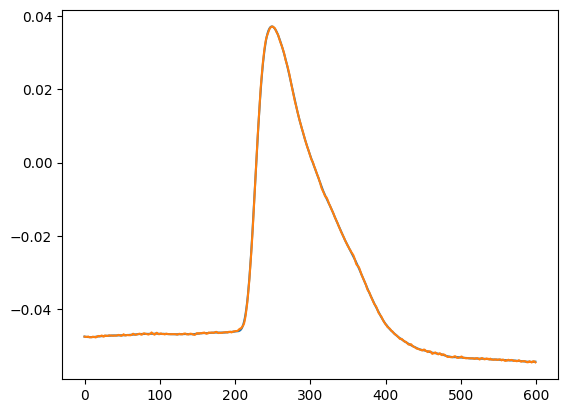

In [ ]:
plt.plot(smoothed)


In [ ]:
import numpy as np
from scipy.optimize import differential_evolution


def exp_decay(t, A, tau, C):
    return A * np.exp(-t / tau) + C


def decay_error(params, t, voltage):
    A, tau, C = params

    fitted = exp_decay(t, A, tau, C)

    return np.sum((voltage - fitted) ** 2)

A = []
tau = []
C = []

plot=False

for i in range(len(df)):
    tmp = df.iloc[i]

    arrs = tmp.rawData.T
    peaks = tmp.all_peaks

    # get the rheobase, the first injection that contains an AP (this time we keep the first trace with a detected action potential)
    for idx, peak in enumerate(peaks):
        if len(peak) != 0:
            break
    rheo = arrs[idx]

    try: #check, it could be that the series has NO action potentials, need to take care of this
        peak=peak[0]
    except:
        print(tmp.combo+' did not have any detected peaks, skipped and NaN-filled')
        A.append(np.nan)
        tau.append(np.nan)
        C.append(np.nan)
        continue

    wind=350

    from scipy.signal import savgol_filter

    wave = rheo[peak-wind+100:peak+wind]
    smoothed = savgol_filter(wave, window_length=25, polyorder=3)



    # Find AP peak
    peak_idx = np.argmax(smoothed)

    # Take everything after the peak
    decay = smoothed[peak_idx:]

    # Time in ms
    dt = 1000 / 40000
    t = np.arange(len(decay)) * dt


    # Bounds for A, tau, C
    voltage_range = np.ptp(decay)

    peak_voltage = decay[0]
    end_voltage = decay[-1]

    voltage_range = peak_voltage - end_voltage

    bounds = [
        (0.1 * voltage_range, 2 * voltage_range),  # A
        (0.05, 10),                                # tau, ms
        (end_voltage - voltage_range,
        end_voltage + 0.25 * voltage_range)      # C
    ]


    # Differential evolution
    result = differential_evolution(
        decay_error,
        bounds=bounds,
        args=(t, decay),
        seed=1, strategy='rand1exp', polish=True
    )
    
    if plot:
        xs = list(range(len(decay)))
        plt.plot(smoothed, label='original, smnoothed AP', c='b')
        plt.plot(t, decay, c='r', label='what is being fitted')
        
    A_fit, tau_fit, C_fit = result.x
    A.append(A_fit)
    tau.append(tau_fit)
    C.append(C_fit)
    #print("A =", A_fit)
    #print("tau =", tau_fit, "ms")
    #print("C =", C_fit)

    if plot:
        fit = exp_decay(
            t,
            A_fit,
            tau_fit,
            C_fit
        )
        #plt.plot(t, decay, label='Smoothed AP decay')
        plt.plot(t, fit, label=f'Exponential fit (τ = {tau_fit:.3f} ms)', c='k')
        plt.legend()
        plt.show()
df['A_fit'] = A
df['tau_fit'] = tau
df['C_fit'] = C_fit

6-5-26_1_1 did not have any detected peaks, skipped and NaN-filled


In [13]:
df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,rheo_AP_trace,smoothed_rheo_AP_trace,max_dvdt,min_dvdt,dvdt_ratio,voltage_at_max_dvdt,voltage_at_min_dvdt,A_fit,tau_fit,C_fit
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.059329
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[-0.048744220626428886, -0.04911893596756736, ...","[-0.048947314206195934, -0.048962793899775724,...",0.004039,-0.001181,3.419482,0.017308,0.030456,0.112502,1.450310,-0.059329
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,"[-0.045434235113039005, -0.045652819062036123,...","[-0.04553703095405951, -0.04549344760989438, -...",0.003521,-0.000982,3.587631,0.017611,0.028742,0.116703,1.839174,-0.059329
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,"[-0.0627960459191211, -0.0627648196406933, -0....","[-0.06297459617782622, -0.06293002533596725, -...",0.003917,-0.000977,4.008606,-0.008990,0.013641,0.114002,1.599403,-0.059329
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,"[-0.04933751991656506, -0.049556103865562404, ...","[-0.04944325156154044, -0.049455795451165435, ...",0.004374,-0.000819,5.342577,-0.000751,0.019369,0.107764,2.367330,-0.059329
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,"[-0.04755762204615695, -0.047620074603013575, ...","[-0.04754776842051976, -0.04758094300520888, -...",0.003772,-0.000955,3.950241,-0.004485,0.020195,0.106052,2.212695,-0.059329


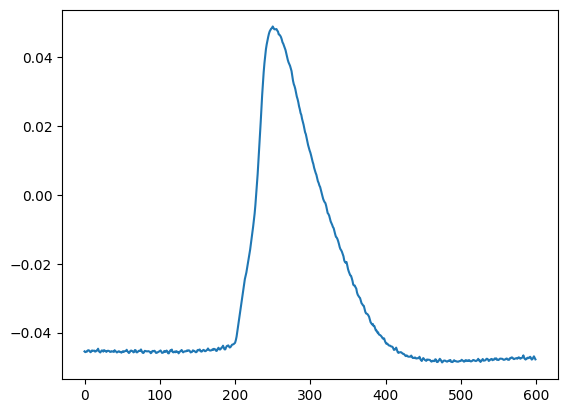

In [95]:
plt.plot(wave)

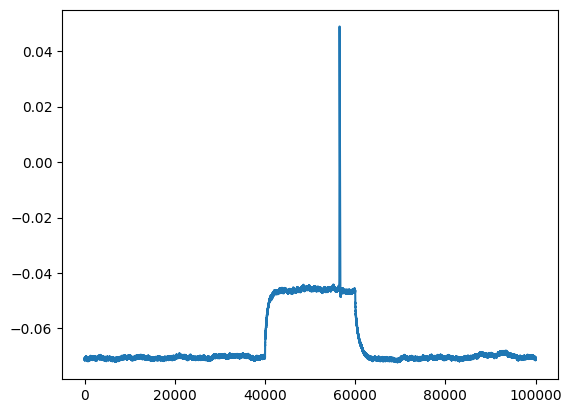

In [ ]:
# ------------------------------------------------------------
# Get AP
# ------------------------------------------------------------

tmp = df.iloc[2]

arrs = tmp.rawData.T
peaks = tmp.all_peaks

# First trace containing an AP
for idx, peak in enumerate(peaks):
    if len(peak) != 0:
        break

rheo = arrs[idx]
peak = peak[0]


# ------------------------------------------------------------
# Extract falling phase
# ------------------------------------------------------------

wind = 350

wave = rheo[peak - wind + 100 : peak + wind]

# Time in ms
sampling_rate = 40000
dt = 1000 / sampling_rate

t = np.arange(len(wave)) * dt

# Since the AP peak isn't necessarily the first point,
# you may instead want the portion AFTER the peak:
decay = rheo[peak : peak + 500]

t_decay = np.arange(len(decay)) * dt

plt.plot(rheo)
plt


In [8]:
from scipy.stats import linregress


plot=False

all_ssvs = []
all_ssvs_corr = []
IR_slope = []
for i in range(len(df)):
    tmp = df.iloc[i]

    peak_list = tmp.all_peaks
    raw_data = tmp.rawData.T
    curr_injs = tmp.corrected_injections
    for i in range(len(peak_list)):
        if len(peak_list[i]) != 0:
            break
    peak_list = peak_list[:i]
    raw_data=raw_data[:i]
    curr_injs = curr_injs[:i]

    if plot:
        for i in range(len(raw_data)):
            plt.plot(raw_data[i])
        plt.title(tmp.combo)
        plt.show()

    ssvs = []
    ssvs_corr = []
    for i in range(len(raw_data)):
        ssvs.append(np.median(raw_data[i][len(raw_data[i])//2-7500:len(raw_data[i])//2+7500]))
        ssvs_corr.append(np.median(raw_data[i][len(raw_data[i])//2-7500:len(raw_data[i])//2+7500])-np.median(raw_data[i][:35000]))
    all_ssvs.append(ssvs)
    all_ssvs_corr.append(ssvs_corr)


    curr_injs = np.array(curr_injs)
    ssvs_corr = np.array(ssvs_corr)


    model = linregress(curr_injs, ssvs_corr)
    if plot:
        plt.plot(curr_injs, ssvs_corr)
        plt.scatter(curr_injs, ssvs_corr)
        plt.plot(curr_injs, model.intercept+model.slope*curr_injs, c='r', label='IR slope= '+str(round(model.slope*1e6, 3))+'MOhm')
        plt.axhline(0, c='k', ls=':')
        plt.axvline(0, c='k', ls=':')
        plt.ylabel('Delta Voltage')
        plt.xlabel('Delta Current')
        plt.legend()
        plt.title(tmp.combo)
        plt.show()

    IR_slope.append(model.slope*1e6)

df['ssvs'] = [x for x in all_ssvs]
df['ssvs_delta'] = [x for x in all_ssvs_corr]
df['IR_slope'] = IR_slope


In [33]:
df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,stimWave,fname,all_freqs,all_peaks,combo,current_injections,corrected_injections,ssvs,ssvs_delta,IR_slope
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_1_1,"[-350.0, -339.99999999999994, -329.99999999999...","[-77.37818041685318, -67.37818041685313, -57.3...","[-0.0771601339960961, -0.08143813414076014, -0...","[-0.00874335795989753, -0.008805810516753831, ...",121.672679
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_1,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.69512663330609, -51.69512663330609, -41.6...","[-0.08565368172856774, -0.08490425104629096, -...","[-0.01626889106109501, -0.015425781543533593, ...",316.078567
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[10.0, 10.0, 6.0, 4.0, 4.0, 2.0, 4.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_2,"[-150.0, -139.99999999999997, -130.0, -120.0, ...","[-133.98710739326438, -123.98710739326435, -11...","[-0.10851131753801432, -0.10641915688332458, -...","[-0.03909530059211319, -0.03731540272170572, -...",317.007770
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[8.0, 8.0, 6.0, 6.0, 8.0, 8.0, 10.0, 10.0, 4.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_3_1,"[-200.0, -190.0, -180.00000000000003, -170.0, ...","[-133.03699455365103, -123.03699455365104, -11...","[-0.11559968274121708, -0.11413204765509147, -...","[-0.04627734463060046, -0.04590262928946194, -...",363.587153
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 12.0, 20.0, 0.0, 0.0, 8.0, 0.0, 0.0, 6.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_4_1,"[-170.0, -160.0, -150.00000000000003, -140.0, ...","[-142.0316401859144, -132.0316401859144, -122....","[-0.16443758220293075, -0.18064402070716962, -...","[-0.0951776966491704, -0.11016631029470973, -0...",667.477008
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,"[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[4.0, 10.0, 12.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [1279...",6-5-26_4_2,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.10664508683031, -51.10664508683031, -41.1...","[-0.1092607482202913, -0.10704368245188861, -0...","[-0.03959492104696444, -0.03587899391400787, -...",712.697224


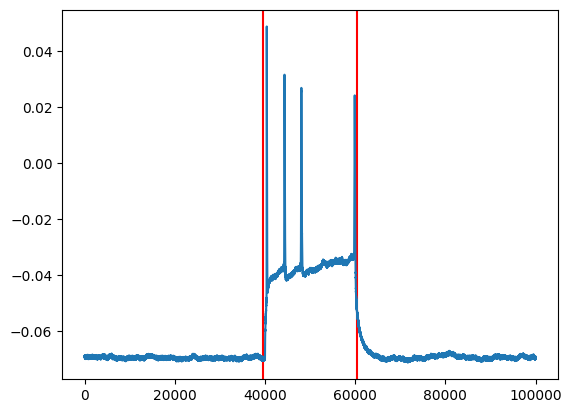

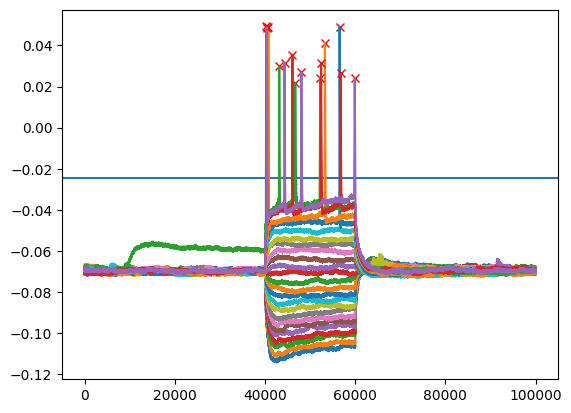

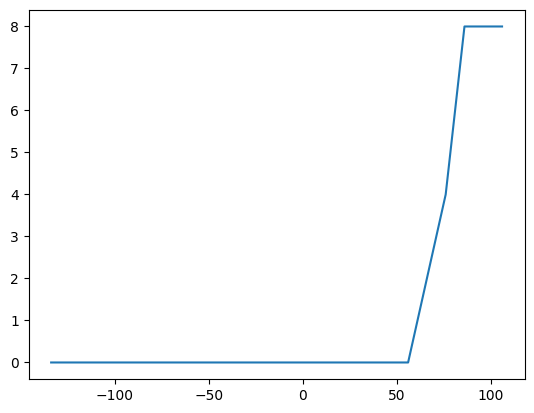

In [137]:
arrs = df.iloc[2].rawData.T
currs = df.iloc[2].corrected_injections
#for idx, arr in enumerate(arrs):
#    plt.plot(arr)



#plt.ylabel('Voltage')
#current_ticks, _ = plt.xticks()

#plt.xticks(
#    current_ticks,
#    [f"{x / 40000:.2f}" for x in current_ticks]
#)
#plt.margins(x=0)
#plt.show()

from scipy.signal import find_peaks

wind=10500

plt.axvline(mid-wind, c='r')
plt.axvline(mid+wind, c='r')
plt.plot(arr)

plt.show()
plt.axhline(np.mean(arr[mid-200:mid+200]) + np.std(arr[mid-200:mid+200])*50)
height = np.mean(arr[mid-200:mid+200]) + np.std(arr[mid-200:mid+200])*50
peak_num = []
for idx, arr in enumerate(arrs):
    mid = len(arr)//2
    peaks, _ = find_peaks(arr[mid-wind:mid+wind], height=height, distance=250)
    peaks += mid - wind
    plt.plot(peaks, arr[peaks], 'x', c='r')
    plt.plot(arr)
    peak_num.append(len(peaks)/.5)
plt.show()
plt.plot(currs, peak_num)

    






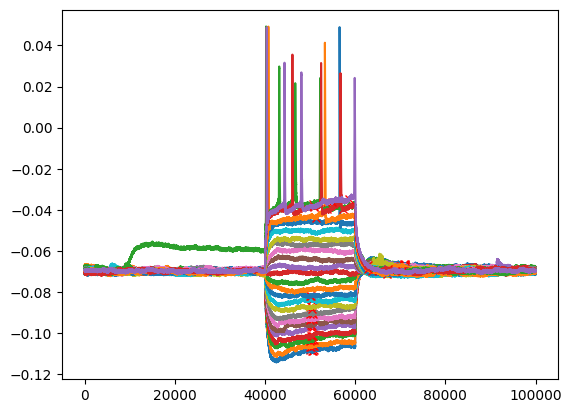

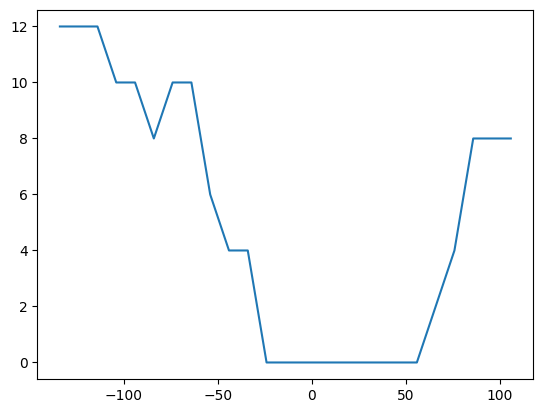

In [131]:
peak_num = []

for idx, arr in enumerate(arrs):

    height = (
        np.mean(arr[mid-200:mid+200])
        + np.std(arr[mid-200:mid+200]) * 50
    )

    peaks, _ = find_peaks(
        arr[mid-wind:mid+wind],
        height=height,
        distance=250
    )

    peaks += mid

    plt.plot(peaks, arr[peaks], 'x', c='r')
    plt.plot(arr)

    peak_num.append(len(peaks) / 0.5)

plt.show()

plt.plot(currs, peak_num)

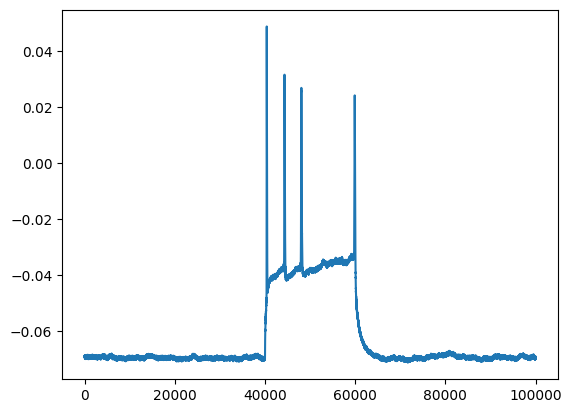

In [134]:
plt.plot(arr)

In [133]:
# version A
peaks, _ = find_peaks(arr, height=height, distance=250)
peaks

array([40385, 44325, 48065, 59893])

In [136]:
# version B
peaks, _ = find_peaks(
    arr[mid-wind:mid+wind],
    height=height,
    distance=250
)
peaks += mid
peaks

array([50885, 54825, 58565, 70393])

In [32]:
stri = '6-5-26struct.mat'
stri[:stri.find('struct')]

'6-5-26'

In [6]:
def get_date(stri):
    return stri[:stri.find('struct')]

combo = []
for i in range(len(df)):
    date = get_date(df.iloc[i].fname)
    combo.append(date+'_'+str(df.iloc[i].experiment)+'_'+str(df.iloc[i].series_num))
df['combo'] = combo
df



,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,temperature,external_sol,internal_sol,SR,rawData,stimWave,fname,all_freqs,all_peaks,combo
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,20.0,NaN,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_1_1
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,20.0,NaN,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_1
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,20.0,NaN,NaN,40000.0,"[[-0.07019667390660614, -0.06757366651863697, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[10.0, 10.0, 6.0, 4.0, 4.0, 2.0, 4.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_2
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,20.0,NaN,NaN,40000.0,"[[-0.06747998768335235, -0.06872903882048094, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[8.0, 8.0, 6.0, 6.0, 8.0, 8.0, 10.0, 10.0, 4.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_3_1
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,20.0,NaN,NaN,40000.0,"[[-0.06950969578118574, -0.06994686367918052, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 12.0, 20.0, 0.0, 0.0, 8.0, 0.0, 0.0, 6.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_4_1
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,20.0,NaN,NaN,40000.0,"[[-0.0704464841340318, -0.07010299507132141, -...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[4.0, 10.0, 12.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [1279...",6-5-26_4_2


In [7]:
injections = []
corr_injections = []
for i in range(len(df)):
    arrs = df.iloc[i].stimWave.T
    hold = df.iloc[i].Vhold*1e12
    tmp = []
    tmp2 = []
    for arr in arrs:
        tmp.append(arr[len(arr)//2]*1000)
        tmp2.append(arr[len(arr)//2]*1000 - hold)
    injections.append(tmp)
    corr_injections.append(tmp2)
df['current_injections'] = [x for x in injections]
df['corrected_injections'] = [x for x in corr_injections]
df

,experiment,exp_name,series_num,rseries,Cmvals,Nsweeps,Vhold,Rseries_uncomp,Rseries_frac,series_name,...,internal_sol,SR,rawData,stimWave,fname,all_freqs,all_peaks,combo,current_injections,corrected_injections
0,1,E,1,5.001429e+07,0.0,15,-2.726218e-10,5.001429e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.06826064464405736, -0.07269477618086281, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_1_1,"[-350.0, -339.99999999999994, -329.99999999999...","[-77.37818041685318, -67.37818041685313, -57.3..."
1,2,E,1,1.782437e+07,0.0,15,-1.830487e-11,1.782437e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.07044648413403186, -0.06947846950275743, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_1,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.69512663330609, -51.69512663330609, -41.6..."
2,2,E,2,2.028387e+07,0.0,25,-1.601289e-11,2.028387e+07,0.0,Garrett,...,NaN,40000.0,"[[-0.07019667390660614, -0.06757366651863697, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[10.0, 10.0, 6.0, 4.0, 4.0, 2.0, 4.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_2_2,"[-150.0, -139.99999999999997, -130.0, -120.0, ...","[-133.98710739326438, -123.98710739326435, -11..."
3,3,E,1,2.799497e+07,0.0,25,-6.696301e-11,2.799497e+07,0.0,Garrett,...,NaN,40000.0,"[[-0.06747998768335235, -0.06872903882048094, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[8.0, 8.0, 6.0, 6.0, 8.0, 8.0, 10.0, 10.0, 4.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_3_1,"[-200.0, -190.0, -180.00000000000003, -170.0, ...","[-133.03699455365103, -123.03699455365104, -11..."
4,4,E,1,4.912459e+07,0.0,25,-2.796836e-11,4.912459e+07,0.0,Garrett,...,NaN,40000.0,"[[-0.06950969578118574, -0.06994686367918052, ...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[0.0, 12.0, 20.0, 0.0, 0.0, 8.0, 0.0, 0.0, 6.0...","[[], [], [], [], [], [], [], [], [], [], [], [...",6-5-26_4_1,"[-170.0, -160.0, -150.00000000000003, -140.0, ...","[-142.0316401859144, -132.0316401859144, -122...."
5,4,E,2,7.463523e+07,0.0,15,-1.889335e-11,7.463523e+07,0.0,Rudi,...,NaN,40000.0,"[[-0.0704464841340318, -0.07010299507132141, -...","[[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0,...",6-5-26struct.mat,"[4.0, 10.0, 12.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0...","[[], [], [], [], [], [], [], [], [], [], [1279...",6-5-26_4_2,"[-80.0, -70.0, -60.0, -50.0, -40.0, -30.0, -19...","[-61.10664508683031, -51.10664508683031, -41.1..."


In [28]:
df.iloc[0].Vhold*1e12

np.float64(-272.6218195831468)

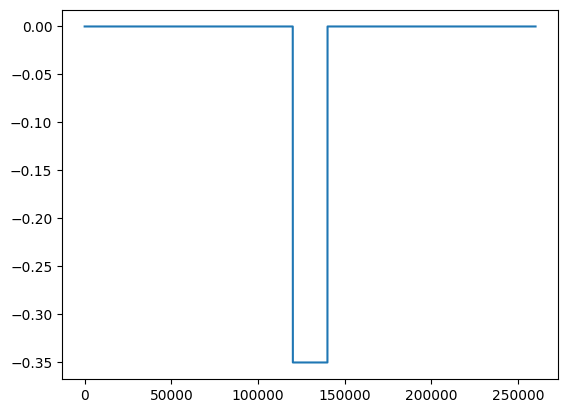

In [17]:
plt.plot(df.iloc[0].stimWave.T[0])

In [12]:
np.array(df.Vhold)*1e12

array([-272.62181958,  -18.30487337,  -16.01289261,  -66.96300545,
        -27.96835981,  -18.89335491])